# Comprobación y contraste de resultados

Este cuaderno comprueba las métricas propias y conserva el contraste documental
con siete antecedentes. **Funciona de forma independiente** del cuaderno de extracción:
no utiliza su muestra, sus dictámenes, sus PDF ni sus archivos de salida.

La red histórica incluye **802 actores, 146 conflictos y 1.770 vínculos distintos**.
Los recuentos, densidades y componentes de **198 redes** coinciden con las tablas de
referencia del repositorio. El contraste bibliográfico es interpretativo; el código
calcula las cifras propias y presenta los hallazgos publicados con sus fuentes.

**Uso:** abrir con un núcleo nuevo de Python 3.12 y ejecutar las celdas en orden.
Se utiliza el Excel completo del repositorio o el CSV equivalente. Si falta la base,
puede descargarse su versión pública de referencia. Las tablas de comparación ya
están incorporadas. Las salidas se guardan en `salidas_validacion_resultados/`.

### Fuente y diferencia entre particiones

Se conserva la versión [`b2736d1`](https://github.com/MarSury03/conflictos_mineros_peru_grafos/tree/b2736d1271dd1096d842ae889aa93c89f88d37f4)
de [MarSury03/conflictos_mineros_peru_grafos](https://github.com/MarSury03/conflictos_mineros_peru_grafos).
La base Excel y el CSV de referencia contienen los mismos 21.327 registros.

Las particiones comunitarias guardadas en el repositorio presentan modularidad mensual
máxima de **0,5441**; la reconstrucción con identificadores ordenados de la comprobación
anterior alcanza **0,5395**. El cuaderno calcula y distingue ambas referencias. No se
deben intercambiar sus valores sin identificar la partición utilizada. Esta diferencia
no afecta los recuentos ni las densidades.

## 1. Preparación

Esta celda instala únicamente las versiones requeridas que falten o sean diferentes.
La primera ejecución necesita conexión a internet si hay que instalar bibliotecas.
En Jupyter o Google Colab debe utilizarse un entorno de Python 3.12.

In [1]:
import sys
import subprocess
import importlib
from importlib.metadata import version, PackageNotFoundError

if sys.version_info < (3, 12):
    raise RuntimeError("Utilice Python 3.12 o posterior; la ejecución de referencia usó Python 3.12.")

VERSIONES_REQUERIDAS = {'pandas': '3.0.1', 'networkx': '3.7', 'matplotlib': '3.11.2', 'openpyxl': '3.1.5'}
instalar = []
for paquete, requerida in VERSIONES_REQUERIDAS.items():
    try:
        instalada = version(paquete)
    except PackageNotFoundError:
        instalada = None
    if instalada != requerida:
        instalar.append(f"{paquete}=={requerida}")
if instalar:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *instalar])
    importlib.invalidate_caches()
print("Bibliotecas disponibles en las versiones de referencia.")

Bibliotecas disponibles en las versiones de referencia.


In [2]:
import hashlib
import io
import json
import platform
import urllib.parse
import urllib.request
from collections import Counter, defaultdict
from datetime import datetime, timezone
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

import math
from itertools import combinations
import networkx as nx
import matplotlib.dates as mdates

pd.set_option("display.max_columns", 10)
pd.set_option("display.max_colwidth", 70)
pd.set_option("display.max_rows", 30)
plt.rcParams.update({
    "figure.figsize": (9, 4), "figure.dpi": 130, "font.size": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 13,
})
CLAVE = ["periodo_reporte", "id_caso", "Id_actor"]
entorno = {"Python": platform.python_version(),
           **{p: version(p) for p in VERSIONES_REQUERIDAS}}
display(pd.Series(entorno, name="Versión ejecutada").to_frame())

,Versión ejecutada
Python,3.12.14
pandas,3.0.1
networkx,3.7
matplotlib,3.11.2
openpyxl,3.1.5


### Parámetros y alcance

Se fija la semilla **42** y resolución **1** para las comunidades ponderadas de actores.
Se conserva un orden estable de inserción de nodos y aristas. Las comprobaciones
numéricas se distinguen de la comparación interpretativa con antecedentes.
Los vínculos representan participación documentada: no prueban interacción directa,
cooperación, influencia efectiva ni causalidad entre conflictos.

In [3]:
# None permite localizar la base del repositorio; puede indicar aquí un CSV o XLSX.
RUTA_DATOS = None
RAIZ_REPO = next((p for p in [Path.cwd(), *list(Path.cwd().parents)[:3]]
                  if (p / "fase1_base_longitudinal").is_dir()
                  and (p / "fases2_5_analisis_grafos").is_dir()), Path.cwd())
RUTA_SALIDAS = Path("salidas_validacion_resultados")
DESCARGAR_BASE_SI_FALTA = True
REPOSITORIO = "MarSury03/conflictos_mineros_peru_grafos"
COMMIT_REFERENCIA = "b2736d1271dd1096d842ae889aa93c89f88d37f4"
RUTA_BASE_REPO = "fase1_base_longitudinal/resultados/FASE1_MINERIA_CON_IDS_ACTORES_Y_CASOS.xlsx"
URL_BASE_REPO = f"https://raw.githubusercontent.com/{REPOSITORIO}/{COMMIT_REFERENCIA}/{RUTA_BASE_REPO}"
SHA256_EXCEL_REPO = "0dfea7e573735e4edf07d7cb0c3ac2870ceec44eb5dbf29b0f8bf5a4e4dcc218"


SEMILLA_COMUNIDADES = 42
RESOLUCION_COMUNIDADES = 1.0

if RUTA_DATOS is None:
    nombre_csv = "FASE1_MINERIA_CON_IDS_ACTORES_Y_CASOS.csv"
    candidatos = [Path(nombre_csv), RAIZ_REPO / RUTA_BASE_REPO,
                  Path("datos") / nombre_csv, Path("data") / nombre_csv,
                  Path("..") / nombre_csv]
    RUTA_DATOS = next((p for p in candidatos if p.is_file()), None)
    if RUTA_DATOS is None:
        RUTA_DATOS = Path("insumos_validacion") / Path(RUTA_BASE_REPO).name
        if not RUTA_DATOS.is_file():
            if not DESCARGAR_BASE_SI_FALTA:
                raise FileNotFoundError("Indique RUTA_DATOS o habilite la descarga de la base de referencia.")
            with urllib.request.urlopen(URL_BASE_REPO, timeout=60) as respuesta:
                contenido = respuesta.read()
            if hashlib.sha256(contenido).hexdigest() != SHA256_EXCEL_REPO:
                raise ValueError("La descarga de la base no coincide con la versión revisada.")
            RUTA_DATOS.parent.mkdir(parents=True, exist_ok=True)
            RUTA_DATOS.write_bytes(contenido)
RUTA_DATOS = Path(RUTA_DATOS)
if not RUTA_DATOS.is_file():
    raise FileNotFoundError(f"No se encuentra la base indicada: {RUTA_DATOS}")
RUTA_SALIDAS.mkdir(parents=True, exist_ok=True)

def guardar_json(nombre, contenido):
    (RUTA_SALIDAS / nombre).write_text(
        json.dumps(contenido, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")

def huella_archivo(ruta):
    return hashlib.sha256(Path(ruta).read_bytes()).hexdigest()

def huella_contenido(tabla):
    # Tolera cambios de BOM y de finales de línea que puede introducir Git.
    # Conserva orden, columnas y todos los valores; no permite cambiar registros.
    contenido = {
        "columnas": list(tabla.columns),
        "registros": [[v.replace("\r\n", "\n").replace("\r", "\n") for v in fila]
                      for fila in tabla.itertuples(index=False, name=None)],
    }
    serializado = json.dumps(contenido, ensure_ascii=False, separators=(",", ":"))
    return hashlib.sha256(serializado.encode("utf-8")).hexdigest()

## 2. Identidad y recuentos de la base

Se comprueba la versión de los datos frente a las tablas incorporadas. La clave mensual
es `(periodo_reporte, id_caso, Id_actor)`. Cada relación se cuenta una sola vez al
construir la red, conservando como nodos los identificadores originales.
No se aplican correcciones ni fusiones de actores por semejanza de nombres.

In [4]:
SHA256_ARCHIVO_REFERENCIA = '1aaf6248848669126a5d8fe58381575d4105af19c28d84a61fd61a5ca503d126'
SHA256_CONTENIDO_REFERENCIA = '4610ae71308f126e618c28a65328ee7afac9b150f02dc4e12b950c88035c3ed9'
if RUTA_DATOS.suffix.lower() == ".csv":
    datos = pd.read_csv(RUTA_DATOS, dtype=str, keep_default_na=False, encoding="utf-8-sig")
elif RUTA_DATOS.suffix.lower() == ".xlsx":
    datos = pd.read_excel(RUTA_DATOS, sheet_name="Base final fase 1", dtype=str, keep_default_na=False)
else:
    raise ValueError("Se admite el CSV completo o el Excel 'Base final fase 1'.")
requeridas = set(CLAVE + ["reporte", "pagina_pdf", "caso", "ubicacion", "tipo_actor",
                         "actor", "Actor_normalizado", "bloque_actores_original"])
if requeridas - set(datos.columns):
    raise ValueError(f"Faltan columnas: {sorted(requeridas - set(datos.columns))}")
if datos[CLAVE].apply(lambda c: c.str.strip().eq("").any()).any():
    raise ValueError("Hay valores vacíos en la clave de la relación mensual.")

sha256_base = huella_archivo(RUTA_DATOS)
sha256_contenido = huella_contenido(datos)
if sha256_contenido != SHA256_CONTENIDO_REFERENCIA:
    raise ValueError("La base tiene otro contenido y no corresponde a las tablas de referencia incorporadas.")
if RUTA_DATOS.suffix.lower() == ".xlsx":
    print("La base Excel coincide celda por celda con el contenido del CSV revisado.")
elif sha256_base != SHA256_ARCHIVO_REFERENCIA:
    print("Cambió la codificación o el formato de líneas; el contenido tabular coincide con la referencia.")

relaciones = datos.drop_duplicates(CLAVE).copy()
perfil = {
    "Registros documentales": len(datos),
    "Duplicados exactos de fila": int(datos.duplicated().sum()),
    "Relaciones mensuales únicas": len(relaciones),
    "Ocurrencias adicionales de la clave mensual": len(datos) - len(relaciones),
    "Unidades conflicto–mes": len(datos.drop_duplicates(CLAVE[:2])),
    "Identificadores de actor": int(datos.Id_actor.nunique()),
    "Identificadores de conflicto": int(datos.id_caso.nunique()),
    "Meses": int(datos.periodo_reporte.nunique()),
}
display(pd.Series(perfil, name="Recuento").to_frame())
print("Intervalo:", datos.periodo_reporte.min(), "a", datos.periodo_reporte.max())
print("Huella SHA-256 del contenido:", sha256_contenido)

La base Excel coincide celda por celda con el contenido del CSV revisado.


,Recuento
Registros documentales,21327
Duplicados exactos de fila,0
Relaciones mensuales únicas,20913
Ocurrencias adicionales de la clave mensual,414
Unidades conflicto–mes,1423
Identificadores de actor,802
Identificadores de conflicto,146
Meses,60


Intervalo: 2021-01 a 2025-12
Huella SHA-256 del contenido: 4610ae71308f126e618c28a65328ee7afac9b150f02dc4e12b950c88035c3ed9


## 3. Comprobación de las métricas utilizadas en el contraste

Esta sección reproduce los cálculos propios usados para revisar las cifras del contraste
con antecedentes. En la red bipartita histórica, un vínculo actor–conflicto existe si está
registrado al menos una vez durante 2021–2025. En la proyección de actores, el peso es el
número de conflictos compartidos; en la de conflictos, es el número de actores compartidos.
Compartir un caso no demuestra interacción directa, cooperación ni influencia efectiva.

La densidad bipartita divide los vínculos entre actores × conflictos; la densidad de las
proyecciones divide las aristas entre los pares posibles. La fuerza suma pesos y el grado
normalizado divide los vecinos entre los demás nodos de la misma proyección. La
intermediación principal se calcula sin ponderación y normalizada. Se muestra aparte
una variante cuya distancia es el inverso del peso, para no confundir ambas definiciones.

In [5]:
def construir_bipartita(pares):
    grafo = nx.Graph()
    # Orden estable para fijar la reproducción de algoritmos sensibles al orden de inserción.
    for actor, caso in sorted(pares):
        grafo.add_node(actor, bipartite=0)
        grafo.add_node(caso, bipartite=1)
        grafo.add_edge(actor, caso)
    return grafo

def proyectar(grafo, tipo):
    propios = sorted(n for n, d in grafo.nodes(data=True) if d["bipartite"] == tipo)
    opuestos = sorted(set(grafo) - set(propios))
    pesos = Counter()
    for nodo in opuestos:
        pesos.update(combinations(sorted(grafo[nodo]), 2))
    proyeccion = nx.Graph()
    proyeccion.add_nodes_from(propios)
    proyeccion.add_weighted_edges_from((a, b, w) for (a, b), w in sorted(pesos.items()))
    return proyeccion

por_mes, por_anio = defaultdict(set), defaultdict(set)
for periodo, caso, actor in relaciones[CLAVE].itertuples(index=False, name=None):
    por_mes[periodo].add((actor, caso))
    por_anio[periodo[:4]].add((actor, caso))
pares_historicos = set().union(*por_mes.values())
red_historica = construir_bipartita(pares_historicos)
proyeccion_actores = proyectar(red_historica, 0)
proyeccion_conflictos = proyectar(red_historica, 1)
nombres = datos.drop_duplicates("Id_actor").set_index("Id_actor").Actor_normalizado.to_dict()

In [6]:
def resumen_bipartita(grafo):
    n_actores = sum(d["bipartite"] == 0 for _, d in grafo.nodes(data=True))
    n_conflictos = len(grafo) - n_actores
    componentes = sorted(map(len, nx.connected_components(grafo)), reverse=True)
    return {"actores": n_actores, "conflictos": n_conflictos, "nodos": len(grafo),
        "aristas": grafo.number_of_edges(), "componentes": len(componentes),
        "componente_mayor": componentes[0] if componentes else 0,
        "densidad_bipartita": grafo.number_of_edges() / (n_actores * n_conflictos) if n_actores * n_conflictos else 0}

resumen_historico = resumen_bipartita(red_historica)
tabla_redes = pd.DataFrame([
    {"Red histórica": "Bipartita", "Nodos": len(red_historica), "Aristas": red_historica.number_of_edges(),
     "Densidad": resumen_historico["densidad_bipartita"]},
    {"Red histórica": "Proyección de actores", "Nodos": len(proyeccion_actores),
     "Aristas": proyeccion_actores.number_of_edges(), "Densidad": nx.density(proyeccion_actores)},
    {"Red histórica": "Proyección de conflictos", "Nodos": len(proyeccion_conflictos),
     "Aristas": proyeccion_conflictos.number_of_edges(), "Densidad": nx.density(proyeccion_conflictos)},
])
display(tabla_redes.style.format({"Densidad": "{:.6f}"}).hide(axis="index"))
tabla_redes.to_csv(RUTA_SALIDAS / "metricas_redes_historicas.csv", index=False, encoding="utf-8-sig")

Red histórica,Nodos,Aristas,Densidad
Bipartita,948,1770,0.015116
Proyección de actores,802,9458,0.029446
Proyección de conflictos,146,9615,0.908361


### Centralidad histórica

El orden principal de la tabla usa fuerza descendente y, en caso de empate, intermediación
simple e identificador. Las cifras de los antecedentes se contrastan con la definición de
la métrica correspondiente, sin equiparar medidas brutas, normalizadas o ponderadas distintas.

In [7]:
intermediacion = nx.betweenness_centrality(proyeccion_actores, normalized=True, weight=None)
nx.set_edge_attributes(proyeccion_actores,
    {(a, b): 1 / d["weight"] for a, b, d in proyeccion_actores.edges(data=True)}, "distancia")
intermediacion_ponderada = nx.betweenness_centrality(proyeccion_actores, normalized=True, weight="distancia")
fuerza = dict(proyeccion_actores.degree(weight="weight"))
orden = sorted(proyeccion_actores, key=lambda a: (-fuerza[a], -intermediacion[a], a))
centralidades = pd.DataFrame([{
    "ID": actor, "Actor": nombres[actor], "Conflictos": red_historica.degree(actor),
    "Vecinos": proyeccion_actores.degree(actor),
    "Grado normalizado": proyeccion_actores.degree(actor) / (len(proyeccion_actores) - 1),
    "Fuerza": fuerza[actor], "Intermediación simple": intermediacion[actor],
    "Intermediación ponderada": intermediacion_ponderada[actor],
} for actor in orden])
display(centralidades.head(10).style.format({
    "Grado normalizado": "{:.4f}", "Intermediación simple": "{:.4f}",
    "Intermediación ponderada": "{:.4f}"}).hide(axis="index"))
centralidades.to_csv(RUTA_SALIDAS / "centralidades_historicas.csv", index=False, encoding="utf-8-sig")

ID,Actor,Conflictos,Vecinos,Grado normalizado,Fuerza,Intermediación simple,Intermediación ponderada
ACT-045,Defensoría del Pueblo,121,706,0.8814,1393,0.4114,0.5277
ACT-148,Secretaría de Gestión Social y Diálogo de la Presidencia del Consejo de Ministros (SGSD-PCM),95,574,0.7166,1205,0.1777,0.2249
ACT-114,Oficina General de Gestión Social del Ministerio de Energía y Minas (OGGS-MINEM),78,432,0.5393,828,0.1013,0.0777
ACT-095,Ministerio de Energía y Minas (MINEM),58,407,0.5081,795,0.0852,0.0938
ACT-121,Organismo de Evaluación y Fiscalización Ambiental (OEFA),44,310,0.3870,615,0.0471,0.0526
ACT-017,Autoridad Nacional del Agua (ANA),32,244,0.3046,463,0.0214,0.0143
ACT-091,Ministerio del Ambiente (MINAM),24,234,0.2921,427,0.0205,0.0138
ACT-130,Policía Nacional del Perú (PNP),30,227,0.2834,401,0.0262,0.0130
ACT-096,Ministerio del Interior (MININTER),32,195,0.2434,384,0.0175,0.0089
ACT-092,Ministerio de Desarrollo Agrario y Riego (MIDAGRI),13,176,0.2197,271,0.0077,0.0044


### Recurrencia y conexiones compartidas

La presencia en varios años es recurrencia documental y puede ser discontinua.
Para la Defensoría se cuentan los pares de conflictos que comparten ese actor;
esos pares pueden compartir simultáneamente otros participantes, por lo que la cantidad
no equivale a una contribución exclusiva de la institución.

In [8]:
meses_por_par, anios_por_par = defaultdict(set), defaultdict(set)
for periodo, caso, actor in relaciones[CLAVE].itertuples(index=False, name=None):
    meses_por_par[(actor, caso)].add(periodo)
    anios_por_par[(actor, caso)].add(periodo[:4])
frecuencias = pd.Series([len(v) for v in meses_por_par.values()], dtype="int64")
multianuales = sum(len(v) > 1 for v in anios_por_par.values())
cinco_anios = sum(len(v) == 5 for v in anios_por_par.values())
recurrencia = {"Pares actor–conflicto históricos": len(pares_historicos),
    "Pares registrados en más de un año": multianuales,
    "Proporción registrada en más de un año": multianuales / len(pares_historicos),
    "Pares registrados en los cinco años": cinco_anios,
    "Media de meses registrados por par": float(frecuencias.mean()),
    "Mediana de meses registrados por par": float(frecuencias.median())}
lectura_recurrencia = pd.DataFrame([
    {"Indicador": k, "Resultado": f"{v:.1%}" if k.startswith("Proporción") else
     f"{v:.2f}" if "Media" in k or "Mediana" in k else str(v)}
    for k, v in recurrencia.items()])
display(lectura_recurrencia)

ID_DEFENSORIA, ID_SGSD, ID_OGGS = "ACT-045", "ACT-148", "ACT-114"
conflictos_defensoria = set(red_historica[ID_DEFENSORIA])
pares_defensoria = set(combinations(sorted(conflictos_defensoria), 2))
aristas_conflictos = proyeccion_conflictos.number_of_edges()
proporcion_pares_defensoria = len(pares_defensoria) / aristas_conflictos
conexiones_defensoria = {"Conflictos con Defensoría": len(conflictos_defensoria),
    "Pares de conflictos que comparten a la Defensoría": len(pares_defensoria),
    "Pares conectados en toda la proyección de conflictos": aristas_conflictos,
    "Proporción de pares conectados que comparten a la Defensoría": proporcion_pares_defensoria}
display(pd.DataFrame([{"Indicador": k, "Resultado": f"{v:.1%}" if k.startswith("Proporción") else str(v)}
                      for k, v in conexiones_defensoria.items()]))

,Indicador,Resultado
0,Pares actor–conflicto históricos,1770
1,Pares registrados en más de un año,1010
2,Proporción registrada en más de un año,57.1%
3,Pares registrados en los cinco años,240
4,Media de meses registrados por par,11.82
5,Mediana de meses registrados por par,7.00


,Indicador,Resultado
0,Conflictos con Defensoría,121
1,Pares de conflictos que comparten a la Defensoría,7260
2,Pares conectados en toda la proyección de conflictos,9615
3,Proporción de pares conectados que comparten a la Defensoría,75.5%


### Comunidades mensuales y presencia en el grupo de mayor fuerza

Se calculan las comunidades de las 60 proyecciones mensuales de actores. Se fija la
versión de NetworkX, el orden de inserción, la resolución y la semilla porque una misma
red puede admitir distintas particiones. La modularidad se interpreta respecto de
la coparticipación en conflictos, no como una medida directa de afinidad política.
El grupo de los diez actores de mayor fuerza se ordena por fuerza e identificador.

In [9]:
def comunidades_y_modularidad(proyeccion):
    grupos = nx.community.louvain_communities(proyeccion, weight="weight",
        resolution=RESOLUCION_COMUNIDADES, seed=SEMILLA_COMUNIDADES)
    q = nx.community.modularity(proyeccion, grupos, weight="weight", resolution=RESOLUCION_COMUNIDADES)
    return grupos, q

metricas_mensuales = []
particiones_mensuales = []
meses_top10 = Counter()
for periodo, pares in sorted(por_mes.items()):
    bipartita = construir_bipartita(pares)
    proyeccion = proyectar(bipartita, 0)
    grupos, q = comunidades_y_modularidad(proyeccion)
    fuerzas_mes = dict(proyeccion.degree(weight="weight"))
    meses_top10.update(sorted(proyeccion, key=lambda a: (-fuerzas_mes[a], a))[:10])
    metricas_mensuales.append({"Periodo": periodo, **resumen_bipartita(bipartita),
        "Comunidades": len(grupos), "Modularidad": q})
    particiones_mensuales.extend({"periodo": periodo, "Id_actor": a, "comunidad": i}
                                 for i, grupo in enumerate(grupos) for a in sorted(grupo))
mensuales = pd.DataFrame(metricas_mensuales)
q_min, q_max = float(mensuales.Modularidad.min()), float(mensuales.Modularidad.max())
grupos_historicos, q_historica = comunidades_y_modularidad(proyeccion_actores)
display(mensuales.loc[mensuales.Modularidad.isin([q_min, q_max]),
    ["Periodo", "actores", "Comunidades", "Modularidad"]].style.format({"Modularidad": "{:.6f}"}).hide(axis="index"))
display(pd.DataFrame([{"Actor": nombres[a], "Meses entre los diez de mayor fuerza": meses_top10[a]}
    for a in [ID_DEFENSORIA, ID_SGSD, ID_OGGS, "ACT-095", "ACT-121"]]))
print(f"Referencia histórica con estos parámetros: {len(grupos_historicos)} comunidades; Q = {q_historica:.6f}.")
mensuales.to_csv(RUTA_SALIDAS / "metricas_mensuales.csv", index=False, encoding="utf-8-sig")
pd.DataFrame(particiones_mensuales).to_csv(RUTA_SALIDAS / "comunidades_mensuales.csv", index=False, encoding="utf-8-sig")

Periodo,actores,Comunidades,Modularidad
2023-01,65,3,0.206136
2025-12,228,10,0.539476


,Actor,Meses entre los diez de mayor fuerza
0,Defensoría del Pueblo,60
1,Secretaría de Gestión Social y Diálogo de la Presidencia del Conse...,60
2,Oficina General de Gestión Social del Ministerio de Energía y Mina...,60
3,Ministerio de Energía y Minas (MINEM),59
4,Organismo de Evaluación y Fiscalización Ambiental (OEFA),57


Referencia histórica con estos parámetros: 15 comunidades; Q = 0.425256.


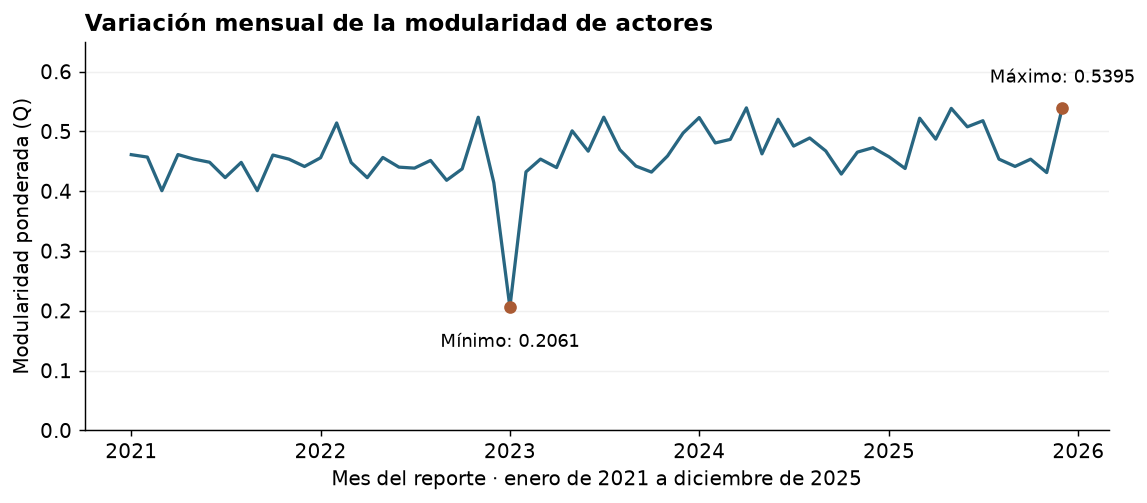

In [10]:
fechas = pd.to_datetime(mensuales.Periodo + "-01")
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(fechas, mensuales.Modularidad, color="#286681", linewidth=1.8)
for etiqueta, indice in [("Mínimo", mensuales.Modularidad.idxmin()), ("Máximo", mensuales.Modularidad.idxmax())]:
    x, y = fechas.loc[indice], mensuales.loc[indice, "Modularidad"]
    ax.scatter(x, y, color="#aa5b34", zorder=3)
    ax.annotate(f"{etiqueta}: {y:.4f}", (x, y), xytext=(0, 14 if etiqueta == "Máximo" else -22),
                textcoords="offset points", ha="center", fontsize=10)
ax.set_ylim(0, max(0.65, q_max + 0.1))
ax.set_title("Variación mensual de la modularidad de actores", loc="left")
ax.set_ylabel("Modularidad ponderada (Q)")
ax.set_xlabel("Mes del reporte · enero de 2021 a diciembre de 2025")
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.grid(axis="y", alpha=0.18)
fig.tight_layout()
fig.savefig(RUTA_SALIDAS / "modularidad_mensual.png", bbox_inches="tight")
plt.show()

### Sensibilidad institucional y persistencia entre meses

Se retiran únicamente los códigos indicados de la red histórica; no se retiran todas las
dependencias del MINEM o de la PCM. La comparación describe cambios de conectividad en
el grafo y no consecuencias sociales de la ausencia real de las instituciones. Jaccard
mide la coincidencia de vínculos entre meses consecutivos.

In [11]:
escenarios = {"Base": [], "Sin Defensoría": [ID_DEFENSORIA], "Sin MINEM": ["ACT-095"],
    "Sin PCM": ["ACT-133"], "Sin los tres códigos": [ID_DEFENSORIA, "ACT-095", "ACT-133"]}
sensibilidad = []
for escenario, ids in escenarios.items():
    alternativa = red_historica.copy()
    alternativa.remove_nodes_from(ids)
    sensibilidad.append({"Escenario": escenario, **resumen_bipartita(alternativa)})
tabla_sensibilidad = pd.DataFrame(sensibilidad)
display(tabla_sensibilidad[["Escenario", "nodos", "aristas", "componentes", "componente_mayor"]])
tabla_sensibilidad.to_csv(RUTA_SALIDAS / "sensibilidad_historica.csv", index=False, encoding="utf-8-sig")

transiciones = []
periodos = sorted(por_mes)
for anterior, siguiente in zip(periodos, periodos[1:]):
    a, b = por_mes[anterior], por_mes[siguiente]
    transiciones.append({"Desde": anterior, "Hasta": siguiente, "Persisten": len(a & b),
        "Entran": len(b - a), "Salen": len(a - b), "Jaccard": len(a & b) / len(a | b)})
tabla_transiciones = pd.DataFrame(transiciones)
jaccard_promedio = float(tabla_transiciones.Jaccard.mean())
print(f"Jaccard promedio en {len(transiciones)} transiciones: {jaccard_promedio:.6f}.")
tabla_transiciones.to_csv(RUTA_SALIDAS / "transiciones_mensuales.csv", index=False, encoding="utf-8-sig")

,Escenario,nodos,aristas,componentes,componente_mayor
0,Base,948,1770,1,948
1,Sin Defensoría,947,1649,2,938
2,Sin MINEM,947,1712,1,947
3,Sin PCM,947,1755,1,947
4,Sin los tres códigos,945,1576,3,928


Jaccard promedio en 59 transiciones: 0.528362.


### Comprobaciones de los cálculos

Se contrastan las aristas con los pares distintos de la base y los pesos proyectados
con combinaciones de vecinos en la red bipartita. Son verificaciones aritméticas
independientes del registro de dictámenes y del contenido de los antecedentes.

In [12]:
assert red_historica.number_of_edges() == len(pares_historicos)
assert all(red_historica.nodes[a]["bipartite"] != red_historica.nodes[b]["bipartite"]
           for a, b in red_historica.edges())
for tipo, proyeccion in [(0, proyeccion_actores), (1, proyeccion_conflictos)]:
    opuestos = [n for n, d in red_historica.nodes(data=True) if d["bipartite"] != tipo]
    peso_esperado = sum(math.comb(red_historica.degree(n), 2) for n in opuestos)
    assert proyeccion.size(weight="weight") == peso_esperado
    assert sum(dict(proyeccion.degree(weight="weight")).values()) == 2 * peso_esperado
    assert all(d["weight"] == len(set(red_historica[a]) & set(red_historica[b]))
               for a, b, d in proyeccion.edges(data=True))
assert len(pares_defensoria) == math.comb(red_historica.degree(ID_DEFENSORIA), 2)
assert all(proyeccion_conflictos.has_edge(a, b) for a, b in pares_defensoria)
assert len(mensuales) == datos.periodo_reporte.nunique()
assert math.isclose(centralidades.set_index("ID").loc[ID_DEFENSORIA, "Grado normalizado"],
                    nx.degree_centrality(proyeccion_actores)[ID_DEFENSORIA])
print("Aristas, pesos, grados, pares compartidos y cobertura mensual comprobados.")

Aristas, pesos, grados, pares compartidos y cobertura mensual comprobados.


### Reconciliación con las tablas del repositorio

Se incorporan dos tablas de la versión consultada como datos de referencia: las métricas
estructurales y las asignaciones comunitarias de actores. No se importan ni ejecutan los
programas originales. El primer control reconstruye los recuentos y las densidades de
las **198 redes**. El segundo calcula la modularidad de las particiones que efectivamente
quedaron guardadas en el repositorio, por separado de las particiones nuevas de este cuaderno.

Fuentes: [métricas estructurales](https://github.com/MarSury03/conflictos_mineros_peru_grafos/blob/b2736d1271dd1096d842ae889aa93c89f88d37f4/fases2_5_analisis_grafos/resultados/tablas/metricas_estructurales_todas_las_redes.csv)
y [comunidades guardadas](https://github.com/MarSury03/conflictos_mineros_peru_grafos/blob/b2736d1271dd1096d842ae889aa93c89f88d37f4/fases2_5_analisis_grafos/resultados/tablas/comunidades_por_red_actor_actor.csv).

In [13]:
# Referencias numéricas y particiones publicadas; son insumos, no cálculos nuevos.
METRICAS_REPO_CSV = r'''red,tipo_red,n_nodos,n_aristas,n_actores,n_casos,max_aristas_posibles,densidad,n_componentes,tam_componente_mayor,grado_minimo,grado_maximo,grado_medio,suma_grados,ponderada,peso_total_aristas,fuerza_media_nodo
mensual_2021-01,bipartita,279,378,257.0,22.0,5654.0,0.06685532366466218,1,279,1,40,2.7096774193548385,756,False,,
mensual_2021-02,bipartita,304,407,276.0,28.0,7728.0,0.052665631469979296,1,304,1,40,2.6776315789473686,814,False,,
mensual_2021-03,bipartita,211,296,191.0,20.0,3820.0,0.0774869109947644,1,211,1,40,2.8056872037914693,592,False,,
mensual_2021-04,bipartita,334,459,303.0,31.0,9393.0,0.048866176940274675,1,334,1,40,2.748502994011976,918,False,,
mensual_2021-05,bipartita,300,409,276.0,24.0,6624.0,0.0617451690821256,1,300,1,40,2.7266666666666666,818,False,,
mensual_2021-06,bipartita,311,441,284.0,27.0,7668.0,0.057511737089201875,1,311,1,40,2.8360128617363345,882,False,,
mensual_2021-07,bipartita,243,344,219.0,24.0,5256.0,0.0654490106544901,1,243,1,40,2.831275720164609,688,False,,
mensual_2021-08,bipartita,299,419,271.0,28.0,7588.0,0.05521876647337902,1,299,1,40,2.802675585284281,838,False,,
mensual_2021-09,bipartita,280,378,255.0,25.0,6375.0,0.059294117647058824,1,280,1,40,2.7,756,False,,
mensual_2021-10,bipartita,296,412,267.0,29.0,7743.0,0.05320935038098928,1,296,1,40,2.7837837837837838,824,False,,
mensual_2021-11,bipartita,267,370,241.0,26.0,6266.0,0.05904883498244494,1,267,1,40,2.7715355805243447,740,False,,
mensual_2021-12,bipartita,250,348,228.0,22.0,5016.0,0.06937799043062201,1,250,1,40,2.784,696,False,,
mensual_2022-01,bipartita,309,424,283.0,26.0,7358.0,0.05762435444414243,1,309,1,40,2.744336569579288,848,False,,
mensual_2022-02,bipartita,280,369,255.0,25.0,6375.0,0.05788235294117647,1,280,1,40,2.6357142857142857,738,False,,
mensual_2022-03,bipartita,267,375,244.0,23.0,5612.0,0.06682109764789736,1,267,1,40,2.808988764044944,750,False,,
mensual_2022-04,bipartita,268,395,238.0,30.0,7140.0,0.055322128851540614,1,268,1,40,2.9477611940298507,790,False,,
mensual_2022-05,bipartita,265,361,243.0,22.0,5346.0,0.06752712308267864,1,265,1,40,2.7245283018867923,722,False,,
mensual_2022-06,bipartita,333,498,300.0,33.0,9900.0,0.0503030303030303,1,333,1,40,2.990990990990991,996,False,,
mensual_2022-07,bipartita,336,500,304.0,32.0,9728.0,0.05139802631578947,1,336,1,40,2.9761904761904763,1000,False,,
mensual_2022-08,bipartita,322,468,292.0,30.0,8760.0,0.05342465753424658,1,322,1,40,2.906832298136646,936,False,,
mensual_2022-09,bipartita,291,446,260.0,31.0,8060.0,0.05533498759305211,1,291,1,40,3.0652920962199315,892,False,,
mensual_2022-10,bipartita,324,468,294.0,30.0,8820.0,0.053061224489795916,1,324,1,40,2.888888888888889,936,False,,
mensual_2022-11,bipartita,207,261,190.0,17.0,3230.0,0.08080495356037151,1,207,1,40,2.5217391304347827,522,False,,
mensual_2022-12,bipartita,106,126,98.0,8.0,784.0,0.16071428571428573,1,106,1,40,2.3773584905660377,252,False,,
mensual_2023-01,bipartita,71,77,65.0,6.0,390.0,0.19743589743589743,1,71,1,40,2.1690140845070425,154,False,,
mensual_2023-02,bipartita,166,215,152.0,14.0,2128.0,0.10103383458646617,1,166,1,40,2.5903614457831323,430,False,,
mensual_2023-03,bipartita,218,292,197.0,21.0,4137.0,0.07058254773990814,1,218,1,40,2.6788990825688073,584,False,,
mensual_2023-04,bipartita,218,305,198.0,20.0,3960.0,0.07702020202020202,1,218,1,40,2.7981651376146788,610,False,,
mensual_2023-05,bipartita,197,264,179.0,18.0,3222.0,0.08193668528864059,1,197,1,40,2.6802030456852792,528,False,,
mensual_2023-06,bipartita,315,428,289.0,26.0,7514.0,0.05696034069736492,1,315,1,40,2.7174603174603176,856,False,,
mensual_2023-07,bipartita,198,243,180.0,18.0,3240.0,0.075,1,198,1,40,2.4545454545454546,486,False,,
mensual_2023-08,bipartita,268,371,244.0,24.0,5856.0,0.06335382513661202,1,268,1,40,2.7686567164179103,742,False,,
mensual_2023-09,bipartita,314,446,283.0,31.0,8773.0,0.05083779778866978,1,314,1,40,2.840764331210191,892,False,,
mensual_2023-10,bipartita,324,473,295.0,29.0,8555.0,0.05528930450029223,1,324,1,40,2.919753086419753,946,False,,
mensual_2023-11,bipartita,264,362,241.0,23.0,5543.0,0.06530759516507306,1,264,1,40,2.742424242424242,724,False,,
mensual_2023-12,bipartita,241,324,216.0,25.0,5400.0,0.06,1,241,1,25,2.6887966804979255,648,False,,
mensual_2024-01,bipartita,223,291,201.0,22.0,4422.0,0.06580732700135686,1,223,1,25,2.609865470852018,582,False,,
mensual_2024-02,bipartita,237,318,213.0,24.0,5112.0,0.062206572769953054,1,237,1,40,2.6835443037974684,636,False,,
mensual_2024-03,bipartita,242,311,219.0,23.0,5037.0,0.06174310105221362,2,234,1,40,2.5702479338842976,622,False,,
mensual_2024-04,bipartita,289,372,263.0,26.0,6838.0,0.05440187189236619,2,281,1,40,2.57439446366782,744,False,,
mensual_2024-05,bipartita,276,375,250.0,26.0,6500.0,0.057692307692307696,1,276,1,40,2.717391304347826,750,False,,
mensual_2024-06,bipartita,296,391,269.0,27.0,7263.0,0.053834503648630044,2,288,1,40,2.641891891891892,782,False,,
mensual_2024-07,bipartita,295,396,268.0,27.0,7236.0,0.05472636815920398,2,287,1,40,2.6847457627118643,792,False,,
mensual_2024-08,bipartita,231,307,208.0,23.0,4784.0,0.06417224080267558,2,223,1,40,2.658008658008658,614,False,,
mensual_2024-09,bipartita,274,372,246.0,28.0,6888.0,0.05400696864111498,2,266,1,40,2.7153284671532845,744,False,,
mensual_2024-10,bipartita,269,365,246.0,23.0,5658.0,0.06451042771297279,1,269,1,40,2.7137546468401488,730,False,,
mensual_2024-11,bipartita,247,322,228.0,19.0,4332.0,0.07433056325023084,1,247,1,40,2.6072874493927127,644,False,,
mensual_2024-12,bipartita,213,274,196.0,17.0,3332.0,0.0822328931572629,1,213,1,40,2.572769953051643,548,False,,
mensual_2025-01,bipartita,229,298,209.0,20.0,4180.0,0.07129186602870813,2,221,1,40,2.6026200873362444,596,False,,
mensual_2025-02,bipartita,180,232,165.0,15.0,2475.0,0.09373737373737374,1,180,1,40,2.577777777777778,464,False,,
mensual_2025-03,bipartita,191,245,172.0,19.0,3268.0,0.07496940024479805,1,191,1,25,2.5654450261780104,490,False,,
mensual_2025-04,bipartita,221,289,200.0,21.0,4200.0,0.0688095238095238,1,221,1,40,2.6153846153846154,578,False,,
mensual_2025-05,bipartita,214,275,195.0,19.0,3705.0,0.07422402159244265,1,214,1,40,2.5700934579439254,550,False,,
mensual_2025-06,bipartita,235,303,211.0,24.0,5064.0,0.059834123222748815,2,227,1,25,2.578723404255319,606,False,,
mensual_2025-07,bipartita,224,283,203.0,21.0,4263.0,0.06638517475955899,1,224,1,25,2.5267857142857144,566,False,,
mensual_2025-08,bipartita,255,340,232.0,23.0,5336.0,0.06371814092953523,1,255,1,40,2.6666666666666665,680,False,,
mensual_2025-09,bipartita,267,358,240.0,27.0,6480.0,0.055246913580246915,1,267,1,40,2.6816479400749063,716,False,,
mensual_2025-10,bipartita,265,356,238.0,27.0,6426.0,0.05539993775287893,2,257,1,40,2.6867924528301885,712,False,,
mensual_2025-11,bipartita,267,371,240.0,27.0,6480.0,0.05725308641975309,1,267,1,40,2.7790262172284645,742,False,,
mensual_2025-12,bipartita,255,317,228.0,27.0,6156.0,0.05149447693307342,1,255,1,25,2.4862745098039216,634,False,,
anual_2021,bipartita,622,1026,545.0,77.0,41965.0,0.02444894554986298,1,622,1,60,3.2990353697749195,2052,False,,
anual_2022,bipartita,535,872,469.0,66.0,30954.0,0.028170834140983394,1,535,1,55,3.2598130841121495,1744,False,,
anual_2023,bipartita,527,792,469.0,58.0,27202.0,0.02911550621277847,1,527,1,48,3.0056925996204935,1584,False,,
anual_2024,bipartita,448,688,397.0,51.0,20247.0,0.03398034276682965,2,440,1,41,3.0714285714285716,1376,False,,
anual_2025,bipartita,472,739,415.0,57.0,23655.0,0.031240752483618687,1,472,1,49,3.1313559322033897,1478,False,,
historica_2021_2025,bipartita,948,1770,802.0,146.0,117092.0,0.015116318792060943,1,948,1,121,3.7341772151898733,3540,False,,
mensual_2021-01_proyeccion_actor_actor,proyeccion_actor_actor,257,3662,,,32896.0,0.11132052529182879,1,257,6,220,28.49805447470817,7324,True,3977.0,30.94941634241245
mensual_2021-02_proyeccion_actor_actor,proyeccion_actor_actor,276,3219,,,37950.0,0.08482213438735178,1,276,6,244,23.32608695652174,6438,True,3494.0,25.318840579710145
mensual_2021-03_proyeccion_actor_actor,proyeccion_actor_actor,191,2454,,,18145.0,0.13524386883438963,1,191,4,187,25.69633507853403,4908,True,2705.0,28.32460732984293
mensual_2021-04_proyeccion_actor_actor,proyeccion_actor_actor,303,3992,,,45753.0,0.08725110921688195,1,303,5,278,26.34983498349835,7984,True,4335.0,28.613861386138613
mensual_2021-05_proyeccion_actor_actor,proyeccion_actor_actor,276,3948,,,37950.0,0.10403162055335968,1,276,4,253,28.608695652173914,7896,True,4284.0,31.043478260869566
mensual_2021-06_proyeccion_actor_actor,proyeccion_actor_actor,284,4043,,,40186.0,0.10060717662867666,1,284,5,266,28.471830985915492,8086,True,4444.0,31.295774647887324
mensual_2021-07_proyeccion_actor_actor,proyeccion_actor_actor,219,2700,,,23871.0,0.11310795525951992,1,219,6,185,24.65753424657534,5400,True,2992.0,27.32420091324201
mensual_2021-08_proyeccion_actor_actor,proyeccion_actor_actor,271,3729,,,36585.0,0.1019270192701927,1,271,4,242,27.52029520295203,7458,True,4069.0,30.029520295202953
mensual_2021-09_proyeccion_actor_actor,proyeccion_actor_actor,255,3466,,,32385.0,0.10702485718696927,1,255,6,234,27.184313725490195,6932,True,3741.0,29.341176470588234
mensual_2021-10_proyeccion_actor_actor,proyeccion_actor_actor,267,3599,,,35511.0,0.1013488778125088,1,267,5,251,26.95880149812734,7198,True,3927.0,29.415730337078653
mensual_2021-11_proyeccion_actor_actor,proyeccion_actor_actor,241,3250,,,28920.0,0.11237897648686031,1,241,5,219,26.970954356846473,6500,True,3555.0,29.502074688796682
mensual_2021-12_proyeccion_actor_actor,proyeccion_actor_actor,228,3221,,,25878.0,0.1244686606383801,1,228,4,215,28.25438596491228,6442,True,3528.0,30.94736842105263
mensual_2022-01_proyeccion_actor_actor,proyeccion_actor_actor,283,3929,,,39903.0,0.09846377465353483,1,283,5,257,27.766784452296818,7858,True,4264.0,30.13427561837456
mensual_2022-02_proyeccion_actor_actor,proyeccion_actor_actor,255,3109,,,32385.0,0.09600123513972518,1,255,5,226,24.384313725490195,6218,True,3314.0,25.992156862745098
mensual_2022-03_proyeccion_actor_actor,proyeccion_actor_actor,244,3560,,,29646.0,0.12008365378128584,1,244,5,239,29.18032786885246,7120,True,3876.0,31.770491803278688
mensual_2022-04_proyeccion_actor_actor,proyeccion_actor_actor,238,2807,,,28203.0,0.09952841896252172,1,238,5,212,23.58823529411765,5614,True,3153.0,26.49579831932773
mensual_2022-05_proyeccion_actor_actor,proyeccion_actor_actor,243,3459,,,29403.0,0.11764105703499643,1,243,5,222,28.469135802469136,6918,True,3741.0,30.790123456790123
mensual_2022-06_proyeccion_actor_actor,proyeccion_actor_actor,300,4022,,,44850.0,0.08967670011148272,1,300,5,279,26.813333333333333,8044,True,4531.0,30.206666666666667
mensual_2022-07_proyeccion_actor_actor,proyeccion_actor_actor,304,4221,,,46056.0,0.09164929650859822,1,304,5,286,27.769736842105264,8442,True,4729.0,31.111842105263158
mensual_2022-08_proyeccion_actor_actor,proyeccion_actor_actor,292,3934,,,42486.0,0.09259520783316857,1,292,5,260,26.945205479452056,7868,True,4400.0,30.136986301369863
mensual_2022-09_proyeccion_actor_actor,proyeccion_actor_actor,260,3585,,,33670.0,0.10647460647460648,1,260,4,256,27.576923076923077,7170,True,4084.0,31.415384615384614
mensual_2022-10_proyeccion_actor_actor,proyeccion_actor_actor,294,4104,,,43071.0,0.0952845301943303,1,294,4,272,27.918367346938776,8208,True,4562.0,31.034013605442176
mensual_2022-11_proyeccion_actor_actor,proyeccion_actor_actor,190,2450,,,17955.0,0.1364522417153996,1,190,4,171,25.789473684210527,4900,True,2560.0,26.94736842105263
mensual_2022-12_proyeccion_actor_actor,proyeccion_actor_actor,98,1335,,,4753.0,0.2808752366926152,1,98,4,97,27.244897959183675,2670,True,1377.0,28.102040816326532
mensual_2023-01_proyeccion_actor_actor,proyeccion_actor_actor,65,912,,,2080.0,0.43846153846153846,1,65,4,59,28.06153846153846,1824,True,917.0,28.215384615384615
mensual_2023-02_proyeccion_actor_actor,proyeccion_actor_actor,152,2357,,,11476.0,0.20538515162077378,1,152,4,135,31.013157894736842,4714,True,2488.0,32.73684210526316
mensual_2023-03_proyeccion_actor_actor,proyeccion_actor_actor,197,2410,,,19306.0,0.12483165855174558,1,197,4,184,24.467005076142133,4820,True,2588.0,26.274111675126903
mensual_2023-04_proyeccion_actor_actor,proyeccion_actor_actor,198,2776,,,19503.0,0.14233707634722864,1,198,5,177,28.04040404040404,5552,True,3026.0,30.565656565656564
mensual_2023-05_proyeccion_actor_actor,proyeccion_actor_actor,179,2310,,,15931.0,0.14500031385349318,1,179,4,155,25.810055865921786,4620,True,2475.0,27.6536312849162
mensual_2023-06_proyeccion_actor_actor,proyeccion_actor_actor,289,4041,,,41616.0,0.09710207612456748,1,289,4,265,27.965397923875432,8082,True,4371.0,30.249134948096884
mensual_2023-07_proyeccion_actor_actor,proyeccion_actor_actor,180,2179,,,16110.0,0.13525760397268777,1,180,3,172,24.211111111111112,4358,True,2269.0,25.211111111111112
mensual_2023-08_proyeccion_actor_actor,proyeccion_actor_actor,244,3366,,,29646.0,0.1135397692774742,1,244,4,221,27.59016393442623,6732,True,3675.0,30.12295081967213
mensual_2023-09_proyeccion_actor_actor,proyeccion_actor_actor,283,3494,,,39903.0,0.08756233867127784,1,283,3,248,24.692579505300355,6988,True,3867.0,27.328621908127207
mensual_2023-10_proyeccion_actor_actor,proyeccion_actor_actor,295,4179,,,43365.0,0.09636803874092009,1,295,4,267,28.332203389830507,8358,True,4642.0,31.471186440677965
mensual_2023-11_proyeccion_actor_actor,proyeccion_actor_actor,241,3323,,,28920.0,0.11490318118948824,1,241,4,216,27.57676348547718,6646,True,3602.0,29.892116182572614
mensual_2023-12_proyeccion_actor_actor,proyeccion_actor_actor,216,2144,,,23220.0,0.09233419465977606,1,216,4,168,19.85185185185185,4288,True,2326.0,21.537037037037038
mensual_2024-01_proyeccion_actor_actor,proyeccion_actor_actor,201,2039,,,20100.0,0.10144278606965174,1,201,4,158,20.28855721393035,4078,True,2175.0,21.64179104477612
mensual_2024-02_proyeccion_actor_actor,proyeccion_actor_actor,213,2442,,,22578.0,0.10815838426787137,1,213,4,164,22.929577464788732,4884,True,2636.0,24.751173708920188
mensual_2024-03_proyeccion_actor_actor,proyeccion_actor_actor,219,2505,,,23871.0,0.10493904737966571,2,212,4,164,22.876712328767123,5010,True,2685.0,24.52054794520548
mensual_2024-04_proyeccion_actor_actor,proyeccion_actor_actor,263,3064,,,34453.0,0.08893274896235451,2,256,4,206,23.30038022813688,6128,True,3241.0,24.64638783269962
mensual_2024-05_proyeccion_actor_actor,proyeccion_actor_actor,250,3374,,,31125.0,0.10840160642570282,1,250,4,211,26.992,6748,True,3650.0,29.2
mensual_2024-06_proyeccion_actor_actor,proyeccion_actor_actor,269,3155,,,36046.0,0.08752704877101482,2,262,4,234,23.45724907063197,6310,True,3367.0,25.033457249070633
mensual_2024-07_proyeccion_actor_actor,proyeccion_actor_actor,268,3480,,,35778.0,0.09726647660573537,2,261,4,228,25.970149253731343,6960,True,3775.0,28.171641791044777
mensual_2024-08_proyeccion_actor_actor,proyeccion_actor_actor,208,2392,,,21528.0,0.1111111111111111,2,201,4,175,23.0,4784,True,2557.0,24.58653846153846
mensual_2024-09_proyeccion_actor_actor,proyeccion_actor_actor,246,3114,,,30135.0,0.1033349925335988,2,239,4,207,25.317073170731707,6228,True,3383.0,27.504065040650406
mensual_2024-10_proyeccion_actor_actor,proyeccion_actor_actor,246,3365,,,30135.0,0.11166417786626846,1,246,6,213,27.357723577235774,6730,True,3649.0,29.666666666666668
mensual_2024-11_proyeccion_actor_actor,proyeccion_actor_actor,228,3229,,,25878.0,0.12477780353968622,1,228,4,203,28.32456140350877,6458,True,3463.0,30.37719298245614
mensual_2024-12_proyeccion_actor_actor,proyeccion_actor_actor,196,2771,,,19110.0,0.14500261643118786,1,196,4,171,28.275510204081634,5542,True,2948.0,30.081632653061224
mensual_2025-01_proyeccion_actor_actor,proyeccion_actor_actor,209,2532,,,21736.0,0.11648877438351123,2,202,4,172,24.229665071770334,5064,True,2723.0,26.057416267942585
mensual_2025-02_proyeccion_actor_actor,proyeccion_actor_actor,165,2125,,,13530.0,0.15705838876570583,1,165,4,146,25.757575757575758,4250,True,2267.0,27.47878787878788
mensual_2025-03_proyeccion_actor_actor,proyeccion_actor_actor,172,1680,,,14706.0,0.1142390860873113,1,172,4,142,19.53488372093023,3360,True,1790.0,20.813953488372093
mensual_2025-04_proyeccion_actor_actor,proyeccion_actor_actor,200,2409,,,19900.0,0.12105527638190955,1,200,4,170,24.09,4818,True,2575.0,25.75
mensual_2025-05_proyeccion_actor_actor,proyeccion_actor_actor,195,2373,,,18915.0,0.1254559873116574,1,195,4,170,24.338461538461537,4746,True,2506.0,25.702564102564104
mensual_2025-06_proyeccion_actor_actor,proyeccion_actor_actor,211,1992,,,22155.0,0.08991198375084632,2,204,4,162,18.881516587677726,3984,True,2137.0,20.255924170616115
mensual_2025-07_proyeccion_actor_actor,proyeccion_actor_actor,203,1956,,,20503.0,0.09540067307223334,1,203,5,165,19.27093596059113,3912,True,2076.0,20.45320197044335
mensual_2025-08_proyeccion_actor_actor,proyeccion_actor_actor,232,2863,,,26796.0,0.10684430512016718,1,232,4,192,24.68103448275862,5726,True,3084.0,26.586206896551722
mensual_2025-09_proyeccion_actor_actor,proyeccion_actor_actor,240,2711,,,28680.0,0.0945258019525802,1,240,4,204,22.591666666666665,5422,True,2949.0,24.575
mensual_2025-10_proyeccion_actor_actor,proyeccion_actor_actor,238,2705,,,28203.0,0.09591178243449279,2,231,4,196,22.73109243697479,5410,True,2955.0,24.831932773109244
mensual_2025-11_proyeccion_actor_actor,proyeccion_actor_actor,240,2895,,,28680.0,0.10094142259414227,1,240,3,210,24.125,5790,True,3185.0,26.541666666666668
mensual_2025-12_proyeccion_actor_actor,proyeccion_actor_actor,228,2097,,,25878.0,0.081034083004869,1,228,3,191,18.394736842105264,4194,True,2213.0,19.412280701754387
anual_2021_proyeccion_actor_actor,proyeccion_actor_actor,545,6826,,,148240.0,0.04604695089044792,1,545,4,462,25.04954128440367,13652,True,8329.0,30.5651376146789
anual_2022_proyeccion_actor_actor,proyeccion_actor_actor,469,5916,,,109746.0,0.05390629271226286,1,469,4,408,25.228144989339018,11832,True,7044.0,30.038379530916846
anual_2023_proyeccion_actor_actor,proyeccion_actor_actor,469,5978,,,109746.0,0.05447123357571119,1,469,3,413,25.492537313432837,11956,True,6726.0,28.68230277185501
anual_2024_proyeccion_actor_actor,proyeccion_actor_actor,397,4807,,,78606.0,0.06115309263923874,2,390,4,333,24.216624685138537,9614,True,5690.0,28.664987405541563
anual_2025_proyeccion_actor_actor,proyeccion_actor_actor,415,5199,,,85905.0,0.06052034223851929,1,415,3,371,25.05542168674699,10398,True,6255.0,30.14457831325301
historica_2021_2025_proyeccion_actor_actor,proyeccion_actor_actor,802,9458,,,321201.0,0.029445736470309868,1,802,3,706,23.586034912718205,18916,True,12931.0,32.246882793017456
mensual_2021-01_proyeccion_caso_caso,proyeccion_caso_caso,22,216,,,231.0,0.935064935064935,1,22,15,21,19.636363636363637,432,True,569.0,51.72727272727273
mensual_2021-02_proyeccion_caso_caso,proyeccion_caso_caso,28,342,,,378.0,0.9047619047619048,1,28,10,27,24.428571428571427,684,True,744.0,53.142857142857146
mensual_2021-03_proyeccion_caso_caso,proyeccion_caso_caso,20,181,,,190.0,0.9526315789473684,1,20,12,19,18.1,362,True,480.0,48.0
mensual_2021-04_proyeccion_caso_caso,proyeccion_caso_caso,31,436,,,465.0,0.9376344086021505,1,31,10,30,28.129032258064516,872,True,975.0,62.903225806451616
mensual_2021-05_proyeccion_caso_caso,proyeccion_caso_caso,24,275,,,276.0,0.9963768115942029,1,24,22,23,22.916666666666668,550,True,768.0,64.0
mensual_2021-06_proyeccion_caso_caso,proyeccion_caso_caso,27,350,,,351.0,0.9971509971509972,1,27,25,26,25.925925925925927,700,True,1021.0,75.62962962962963
mensual_2021-07_proyeccion_caso_caso,proyeccion_caso_caso,24,261,,,276.0,0.9456521739130435,1,24,16,23,21.75,522,True,651.0,54.25
mensual_2021-08_proyeccion_caso_caso,proyeccion_caso_caso,28,367,,,378.0,0.9708994708994709,1,28,18,27,26.214285714285715,734,True,950.0,67.85714285714286
mensual_2021-09_proyeccion_caso_caso,proyeccion_caso_caso,25,282,,,300.0,0.94,1,25,14,24,22.56,564,True,675.0,54.0
mensual_2021-10_proyeccion_caso_caso,proyeccion_caso_caso,29,390,,,406.0,0.9605911330049262,1,29,23,28,26.896551724137932,780,True,903.0,62.275862068965516
mensual_2021-11_proyeccion_caso_caso,proyeccion_caso_caso,26,311,,,325.0,0.9569230769230769,1,26,15,25,23.923076923076923,622,True,791.0,60.84615384615385
mensual_2021-12_proyeccion_caso_caso,proyeccion_caso_caso,22,224,,,231.0,0.9696969696969697,1,22,14,21,20.363636363636363,448,True,636.0,57.81818181818182
mensual_2022-01_proyeccion_caso_caso,proyeccion_caso_caso,26,312,,,325.0,0.96,1,26,13,25,24.0,624,True,822.0,63.23076923076923
mensual_2022-02_proyeccion_caso_caso,proyeccion_caso_caso,25,278,,,300.0,0.9266666666666666,1,25,11,24,22.24,556,True,616.0,49.28
mensual_2022-03_proyeccion_caso_caso,proyeccion_caso_caso,23,253,,,253.0,1.0,1,23,22,22,22.0,506,True,724.0,62.95652173913044
mensual_2022-04_proyeccion_caso_caso,proyeccion_caso_caso,30,415,,,435.0,0.9540229885057471,1,30,17,29,27.666666666666668,830,True,1084.0,72.26666666666667
mensual_2022-05_proyeccion_caso_caso,proyeccion_caso_caso,22,222,,,231.0,0.961038961038961,1,22,15,21,20.181818181818183,444,True,606.0,55.09090909090909
mensual_2022-06_proyeccion_caso_caso,proyeccion_caso_caso,33,514,,,528.0,0.9734848484848485,1,33,22,32,31.151515151515152,1028,True,1436.0,87.03030303030303
mensual_2022-07_proyeccion_caso_caso,proyeccion_caso_caso,32,486,,,496.0,0.9798387096774194,1,32,22,31,30.375,972,True,1455.0,90.9375
mensual_2022-08_proyeccion_caso_caso,proyeccion_caso_caso,30,421,,,435.0,0.967816091954023,1,30,21,29,28.066666666666666,842,True,1188.0,79.2
mensual_2022-09_proyeccion_caso_caso,proyeccion_caso_caso,31,463,,,465.0,0.9956989247311828,1,31,28,30,29.870967741935484,926,True,1366.0,88.12903225806451
mensual_2022-10_proyeccion_caso_caso,proyeccion_caso_caso,30,426,,,435.0,0.9793103448275862,1,30,25,29,28.4,852,True,1159.0,77.26666666666667
mensual_2022-11_proyeccion_caso_caso,proyeccion_caso_caso,17,124,,,136.0,0.9117647058823529,1,17,7,16,14.588235294117647,248,True,278.0,32.705882352941174
mensual_2022-12_proyeccion_caso_caso,proyeccion_caso_caso,8,28,,,28.0,1.0,1,8,7,7,7.0,56,True,63.0,15.75
mensual_2023-01_proyeccion_caso_caso,proyeccion_caso_caso,6,14,,,15.0,0.9333333333333333,1,6,4,5,4.666666666666667,28,True,19.0,6.333333333333333
mensual_2023-02_proyeccion_caso_caso,proyeccion_caso_caso,14,84,,,91.0,0.9230769230769231,1,14,8,13,12.0,168,True,195.0,27.857142857142858
mensual_2023-03_proyeccion_caso_caso,proyeccion_caso_caso,21,205,,,210.0,0.9761904761904762,1,21,18,20,19.523809523809526,410,True,463.0,44.095238095238095
mensual_2023-04_proyeccion_caso_caso,proyeccion_caso_caso,20,185,,,190.0,0.9736842105263158,1,20,15,19,18.5,370,True,515.0,51.5
mensual_2023-05_proyeccion_caso_caso,proyeccion_caso_caso,18,145,,,153.0,0.9477124183006536,1,18,10,17,16.11111111111111,290,True,383.0,42.55555555555556
mensual_2023-06_proyeccion_caso_caso,proyeccion_caso_caso,26,312,,,325.0,0.96,1,26,16,25,24.0,624,True,841.0,64.6923076923077
mensual_2023-07_proyeccion_caso_caso,proyeccion_caso_caso,18,150,,,153.0,0.9803921568627451,1,18,14,17,16.666666666666668,300,True,301.0,33.44444444444444
mensual_2023-08_proyeccion_caso_caso,proyeccion_caso_caso,24,264,,,276.0,0.9565217391304348,1,24,14,23,22.0,528,True,687.0,57.25
mensual_2023-09_proyeccion_caso_caso,proyeccion_caso_caso,31,430,,,465.0,0.9247311827956989,1,31,10,30,27.741935483870968,860,True,1103.0,71.16129032258064
mensual_2023-10_proyeccion_caso_caso,proyeccion_caso_caso,29,386,,,406.0,0.9507389162561576,1,29,13,28,26.620689655172413,772,True,1111.0,76.62068965517241
mensual_2023-11_proyeccion_caso_caso,proyeccion_caso_caso,23,233,,,253.0,0.9209486166007905,1,23,8,22,20.26086956521739,466,True,610.0,53.04347826086956
mensual_2023-12_proyeccion_caso_caso,proyeccion_caso_caso,25,263,,,300.0,0.8766666666666667,1,25,8,24,21.04,526,True,600.0,48.0
mensual_2024-01_proyeccion_caso_caso,proyeccion_caso_caso,22,199,,,231.0,0.8614718614718615,1,22,6,21,18.09090909090909,398,True,428.0,38.90909090909091
mensual_2024-02_proyeccion_caso_caso,proyeccion_caso_caso,24,236,,,276.0,0.855072463768116,1,24,7,23,19.666666666666668,472,True,530.0,44.166666666666664
mensual_2024-03_proyeccion_caso_caso,proyeccion_caso_caso,23,195,,,253.0,0.7707509881422925,2,22,0,21,16.956521739130434,390,True,424.0,36.869565217391305
mensual_2024-04_proyeccion_caso_caso,proyeccion_caso_caso,26,254,,,325.0,0.7815384615384615,2,25,0,24,19.53846153846154,508,True,545.0,41.92307692307692
mensual_2024-05_proyeccion_caso_caso,proyeccion_caso_caso,26,285,,,325.0,0.8769230769230769,1,26,9,25,21.923076923076923,570,True,611.0,47.0
mensual_2024-06_proyeccion_caso_caso,proyeccion_caso_caso,27,315,,,351.0,0.8974358974358975,2,26,0,25,23.333333333333332,630,True,729.0,54.0
mensual_2024-07_proyeccion_caso_caso,proyeccion_caso_caso,27,309,,,351.0,0.8803418803418803,2,26,0,25,22.88888888888889,618,True,755.0,55.925925925925924
mensual_2024-08_proyeccion_caso_caso,proyeccion_caso_caso,23,223,,,253.0,0.8814229249011858,2,22,0,21,19.391304347826086,446,True,518.0,45.04347826086956
mensual_2024-09_proyeccion_caso_caso,proyeccion_caso_caso,28,324,,,378.0,0.8571428571428571,2,27,0,26,23.142857142857142,648,True,729.0,52.07142857142857
mensual_2024-10_proyeccion_caso_caso,proyeccion_caso_caso,23,235,,,253.0,0.9288537549407114,1,23,13,22,20.434782608695652,470,True,571.0,49.65217391304348
mensual_2024-11_proyeccion_caso_caso,proyeccion_caso_caso,19,164,,,171.0,0.9590643274853801,1,19,15,18,17.263157894736842,328,True,406.0,42.73684210526316
mensual_2024-12_proyeccion_caso_caso,proyeccion_caso_caso,17,128,,,136.0,0.9411764705882353,1,17,12,16,15.058823529411764,256,True,308.0,36.23529411764706
mensual_2025-01_proyeccion_caso_caso,proyeccion_caso_caso,20,159,,,190.0,0.8368421052631579,2,19,0,18,15.9,318,True,387.0,38.7
mensual_2025-02_proyeccion_caso_caso,proyeccion_caso_caso,15,101,,,105.0,0.9619047619047619,1,15,11,14,13.466666666666667,202,True,231.0,30.8
mensual_2025-03_proyeccion_caso_caso,proyeccion_caso_caso,19,161,,,171.0,0.9415204678362573,1,19,14,18,16.94736842105263,322,True,340.0,35.78947368421053
mensual_2025-04_proyeccion_caso_caso,proyeccion_caso_caso,21,193,,,210.0,0.919047619047619,1,21,15,20,18.38095238095238,386,True,413.0,39.333333333333336
mensual_2025-05_proyeccion_caso_caso,proyeccion_caso_caso,19,162,,,171.0,0.9473684210526315,1,19,14,18,17.05263157894737,324,True,370.0,38.94736842105263
mensual_2025-06_proyeccion_caso_caso,proyeccion_caso_caso,24,231,,,276.0,0.8369565217391305,2,23,0,22,19.25,462,True,476.0,39.666666666666664
mensual_2025-07_proyeccion_caso_caso,proyeccion_caso_caso,21,180,,,210.0,0.8571428571428571,1,21,1,19,17.142857142857142,360,True,362.0,34.476190476190474
mensual_2025-08_proyeccion_caso_caso,proyeccion_caso_caso,23,218,,,253.0,0.8616600790513834,1,23,1,21,18.956521739130434,436,True,507.0,44.08695652173913
mensual_2025-09_proyeccion_caso_caso,proyeccion_caso_caso,27,313,,,351.0,0.8917378917378918,1,27,1,25,23.185185185185187,626,True,676.0,50.074074074074076
mensual_2025-10_proyeccion_caso_caso,proyeccion_caso_caso,27,300,,,351.0,0.8547008547008547,2,26,0,25,22.22222222222222,600,True,646.0,47.851851851851855
mensual_2025-11_proyeccion_caso_caso,proyeccion_caso_caso,27,333,,,351.0,0.9487179487179487,1,27,20,26,24.666666666666668,666,True,746.0,55.25925925925926
mensual_2025-12_proyeccion_caso_caso,proyeccion_caso_caso,27,296,,,351.0,0.8433048433048433,1,27,1,25,21.925925925925927,592,True,486.0,36.0
anual_2021_proyeccion_caso_caso,proyeccion_caso_caso,77,2663,,,2926.0,0.9101161995898838,1,77,33,76,69.16883116883118,5326,True,6022.0,156.41558441558442
anual_2022_proyeccion_caso_caso,proyeccion_caso_caso,66,2058,,,2145.0,0.9594405594405594,1,66,37,65,62.36363636363637,4116,True,5071.0,153.66666666666666
anual_2023_proyeccion_caso_caso,proyeccion_caso_caso,58,1540,,,1653.0,0.9316394434361767,1,58,25,57,53.10344827586207,3080,True,3496.0,120.55172413793103
anual_2024_proyeccion_caso_caso,proyeccion_caso_caso,51,1140,,,1275.0,0.8941176470588236,2,50,0,49,44.705882352941174,2280,True,2620.0,102.74509803921569
anual_2025_proyeccion_caso_caso,proyeccion_caso_caso,57,1449,,,1596.0,0.9078947368421053,1,57,1,55,50.8421052631579,2898,True,3062.0,107.43859649122807
historica_2021_2025_proyeccion_caso_caso,proyeccion_caso_caso,146,9615,,,10585.0,0.9083608880491261,1,146,1,144,131.7123287671233,19230,True,20407.0,279.54794520547944'''
COMUNIDADES_REPO_CSV = r'''red,comunidad,n_actores,actores
mensual_2021-01,1,50,ACT-009; ACT-034; ACT-048; ACT-049; ACT-051; ACT-060; ACT-075; ACT-080; ACT-0877; ACT-0886; ACT-0887; ACT-0888; ACT-109; ACT-114; ACT-148; ACT-185; ACT-186; ACT-187; ACT-293; ACT-294; ACT-295; ACT-296; ACT-319; ACT-320; ACT-321; ACT-322; ACT-323; ACT-324; ACT-325; ACT-326; ACT-374; ACT-381; ACT-395; ACT-396; ACT-397; ACT-398; ACT-399; ACT-400; ACT-401; ACT-402; ACT-403; ACT-405; ACT-406; ACT-407; ACT-409; ACT-410; ACT-411; ACT-412; ACT-447; ACT-448
mensual_2021-01,2,32,ACT-022; ACT-032; ACT-077; ACT-0889; ACT-0890; ACT-136; ACT-152; ACT-172; ACT-173; ACT-176; ACT-199; ACT-210; ACT-217; ACT-218; ACT-219; ACT-220; ACT-333; ACT-345; ACT-353; ACT-413; ACT-414; ACT-415; ACT-417; ACT-418; ACT-419; ACT-420; ACT-421; ACT-422; ACT-423; ACT-424; ACT-426; ACT-427
mensual_2021-01,3,37,ACT-001; ACT-014; ACT-027; ACT-041; ACT-047; ACT-061; ACT-063; ACT-065; ACT-067; ACT-0859; ACT-0860; ACT-089; ACT-092; ACT-093; ACT-094; ACT-097; ACT-099; ACT-103; ACT-105; ACT-138; ACT-139; ACT-174; ACT-234; ACT-236; ACT-237; ACT-238; ACT-239; ACT-240; ACT-241; ACT-242; ACT-243; ACT-244; ACT-245; ACT-246; ACT-247; ACT-248; ACT-249
mensual_2021-01,4,19,ACT-043; ACT-044; ACT-084; ACT-0870; ACT-0871; ACT-0872; ACT-0873; ACT-128; ACT-156; ACT-261; ACT-262; ACT-263; ACT-264; ACT-265; ACT-266; ACT-267; ACT-268; ACT-269; ACT-270
mensual_2021-01,5,20,ACT-0875; ACT-0876; ACT-096; ACT-100; ACT-133; ACT-292; ACT-297; ACT-298; ACT-299; ACT-300; ACT-301; ACT-302; ACT-303; ACT-304; ACT-305; ACT-306; ACT-307; ACT-308; ACT-309; ACT-310
mensual_2021-01,6,11,ACT-123; ACT-153; ACT-288; ACT-311; ACT-312; ACT-313; ACT-314; ACT-315; ACT-316; ACT-317; ACT-318
mensual_2021-01,7,22,ACT-031; ACT-076; ACT-0881; ACT-130; ACT-131; ACT-188; ACT-189; ACT-190; ACT-340; ACT-341; ACT-342; ACT-343; ACT-344; ACT-346; ACT-347; ACT-348; ACT-349; ACT-350; ACT-351; ACT-352; ACT-354; ACT-673
mensual_2021-01,8,52,ACT-010; ACT-012; ACT-016; ACT-017; ACT-025; ACT-036; ACT-045; ACT-052; ACT-078; ACT-0891; ACT-0897; ACT-0898; ACT-0899; ACT-091; ACT-095; ACT-121; ACT-151; ACT-214; ACT-215; ACT-216; ACT-271; ACT-272; ACT-273; ACT-274; ACT-276; ACT-277; ACT-278; ACT-279; ACT-291; ACT-429; ACT-430; ACT-431; ACT-432; ACT-433; ACT-434; ACT-459; ACT-460; ACT-461; ACT-462; ACT-463; ACT-499; ACT-500; ACT-501; ACT-502; ACT-503; ACT-504; ACT-514; ACT-515; ACT-516; ACT-517; ACT-518; ACT-562
mensual_2021-01,9,14,ACT-013; ACT-090; ACT-0965; ACT-466; ACT-467; ACT-468; ACT-470; ACT-471; ACT-473; ACT-474; ACT-475; ACT-476; ACT-477; ACT-478
mensual_2021-02,1,33,ACT-022; ACT-032; ACT-077; ACT-0889; ACT-0890; ACT-092; ACT-097; ACT-100; ACT-136; ACT-173; ACT-174; ACT-176; ACT-199; ACT-210; ACT-238; ACT-240; ACT-246; ACT-333; ACT-345; ACT-353; ACT-413; ACT-414; ACT-415; ACT-417; ACT-418; ACT-419; ACT-420; ACT-421; ACT-422; ACT-423; ACT-424; ACT-426; ACT-427
mensual_2021-02,2,48,ACT-010; ACT-012; ACT-017; ACT-025; ACT-048; ACT-049; ACT-078; ACT-0891; ACT-0897; ACT-0898; ACT-0899; ACT-091; ACT-095; ACT-096; ACT-121; ACT-133; ACT-151; ACT-271; ACT-272; ACT-273; ACT-274; ACT-276; ACT-277; ACT-278; ACT-279; ACT-291; ACT-293; ACT-294; ACT-295; ACT-296; ACT-429; ACT-430; ACT-431; ACT-432; ACT-433; ACT-434; ACT-499; ACT-500; ACT-501; ACT-502; ACT-503; ACT-504; ACT-514; ACT-515; ACT-516; ACT-517; ACT-518; ACT-562
mensual_2021-02,3,11,ACT-153; ACT-288; ACT-292; ACT-311; ACT-312; ACT-313; ACT-314; ACT-315; ACT-316; ACT-317; ACT-318
mensual_2021-02,4,11,ACT-009; ACT-0877; ACT-319; ACT-320; ACT-321; ACT-322; ACT-323; ACT-324; ACT-325; ACT-326; ACT-374
mensual_2021-02,5,15,ACT-0881; ACT-340; ACT-341; ACT-342; ACT-343; ACT-344; ACT-346; ACT-347; ACT-348; ACT-349; ACT-350; ACT-351; ACT-352; ACT-354; ACT-673
mensual_2021-02,6,14,ACT-013; ACT-090; ACT-0965; ACT-466; ACT-467; ACT-468; ACT-470; ACT-471; ACT-473; ACT-474; ACT-475; ACT-476; ACT-477; ACT-478
mensual_2021-02,7,35,ACT-001; ACT-051; ACT-0852; ACT-0853; ACT-0854; ACT-0855; ACT-0856; ACT-0857; ACT-0858; ACT-0879; ACT-0880; ACT-152; ACT-172; ACT-217; ACT-218; ACT-219; ACT-220; ACT-224; ACT-228; ACT-229; ACT-230; ACT-231; ACT-232; ACT-299; ACT-327; ACT-328; ACT-329; ACT-330; ACT-331; ACT-332; ACT-334; ACT-335; ACT-336; ACT-338; ACT-339
mensual_2021-02,8,32,ACT-011; ACT-0882; ACT-0883; ACT-130; ACT-177; ACT-178; ACT-179; ACT-180; ACT-181; ACT-183; ACT-184; ACT-248; ACT-259; ACT-260; ACT-261; ACT-355; ACT-356; ACT-357; ACT-358; ACT-359; ACT-360; ACT-361; ACT-362; ACT-363; ACT-364; ACT-365; ACT-366; ACT-367; ACT-368; ACT-369; ACT-370; ACT-371
mensual_2021-02,9,69,ACT-031; ACT-034; ACT-045; ACT-052; ACT-060; ACT-070; ACT-072; ACT-076; ACT-080; ACT-081; ACT-0846; ACT-0847; ACT-0848; ACT-0849; ACT-085; ACT-0850; ACT-089; ACT-0892; ACT-0893; ACT-0894; ACT-0908; ACT-0909; ACT-093; ACT-0966; ACT-101; ACT-102; ACT-109; ACT-114; ACT-123; ACT-131; ACT-148; ACT-182; ACT-185; ACT-186; ACT-187; ACT-188; ACT-189; ACT-190; ACT-204; ACT-205; ACT-206; ACT-207; ACT-208; ACT-209; ACT-211; ACT-212; ACT-213; ACT-221; ACT-222; ACT-223; ACT-225; ACT-226; ACT-227; ACT-439; ACT-447; ACT-448; ACT-479; ACT-480; ACT-481; ACT-554; ACT-555; ACT-556; ACT-557; ACT-572; ACT-573; ACT-574; ACT-575; ACT-576; ACT-686
mensual_2021-02,10,8,ACT-021; ACT-143; ACT-144; ACT-482; ACT-483; ACT-484; ACT-485; ACT-486
mensual_2021-03,1,38,ACT-022; ACT-032; ACT-077; ACT-0889; ACT-0890; ACT-092; ACT-100; ACT-136; ACT-152; ACT-172; ACT-173; ACT-174; ACT-176; ACT-199; ACT-210; ACT-217; ACT-218; ACT-219; ACT-220; ACT-238; ACT-240; ACT-246; ACT-333; ACT-345; ACT-353; ACT-413; ACT-414; ACT-415; ACT-417; ACT-418; ACT-419; ACT-420; ACT-421; ACT-422; ACT-423; ACT-424; ACT-426; ACT-427
mensual_2021-03,2,15,ACT-025; ACT-076; ACT-096; ACT-131; ACT-188; ACT-189; ACT-190; ACT-271; ACT-272; ACT-273; ACT-274; ACT-276; ACT-277; ACT-278; ACT-279
mensual_2021-03,3,18,ACT-0881; ACT-130; ACT-340; ACT-341; ACT-342; ACT-343; ACT-344; ACT-346; ACT-347; ACT-348; ACT-349; ACT-350; ACT-351; ACT-352; ACT-354; ACT-445; ACT-446; ACT-673
mensual_2021-03,4,41,ACT-010; ACT-012; ACT-017; ACT-051; ACT-052; ACT-078; ACT-0897; ACT-0898; ACT-0899; ACT-095; ACT-111; ACT-121; ACT-123; ACT-133; ACT-151; ACT-225; ACT-430; ACT-435; ACT-436; ACT-437; ACT-438; ACT-439; ACT-440; ACT-441; ACT-442; ACT-443; ACT-444; ACT-457; ACT-458; ACT-499; ACT-500; ACT-501; ACT-502; ACT-503; ACT-504; ACT-514; ACT-515; ACT-516; ACT-517; ACT-518; ACT-562
mensual_2021-03,5,15,ACT-013; ACT-090; ACT-091; ACT-0965; ACT-466; ACT-467; ACT-468; ACT-470; ACT-471; ACT-473; ACT-474; ACT-475; ACT-476; ACT-477; ACT-478
mensual_2021-03,6,31,ACT-031; ACT-0846; ACT-0847; ACT-0848; ACT-0849; ACT-0850; ACT-0893; ACT-0894; ACT-093; ACT-0966; ACT-097; ACT-114; ACT-182; ACT-204; ACT-205; ACT-206; ACT-207; ACT-208; ACT-209; ACT-211; ACT-212; ACT-213; ACT-221; ACT-222; ACT-223; ACT-224; ACT-226; ACT-227; ACT-479; ACT-480; ACT-481
mensual_2021-03,7,33,ACT-034; ACT-045; ACT-075; ACT-0886; ACT-089; ACT-0908; ACT-0909; ACT-148; ACT-153; ACT-232; ACT-288; ACT-292; ACT-311; ACT-312; ACT-313; ACT-314; ACT-315; ACT-316; ACT-317; ACT-318; ACT-374; ACT-395; ACT-396; ACT-397; ACT-398; ACT-399; ACT-447; ACT-448; ACT-572; ACT-573; ACT-574; ACT-575; ACT-576
mensual_2021-04,1,77,ACT-011; ACT-025; ACT-045; ACT-052; ACT-060; ACT-070; ACT-072; ACT-075; ACT-076; ACT-080; ACT-081; ACT-085; ACT-0886; ACT-0892; ACT-0893; ACT-0894; ACT-0900; ACT-0908; ACT-0909; ACT-096; ACT-102; ACT-109; ACT-114; ACT-130; ACT-131; ACT-148; ACT-185; ACT-186; ACT-187; ACT-188; ACT-189; ACT-190; ACT-232; ACT-260; ACT-261; ACT-271; ACT-272; ACT-273; ACT-274; ACT-276; ACT-277; ACT-278; ACT-279; ACT-295; ACT-374; ACT-395; ACT-396; ACT-397; ACT-398; ACT-399; ACT-479; ACT-480; ACT-481; ACT-519; ACT-520; ACT-521; ACT-522; ACT-523; ACT-524; ACT-529; ACT-530; ACT-531; ACT-532; ACT-533; ACT-534; ACT-572; ACT-573; ACT-574; ACT-575; ACT-576; ACT-578; ACT-579; ACT-580; ACT-584; ACT-585; ACT-586; ACT-686
mensual_2021-04,2,50,ACT-001; ACT-014; ACT-027; ACT-041; ACT-047; ACT-061; ACT-063; ACT-065; ACT-067; ACT-0846; ACT-0847; ACT-0848; ACT-0849; ACT-0859; ACT-0860; ACT-089; ACT-092; ACT-093; ACT-094; ACT-097; ACT-099; ACT-103; ACT-105; ACT-138; ACT-139; ACT-174; ACT-204; ACT-205; ACT-206; ACT-207; ACT-208; ACT-209; ACT-211; ACT-212; ACT-213; ACT-234; ACT-236; ACT-237; ACT-238; ACT-239; ACT-240; ACT-241; ACT-242; ACT-243; ACT-244; ACT-245; ACT-246; ACT-247; ACT-248; ACT-249
mensual_2021-04,3,49,ACT-022; ACT-032; ACT-077; ACT-0881; ACT-0889; ACT-0890; ACT-091; ACT-100; ACT-136; ACT-152; ACT-172; ACT-173; ACT-176; ACT-199; ACT-210; ACT-217; ACT-218; ACT-219; ACT-220; ACT-333; ACT-340; ACT-341; ACT-342; ACT-343; ACT-344; ACT-345; ACT-346; ACT-347; ACT-348; ACT-349; ACT-350; ACT-351; ACT-352; ACT-353; ACT-354; ACT-413; ACT-414; ACT-415; ACT-417; ACT-418; ACT-419; ACT-420; ACT-421; ACT-422; ACT-423; ACT-424; ACT-426; ACT-427; ACT-673
mensual_2021-04,4,14,ACT-013; ACT-090; ACT-0965; ACT-466; ACT-467; ACT-468; ACT-470; ACT-471; ACT-473; ACT-474; ACT-475; ACT-476; ACT-477; ACT-478
mensual_2021-04,5,67,ACT-010; ACT-012; ACT-017; ACT-031; ACT-048; ACT-049; ACT-051; ACT-074; ACT-0850; ACT-0891; ACT-0897; ACT-0898; ACT-095; ACT-0966; ACT-101; ACT-111; ACT-121; ACT-123; ACT-133; ACT-135; ACT-151; ACT-182; ACT-221; ACT-222; ACT-223; ACT-225; ACT-226; ACT-227; ACT-291; ACT-293; ACT-294; ACT-296; ACT-429; ACT-430; ACT-431; ACT-432; ACT-433; ACT-434; ACT-435; ACT-436; ACT-437; ACT-438; ACT-439; ACT-440; ACT-441; ACT-442; ACT-443; ACT-444; ACT-457; ACT-458; ACT-499; ACT-500; ACT-501; ACT-502; ACT-503; ACT-504; ACT-539; ACT-540; ACT-549; ACT-550; ACT-551; ACT-552; ACT-553; ACT-555; ACT-556; ACT-587; ACT-588
mensual_2021-04,6,19,ACT-0882; ACT-0883; ACT-355; ACT-356; ACT-357; ACT-358; ACT-359; ACT-360; ACT-361; ACT-362; ACT-363; ACT-364; ACT-365; ACT-366; ACT-367; ACT-368; ACT-369; ACT-370; ACT-371
mensual_2021-04,7,16,ACT-0879; ACT-0880; ACT-224; ACT-230; ACT-299; ACT-327; ACT-328; ACT-329; ACT-330; ACT-331; ACT-332; ACT-334; ACT-335; ACT-336; ACT-338; ACT-339
mensual_2021-04,8,11,ACT-153; ACT-288; ACT-292; ACT-311; ACT-312; ACT-313; ACT-314; ACT-315; ACT-316; ACT-317; ACT-318
mensual_2021-05,1,58,ACT-011; ACT-034; ACT-045; ACT-048; ACT-049; ACT-052; ACT-060; ACT-070; ACT-072; ACT-075; ACT-076; ACT-080; ACT-081; ACT-085; ACT-0886; ACT-0892; ACT-0893; ACT-0894; ACT-0908; ACT-0909; ACT-102; ACT-114; ACT-130; ACT-131; ACT-148; ACT-185; ACT-186; ACT-187; ACT-188; ACT-189; ACT-190; ACT-230; ACT-260; ACT-261; ACT-292; ACT-293; ACT-294; ACT-296; ACT-374; ACT-395; ACT-396; ACT-397; ACT-398; ACT-399; ACT-447; ACT-448; ACT-479; ACT-480; ACT-481; ACT-576; ACT-578; ACT-580; ACT-589; ACT-590; ACT-591; ACT-592; ACT-593; ACT-686
mensual_2021-05,2,14,ACT-031; ACT-0846; ACT-0847; ACT-0848; ACT-0849; ACT-204; ACT-205; ACT-206; ACT-207; ACT-208; ACT-209; ACT-211; ACT-212; ACT-213
mensual_2021-05,3,31,ACT-001; ACT-014; ACT-027; ACT-041; ACT-047; ACT-061; ACT-063; ACT-065; ACT-067; ACT-0859; ACT-0860; ACT-089; ACT-093; ACT-094; ACT-099; ACT-103; ACT-105; ACT-138; ACT-139; ACT-234; ACT-236; ACT-237; ACT-239; ACT-241; ACT-242; ACT-243; ACT-244; ACT-245; ACT-247; ACT-248; ACT-249
mensual_2021-05,4,50,ACT-004; ACT-005; ACT-006; ACT-007; ACT-008; ACT-010; ACT-017; ACT-025; ACT-0897; ACT-0898; ACT-0905; ACT-0907; ACT-092; ACT-095; ACT-096; ACT-0969; ACT-0970; ACT-121; ACT-129; ACT-133; ACT-141; ACT-145; ACT-151; ACT-156; ACT-159; ACT-271; ACT-272; ACT-273; ACT-274; ACT-276; ACT-277; ACT-278; ACT-279; ACT-499; ACT-500; ACT-501; ACT-502; ACT-503; ACT-504; ACT-563; ACT-564; ACT-565; ACT-567; ACT-568; ACT-569; ACT-571; ACT-607; ACT-608; ACT-609; ACT-610
mensual_2021-05,5,48,ACT-022; ACT-032; ACT-077; ACT-0881; ACT-0889; ACT-0890; ACT-091; ACT-097; ACT-100; ACT-136; ACT-173; ACT-174; ACT-176; ACT-199; ACT-210; ACT-238; ACT-240; ACT-246; ACT-333; ACT-340; ACT-341; ACT-342; ACT-343; ACT-344; ACT-345; ACT-346; ACT-347; ACT-348; ACT-349; ACT-350; ACT-351; ACT-352; ACT-353; ACT-354; ACT-413; ACT-414; ACT-415; ACT-417; ACT-418; ACT-419; ACT-420; ACT-421; ACT-422; ACT-423; ACT-424; ACT-426; ACT-427; ACT-673
mensual_2021-05,6,14,ACT-013; ACT-090; ACT-0965; ACT-466; ACT-467; ACT-468; ACT-470; ACT-471; ACT-473; ACT-474; ACT-475; ACT-476; ACT-477; ACT-478
mensual_2021-05,7,5,ACT-101; ACT-555; ACT-556; ACT-587; ACT-588
mensual_2021-05,8,17,ACT-109; ACT-160; ACT-319; ACT-320; ACT-321; ACT-326; ACT-377; ACT-378; ACT-379; ACT-380; ACT-381; ACT-382; ACT-383; ACT-384; ACT-385; ACT-386; ACT-631
mensual_2021-05,9,22,ACT-051; ACT-0891; ACT-111; ACT-123; ACT-225; ACT-291; ACT-429; ACT-430; ACT-431; ACT-432; ACT-433; ACT-434; ACT-435; ACT-436; ACT-437; ACT-438; ACT-439; ACT-440; ACT-441; ACT-442; ACT-443; ACT-444
mensual_2021-05,10,17,ACT-012; ACT-057; ACT-078; ACT-295; ACT-594; ACT-595; ACT-596; ACT-597; ACT-598; ACT-599; ACT-600; ACT-601; ACT-602; ACT-603; ACT-604; ACT-605; ACT-606
mensual_2021-06,1,105,ACT-010; ACT-012; ACT-016; ACT-017; ACT-034; ACT-036; ACT-045; ACT-048; ACT-049; ACT-051; ACT-052; ACT-070; ACT-072; ACT-081; ACT-085; ACT-0891; ACT-0892; ACT-0897; ACT-0898; ACT-0905; ACT-0907; ACT-095; ACT-0969; ACT-0970; ACT-101; ACT-102; ACT-111; ACT-121; ACT-123; ACT-148; ACT-151; ACT-153; ACT-156; ACT-214; ACT-215; ACT-216; ACT-225; ACT-230; ACT-284; ACT-285; ACT-286; ACT-287; ACT-288; ACT-289; ACT-290; ACT-291; ACT-292; ACT-293; ACT-294; ACT-295; ACT-296; ACT-311; ACT-312; ACT-313; ACT-314; ACT-315; ACT-316; ACT-317; ACT-318; ACT-429; ACT-430; ACT-431; ACT-432; ACT-433; ACT-434; ACT-435; ACT-436; ACT-437; ACT-438; ACT-439; ACT-440; ACT-441; ACT-442; ACT-443; ACT-444; ACT-447; ACT-448; ACT-457; ACT-458; ACT-459; ACT-460; ACT-461; ACT-462; ACT-463; ACT-499; ACT-500; ACT-501; ACT-502; ACT-503; ACT-504; ACT-555; ACT-556; ACT-562; ACT-563; ACT-564; ACT-565; ACT-567; ACT-568; ACT-569; ACT-571; ACT-587; ACT-588; ACT-612; ACT-613; ACT-686
mensual_2021-06,2,48,ACT-001; ACT-014; ACT-027; ACT-041; ACT-047; ACT-061; ACT-063; ACT-065; ACT-067; ACT-0859; ACT-0860; ACT-089; ACT-093; ACT-094; ACT-099; ACT-103; ACT-105; ACT-109; ACT-138; ACT-139; ACT-160; ACT-234; ACT-236; ACT-237; ACT-239; ACT-241; ACT-242; ACT-243; ACT-244; ACT-245; ACT-247; ACT-248; ACT-249; ACT-319; ACT-320; ACT-321; ACT-326; ACT-377; ACT-378; ACT-379; ACT-380; ACT-381; ACT-382; ACT-383; ACT-384; ACT-385; ACT-386; ACT-631
mensual_2021-06,3,36,ACT-025; ACT-076; ACT-0882; ACT-0883; ACT-091; ACT-096; ACT-130; ACT-131; ACT-188; ACT-189; ACT-190; ACT-271; ACT-272; ACT-273; ACT-274; ACT-276; ACT-277; ACT-278; ACT-279; ACT-355; ACT-356; ACT-357; ACT-358; ACT-359; ACT-360; ACT-361; ACT-362; ACT-363; ACT-364; ACT-365; ACT-366; ACT-367; ACT-368; ACT-369; ACT-370; ACT-371
mensual_2021-06,4,15,ACT-0881; ACT-340; ACT-341; ACT-342; ACT-343; ACT-344; ACT-346; ACT-347; ACT-348; ACT-349; ACT-350; ACT-351; ACT-352; ACT-354; ACT-673
mensual_2021-06,5,32,ACT-022; ACT-032; ACT-077; ACT-0889; ACT-0890; ACT-092; ACT-100; ACT-136; ACT-173; ACT-174; ACT-176; ACT-199; ACT-210; ACT-238; ACT-240; ACT-246; ACT-333; ACT-345; ACT-353; ACT-413; ACT-414; ACT-415; ACT-417; ACT-418; ACT-419; ACT-420; ACT-421; ACT-422; ACT-423; ACT-424; ACT-426; ACT-427
mensual_2021-06,6,14,ACT-013; ACT-090; ACT-0965; ACT-466; ACT-467; ACT-468; ACT-470; ACT-471; ACT-473; ACT-474; ACT-475; ACT-476; ACT-477; ACT-478
mensual_2021-06,7,34,ACT-031; ACT-060; ACT-080; ACT-0846; ACT-0847; ACT-0848; ACT-0849; ACT-0850; ACT-0908; ACT-0909; ACT-0966; ACT-097; ACT-114; ACT-182; ACT-185; ACT-186; ACT-187; ACT-204; ACT-205; ACT-206; ACT-207; ACT-208; ACT-209; ACT-211; ACT-212; ACT-213; ACT-221; ACT-222; ACT-223; ACT-224; ACT-226; ACT-227; ACT-374; ACT-576
mensual_2021-07,1,51,ACT-013; ACT-019; ACT-031; ACT-034; ACT-045; ACT-052; ACT-070; ACT-072; ACT-076; ACT-081; ACT-085; ACT-0892; ACT-090; ACT-0908; ACT-0909; ACT-0919; ACT-0920; ACT-0965; ACT-102; ACT-114; ACT-121; ACT-131; ACT-148; ACT-188; ACT-189; ACT-190; ACT-226; ACT-338; ACT-447; ACT-448; ACT-466; ACT-467; ACT-468; ACT-470; ACT-471; ACT-473; ACT-474; ACT-475; ACT-476; ACT-477; ACT-478; ACT-495; ACT-496; ACT-497; ACT-498; ACT-576; ACT-612; ACT-613; ACT-615; ACT-617; ACT-686
mensual_2021-07,2,11,ACT-153; ACT-288; ACT-292; ACT-311; ACT-312; ACT-313; ACT-314; ACT-315; ACT-316; ACT-317; ACT-318
mensual_2021-07,3,16,ACT-0881; ACT-130; ACT-340; ACT-341; ACT-342; ACT-343; ACT-344; ACT-346; ACT-347; ACT-348; ACT-349; ACT-350; ACT-351; ACT-352; ACT-354; ACT-673
mensual_2021-07,4,38,ACT-022; ACT-032; ACT-077; ACT-0889; ACT-0890; ACT-097; ACT-100; ACT-136; ACT-152; ACT-172; ACT-173; ACT-174; ACT-176; ACT-199; ACT-210; ACT-217; ACT-218; ACT-219; ACT-220; ACT-238; ACT-240; ACT-246; ACT-333; ACT-345; ACT-353; ACT-413; ACT-414; ACT-415; ACT-417; ACT-418; ACT-419; ACT-420; ACT-421; ACT-422; ACT-423; ACT-424; ACT-426; ACT-427
mensual_2021-07,5,8,ACT-0900; ACT-295; ACT-519; ACT-520; ACT-521; ACT-522; ACT-523; ACT-524
mensual_2021-07,6,5,ACT-101; ACT-555; ACT-556; ACT-587; ACT-588
mensual_2021-07,7,22,ACT-051; ACT-0891; ACT-111; ACT-123; ACT-225; ACT-291; ACT-429; ACT-430; ACT-431; ACT-432; ACT-433; ACT-434; ACT-435; ACT-436; ACT-437; ACT-438; ACT-439; ACT-440; ACT-441; ACT-442; ACT-443; ACT-444
mensual_2021-07,8,31,ACT-004; ACT-005; ACT-006; ACT-007; ACT-008; ACT-016; ACT-017; ACT-025; ACT-091; ACT-092; ACT-095; ACT-096; ACT-129; ACT-141; ACT-145; ACT-159; ACT-214; ACT-215; ACT-216; ACT-271; ACT-272; ACT-273; ACT-274; ACT-276; ACT-277; ACT-278; ACT-279; ACT-607; ACT-608; ACT-609; ACT-610
mensual_2021-07,9,37,ACT-009; ACT-0877; ACT-089; ACT-093; ACT-109; ACT-133; ACT-139; ACT-160; ACT-233; ACT-234; ACT-248; ACT-319; ACT-320; ACT-321; ACT-322; ACT-323; ACT-324; ACT-325; ACT-326; ACT-361; ACT-374; ACT-377; ACT-378; ACT-379; ACT-380; ACT-381; ACT-382; ACT-383; ACT-384; ACT-385; ACT-386; ACT-618; ACT-619; ACT-621; ACT-622; ACT-631; ACT-633
mensual_2021-08,1,87,ACT-010; ACT-011; ACT-012; ACT-013; ACT-017; ACT-020; ACT-033; ACT-034; ACT-036; ACT-045; ACT-051; ACT-052; ACT-060; ACT-070; ACT-072; ACT-075; ACT-080; ACT-081; ACT-085; ACT-0874; ACT-0886; ACT-0892; ACT-0897; ACT-0898; ACT-090; ACT-0965; ACT-102; ACT-114; ACT-121; ACT-148; ACT-151; ACT-185; ACT-186; ACT-187; ACT-199; ACT-260; ACT-261; ACT-276; ACT-282; ACT-283; ACT-374; ACT-395; ACT-396; ACT-397; ACT-398; ACT-399; ACT-447; ACT-448; ACT-459; ACT-460; ACT-461; ACT-462; ACT-463; ACT-466; ACT-467; ACT-468; ACT-470; ACT-471; ACT-473; ACT-474; ACT-475; ACT-476; ACT-477; ACT-478; ACT-499; ACT-500; ACT-501; ACT-502; ACT-503; ACT-504; ACT-562; ACT-578; ACT-580; ACT-589; ACT-590; ACT-591; ACT-592; ACT-593; ACT-612; ACT-613; ACT-617; ACT-624; ACT-625; ACT-626; ACT-627; ACT-680; ACT-686
mensual_2021-08,2,56,ACT-001; ACT-014; ACT-022; ACT-027; ACT-041; ACT-047; ACT-061; ACT-063; ACT-065; ACT-067; ACT-0859; ACT-0860; ACT-0889; ACT-0890; ACT-092; ACT-094; ACT-097; ACT-099; ACT-100; ACT-103; ACT-105; ACT-136; ACT-138; ACT-139; ACT-173; ACT-174; ACT-176; ACT-210; ACT-234; ACT-236; ACT-237; ACT-238; ACT-239; ACT-240; ACT-241; ACT-242; ACT-243; ACT-244; ACT-245; ACT-246; ACT-247; ACT-249; ACT-333; ACT-413; ACT-414; ACT-415; ACT-417; ACT-418; ACT-419; ACT-420; ACT-421; ACT-422; ACT-423; ACT-424; ACT-426; ACT-427
mensual_2021-08,3,23,ACT-031; ACT-0850; ACT-0966; ACT-123; ACT-153; ACT-182; ACT-221; ACT-222; ACT-223; ACT-224; ACT-225; ACT-226; ACT-227; ACT-288; ACT-292; ACT-311; ACT-312; ACT-313; ACT-314; ACT-315; ACT-316; ACT-317; ACT-318
mensual_2021-08,4,41,ACT-032; ACT-077; ACT-0881; ACT-0882; ACT-0883; ACT-091; ACT-095; ACT-130; ACT-340; ACT-341; ACT-342; ACT-343; ACT-344; ACT-345; ACT-346; ACT-347; ACT-348; ACT-349; ACT-350; ACT-351; ACT-352; ACT-353; ACT-354; ACT-355; ACT-356; ACT-357; ACT-358; ACT-359; ACT-360; ACT-361; ACT-362; ACT-363; ACT-364; ACT-365; ACT-366; ACT-367; ACT-368; ACT-369; ACT-370; ACT-371; ACT-673
mensual_2021-08,5,10,ACT-0891; ACT-291; ACT-429; ACT-430; ACT-431; ACT-432; ACT-433; ACT-434; ACT-539; ACT-540
mensual_2021-08,6,8,ACT-0900; ACT-295; ACT-519; ACT-520; ACT-521; ACT-522; ACT-523; ACT-524
mensual_2021-08,7,5,ACT-101; ACT-555; ACT-556; ACT-587; ACT-588
mensual_2021-08,8,14,ACT-004; ACT-005; ACT-006; ACT-007; ACT-008; ACT-096; ACT-129; ACT-141; ACT-145; ACT-159; ACT-607; ACT-608; ACT-609; ACT-610
mensual_2021-08,9,27,ACT-089; ACT-093; ACT-109; ACT-133; ACT-160; ACT-233; ACT-248; ACT-319; ACT-320; ACT-321; ACT-326; ACT-377; ACT-378; ACT-379; ACT-380; ACT-381; ACT-382; ACT-383; ACT-384; ACT-385; ACT-386; ACT-618; ACT-619; ACT-621; ACT-622; ACT-631; ACT-633
mensual_2021-09,1,36,ACT-001; ACT-014; ACT-027; ACT-041; ACT-047; ACT-061; ACT-063; ACT-065; ACT-067; ACT-0859; ACT-0860; ACT-089; ACT-092; ACT-093; ACT-094; ACT-099; ACT-103; ACT-105; ACT-138; ACT-139; ACT-174; ACT-234; ACT-236; ACT-237; ACT-238; ACT-239; ACT-240; ACT-241; ACT-242; ACT-243; ACT-244; ACT-245; ACT-246; ACT-247; ACT-248; ACT-249
mensual_2021-09,2,42,ACT-022; ACT-032; ACT-077; ACT-0881; ACT-0889; ACT-0890; ACT-091; ACT-097; ACT-136; ACT-173; ACT-176; ACT-210; ACT-333; ACT-340; ACT-341; ACT-342; ACT-343; ACT-344; ACT-345; ACT-346; ACT-347; ACT-348; ACT-349; ACT-350; ACT-351; ACT-352; ACT-353; ACT-354; ACT-413; ACT-414; ACT-415; ACT-417; ACT-418; ACT-419; ACT-420; ACT-421; ACT-422; ACT-423; ACT-424; ACT-426; ACT-427; ACT-673
mensual_2021-09,3,67,ACT-013; ACT-020; ACT-030; ACT-034; ACT-045; ACT-051; ACT-052; ACT-070; ACT-072; ACT-075; ACT-081; ACT-085; ACT-0874; ACT-0886; ACT-0892; ACT-0893; ACT-0894; ACT-090; ACT-0908; ACT-0909; ACT-096; ACT-0965; ACT-102; ACT-114; ACT-148; ACT-154; ACT-199; ACT-232; ACT-233; ACT-276; ACT-282; ACT-283; ACT-374; ACT-395; ACT-396; ACT-397; ACT-398; ACT-399; ACT-439; ACT-447; ACT-448; ACT-466; ACT-467; ACT-468; ACT-470; ACT-471; ACT-473; ACT-474; ACT-475; ACT-476; ACT-477; ACT-478; ACT-479; ACT-480; ACT-481; ACT-572; ACT-573; ACT-574; ACT-575; ACT-576; ACT-636; ACT-637; ACT-638; ACT-640; ACT-641; ACT-680; ACT-686
mensual_2021-09,4,12,ACT-123; ACT-153; ACT-288; ACT-292; ACT-311; ACT-312; ACT-313; ACT-314; ACT-315; ACT-316; ACT-317; ACT-318
mensual_2021-09,5,26,ACT-012; ACT-057; ACT-078; ACT-0900; ACT-100; ACT-130; ACT-295; ACT-519; ACT-520; ACT-521; ACT-522; ACT-523; ACT-524; ACT-594; ACT-595; ACT-596; ACT-597; ACT-598; ACT-599; ACT-600; ACT-601; ACT-602; ACT-603; ACT-604; ACT-605; ACT-606
mensual_2021-09,6,39,ACT-010; ACT-017; ACT-0891; ACT-0897; ACT-0898; ACT-0905; ACT-0907; ACT-095; ACT-0969; ACT-0970; ACT-101; ACT-121; ACT-151; ACT-156; ACT-291; ACT-429; ACT-430; ACT-431; ACT-432; ACT-433; ACT-434; ACT-499; ACT-500; ACT-501; ACT-502; ACT-503; ACT-504; ACT-555; ACT-556; ACT-562; ACT-563; ACT-564; ACT-565; ACT-567; ACT-568; ACT-569; ACT-571; ACT-587; ACT-588
mensual_2021-09,7,27,ACT-038; ACT-109; ACT-133; ACT-160; ACT-319; ACT-320; ACT-321; ACT-326; ACT-377; ACT-378; ACT-379; ACT-380; ACT-381; ACT-382; ACT-383; ACT-384; ACT-385; ACT-386; ACT-405; ACT-618; ACT-628; ACT-630; ACT-631; ACT-632; ACT-633; ACT-634; ACT-635
mensual_2021-09,8,6,ACT-0923; ACT-0924; ACT-1008; ACT-172; ACT-462; ACT-639
mensual_2021-10,1,37,ACT-001; ACT-014; ACT-027; ACT-041; ACT-047; ACT-061; ACT-063; ACT-065; ACT-067; ACT-0859; ACT-0860; ACT-089; ACT-092; ACT-093; ACT-094; ACT-097; ACT-099; ACT-103; ACT-105; ACT-138; ACT-139; ACT-174; ACT-234; ACT-236; ACT-237; ACT-238; ACT-239; ACT-240; ACT-241; ACT-242; ACT-243; ACT-244; ACT-245; ACT-246; ACT-247; ACT-248; ACT-249
mensual_2021-10,2,84,ACT-011; ACT-013; ACT-030; ACT-031; ACT-034; ACT-045; ACT-052; ACT-055; ACT-070; ACT-072; ACT-081; ACT-085; ACT-0892; ACT-0893; ACT-0894; ACT-090; ACT-0900; ACT-0908; ACT-0909; ACT-0919; ACT-0920; ACT-096; ACT-0965; ACT-102; ACT-114; ACT-131; ACT-148; ACT-154; ACT-199; ACT-204; ACT-226; ACT-233; ACT-260; ACT-261; ACT-338; ACT-370; ACT-374; ACT-447; ACT-448; ACT-466; ACT-467; ACT-468; ACT-470; ACT-471; ACT-473; ACT-474; ACT-475; ACT-476; ACT-477; ACT-478; ACT-479; ACT-480; ACT-481; ACT-519; ACT-520; ACT-521; ACT-522; ACT-523; ACT-524; ACT-576; ACT-578; ACT-580; ACT-589; ACT-590; ACT-591; ACT-592; ACT-615; ACT-636; ACT-637; ACT-638; ACT-640; ACT-641; ACT-642; ACT-643; ACT-644; ACT-645; ACT-646; ACT-647; ACT-648; ACT-650; ACT-651; ACT-655; ACT-686; ACT-801
mensual_2021-10,3,41,ACT-022; ACT-032; ACT-077; ACT-0881; ACT-0889; ACT-0890; ACT-091; ACT-136; ACT-173; ACT-176; ACT-210; ACT-333; ACT-340; ACT-341; ACT-342; ACT-343; ACT-344; ACT-345; ACT-346; ACT-347; ACT-348; ACT-349; ACT-350; ACT-351; ACT-352; ACT-353; ACT-354; ACT-413; ACT-414; ACT-415; ACT-417; ACT-418; ACT-419; ACT-420; ACT-421; ACT-422; ACT-423; ACT-424; ACT-426; ACT-427; ACT-673
mensual_2021-10,4,17,ACT-109; ACT-160; ACT-319; ACT-320; ACT-321; ACT-326; ACT-377; ACT-378; ACT-379; ACT-380; ACT-381; ACT-382; ACT-383; ACT-384; ACT-385; ACT-386; ACT-631
mensual_2021-10,5,56,ACT-017; ACT-025; ACT-051; ACT-0891; ACT-095; ACT-101; ACT-111; ACT-121; ACT-123; ACT-153; ACT-225; ACT-271; ACT-272; ACT-273; ACT-274; ACT-276; ACT-277; ACT-278; ACT-279; ACT-284; ACT-285; ACT-286; ACT-287; ACT-288; ACT-289; ACT-290; ACT-291; ACT-292; ACT-311; ACT-312; ACT-313; ACT-314; ACT-315; ACT-316; ACT-317; ACT-318; ACT-429; ACT-430; ACT-431; ACT-432; ACT-433; ACT-434; ACT-435; ACT-436; ACT-437; ACT-438; ACT-439; ACT-440; ACT-441; ACT-442; ACT-443; ACT-444; ACT-555; ACT-556; ACT-587; ACT-588
mensual_2021-10,6,26,ACT-012; ACT-057; ACT-075; ACT-078; ACT-0886; ACT-100; ACT-130; ACT-295; ACT-395; ACT-396; ACT-397; ACT-398; ACT-399; ACT-594; ACT-595; ACT-596; ACT-597; ACT-598; ACT-599; ACT-600; ACT-601; ACT-602; ACT-603; ACT-604; ACT-605; ACT-606
mensual_2021-10,7,6,ACT-0923; ACT-0924; ACT-1008; ACT-172; ACT-462; ACT-639
mensual_2021-11,1,36,ACT-001; ACT-014; ACT-027; ACT-041; ACT-047; ACT-061; ACT-063; ACT-065; ACT-067; ACT-0859; ACT-0860; ACT-089; ACT-093; ACT-094; ACT-097; ACT-099; ACT-103; ACT-105; ACT-138; ACT-139; ACT-174; ACT-234; ACT-236; ACT-237; ACT-238; ACT-239; ACT-240; ACT-241; ACT-242; ACT-243; ACT-244; ACT-245; ACT-246; ACT-247; ACT-248; ACT-249
mensual_2021-11,2,43,ACT-022; ACT-032; ACT-077; ACT-0881; ACT-0889; ACT-0890; ACT-091; ACT-100; ACT-136; ACT-173; ACT-176; ACT-199; ACT-210; ACT-333; ACT-340; ACT-341; ACT-342; ACT-343; ACT-344; ACT-345; ACT-346; ACT-347; ACT-348; ACT-349; ACT-350; ACT-351; ACT-352; ACT-353; ACT-354; ACT-413; ACT-414; ACT-415; ACT-417; ACT-418; ACT-419; ACT-420; ACT-421; ACT-422; ACT-423; ACT-424; ACT-426; ACT-427; ACT-673
mensual_2021-11,3,22,ACT-051; ACT-0891; ACT-111; ACT-123; ACT-225; ACT-291; ACT-429; ACT-430; ACT-431; ACT-432; ACT-433; ACT-434; ACT-435; ACT-436; ACT-437; ACT-438; ACT-439; ACT-440; ACT-441; ACT-442; ACT-443; ACT-444
mensual_2021-11,4,22,ACT-013; ACT-052; ACT-070; ACT-072; ACT-081; ACT-085; ACT-0892; ACT-090; ACT-0965; ACT-102; ACT-466; ACT-467; ACT-468; ACT-470; ACT-471; ACT-473; ACT-474; ACT-475; ACT-476; ACT-477; ACT-478; ACT-686
mensual_2021-11,5,33,ACT-010; ACT-016; ACT-017; ACT-025; ACT-0897; ACT-0898; ACT-092; ACT-095; ACT-096; ACT-101; ACT-121; ACT-151; ACT-214; ACT-215; ACT-216; ACT-271; ACT-272; ACT-273; ACT-274; ACT-276; ACT-277; ACT-278; ACT-279; ACT-499; ACT-500; ACT-501; ACT-502; ACT-503; ACT-504; ACT-555; ACT-556; ACT-587; ACT-588
mensual_2021-11,6,17,ACT-012; ACT-057; ACT-078; ACT-295; ACT-594; ACT-595; ACT-596; ACT-597; ACT-598; ACT-599; ACT-600; ACT-601; ACT-602; ACT-603; ACT-604; ACT-605; ACT-606
mensual_2021-11,7,12,ACT-038; ACT-133; ACT-326; ACT-405; ACT-618; ACT-628; ACT-630; ACT-631; ACT-632; ACT-633; ACT-634; ACT-635
mensual_2021-11,8,56,ACT-030; ACT-031; ACT-033; ACT-034; ACT-045; ACT-055; ACT-075; ACT-0886; ACT-0900; ACT-0908; ACT-0909; ACT-0919; ACT-0920; ACT-114; ACT-130; ACT-131; ACT-148; ACT-154; ACT-204; ACT-226; ACT-338; ACT-370; ACT-374; ACT-395; ACT-396; ACT-397; ACT-398; ACT-399; ACT-532; ACT-540; ACT-576; ACT-612; ACT-613; ACT-615; ACT-617; ACT-624; ACT-625; ACT-626; ACT-627; ACT-636; ACT-637; ACT-638; ACT-640; ACT-641; ACT-642; ACT-643; ACT-644; ACT-648; ACT-650; ACT-651; ACT-654; ACT-655; ACT-656; ACT-657; ACT-658; ACT-801
mensual_2021-12,1,36,ACT-001; ACT-014; ACT-027; ACT-041; ACT-047; ACT-061; ACT-063; ACT-065; ACT-067; ACT-0859; ACT-0860; ACT-089; ACT-093; ACT-094; ACT-097; ACT-099; ACT-103; ACT-105; ACT-138; ACT-139; ACT-174; ACT-234; ACT-236; ACT-237; ACT-238; ACT-239; ACT-240; ACT-241; ACT-242; ACT-243; ACT-244; ACT-245; ACT-246; ACT-247; ACT-248; ACT-249
mensual_2021-12,2,27,ACT-022; ACT-032; ACT-077; ACT-0889; ACT-0890; ACT-100; ACT-136; ACT-173; ACT-176; ACT-199; ACT-210; ACT-333; ACT-345; ACT-353; ACT-413; ACT-414; ACT-415; ACT-417; ACT-418; ACT-419; ACT-420; ACT-421; ACT-422; ACT-423; ACT-424; ACT-426; ACT-427
mensual_2021-12,3,39,ACT-010; ACT-017; ACT-051; ACT-0897; ACT-0898; ACT-0905; ACT-0907; ACT-0969; ACT-0970; ACT-111; ACT-121; ACT-123; ACT-151; ACT-156; ACT-225; ACT-430; ACT-435; ACT-436; ACT-437; ACT-438; ACT-439; ACT-440; ACT-441; ACT-442; ACT-443; ACT-444; ACT-499; ACT-500; ACT-501; ACT-502; ACT-503; ACT-504; ACT-563; ACT-564; ACT-565; ACT-567; ACT-568; ACT-569; ACT-571
mensual_2021-12,4,18,ACT-012; ACT-057; ACT-078; ACT-092; ACT-295; ACT-594; ACT-595; ACT-596; ACT-597; ACT-598; ACT-599; ACT-600; ACT-601; ACT-602; ACT-603; ACT-604; ACT-605; ACT-606
mensual_2021-12,5,43,ACT-016; ACT-025; ACT-038; ACT-0881; ACT-091; ACT-095; ACT-130; ACT-133; ACT-214; ACT-215; ACT-216; ACT-271; ACT-272; ACT-273; ACT-274; ACT-276; ACT-277; ACT-278; ACT-279; ACT-326; ACT-340; ACT-341; ACT-342; ACT-343; ACT-344; ACT-346; ACT-347; ACT-348; ACT-349; ACT-350; ACT-351; ACT-352; ACT-354; ACT-405; ACT-618; ACT-628; ACT-630; ACT-631; ACT-632; ACT-633; ACT-634; ACT-635; ACT-673
mensual_2021-12,6,65,ACT-030; ACT-031; ACT-045; ACT-052; ACT-055; ACT-070; ACT-072; ACT-075; ACT-079; ACT-081; ACT-085; ACT-0886; ACT-0892; ACT-0919; ACT-0920; ACT-0925; ACT-096; ACT-0973; ACT-0974; ACT-102; ACT-114; ACT-126; ACT-131; ACT-148; ACT-154; ACT-161; ACT-162; ACT-163; ACT-204; ACT-226; ACT-232; ACT-338; ACT-370; ACT-374; ACT-395; ACT-396; ACT-397; ACT-398; ACT-399; ACT-433; ACT-434; ACT-451; ACT-455; ACT-471; ACT-572; ACT-573; ACT-574; ACT-575; ACT-593; ACT-615; ACT-617; ACT-638; ACT-640; ACT-641; ACT-642; ACT-643; ACT-644; ACT-645; ACT-646; ACT-647; ACT-659; ACT-661; ACT-662; ACT-663; ACT-686
mensual_2022-01,1,37,ACT-001; ACT-014; ACT-027; ACT-041; ACT-047; ACT-061; ACT-063; ACT-065; ACT-067; ACT-0859; ACT-0860; ACT-089; ACT-092; ACT-093; ACT-094; ACT-097; ACT-099; ACT-103; ACT-105; ACT-138; ACT-139; ACT-174; ACT-234; ACT-236; ACT-237; ACT-238; ACT-239; ACT-240; ACT-241; ACT-242; ACT-243; ACT-244; ACT-245; ACT-246; ACT-247; ACT-248; ACT-249
mensual_2022-01,2,81,ACT-030; ACT-031; ACT-045; ACT-052; ACT-055; ACT-070; ACT-072; ACT-075; ACT-081; ACT-085; ACT-088; ACT-0886; ACT-0892; ACT-0900; ACT-0908; ACT-0909; ACT-0925; ACT-0928; ACT-096; ACT-102; ACT-114; ACT-121; ACT-131; ACT-148; ACT-154; ACT-204; ACT-293; ACT-300; ACT-321; ACT-325; ACT-374; ACT-379; ACT-380; ACT-387; ACT-388; ACT-389; ACT-390; ACT-391; ACT-393; ACT-395; ACT-396; ACT-397; ACT-398; ACT-399; ACT-434; ACT-519; ACT-520; ACT-521; ACT-522; ACT-523; ACT-524; ACT-529; ACT-530; ACT-531; ACT-576; ACT-584; ACT-585; ACT-586; ACT-617; ACT-638; ACT-640; ACT-641; ACT-642; ACT-643; ACT-644; ACT-645; ACT-646; ACT-647; ACT-659; ACT-661; ACT-662; ACT-665; ACT-666; ACT-667; ACT-668; ACT-669; ACT-670; ACT-672; ACT-686; ACT-724; ACT-725
mensual_2022-01,3,43,ACT-022; ACT-032; ACT-077; ACT-0881; ACT-0889; ACT-0890; ACT-091; ACT-100; ACT-136; ACT-173; ACT-176; ACT-199; ACT-210; ACT-333; ACT-340; ACT-341; ACT-342; ACT-343; ACT-344; ACT-345; ACT-346; ACT-347; ACT-348; ACT-349; ACT-350; ACT-351; ACT-352; ACT-353; ACT-354; ACT-413; ACT-414; ACT-415; ACT-417; ACT-418; ACT-419; ACT-420; ACT-421; ACT-422; ACT-423; ACT-424; ACT-426; ACT-427; ACT-673
mensual_2022-01,4,14,ACT-013; ACT-090; ACT-0965; ACT-466; ACT-467; ACT-468; ACT-470; ACT-471; ACT-473; ACT-474; ACT-475; ACT-476; ACT-477; ACT-478
mensual_2022-01,5,37,ACT-010; ACT-017; ACT-051; ACT-0897; ACT-0898; ACT-111; ACT-123; ACT-151; ACT-153; ACT-225; ACT-288; ACT-292; ACT-311; ACT-312; ACT-313; ACT-314; ACT-315; ACT-316; ACT-317; ACT-318; ACT-430; ACT-435; ACT-436; ACT-437; ACT-438; ACT-439; ACT-440; ACT-441; ACT-442; ACT-443; ACT-444; ACT-499; ACT-500; ACT-501; ACT-502; ACT-503; ACT-504
mensual_2022-01,6,40,ACT-012; ACT-025; ACT-038; ACT-057; ACT-078; ACT-095; ACT-130; ACT-133; ACT-271; ACT-272; ACT-273; ACT-274; ACT-276; ACT-277; ACT-278; ACT-279; ACT-295; ACT-326; ACT-405; ACT-594; ACT-595; ACT-596; ACT-597; ACT-598; ACT-599; ACT-600; ACT-601; ACT-602; ACT-603; ACT-604; ACT-605; ACT-606; ACT-618; ACT-628; ACT-630; ACT-631; ACT-632; ACT-633; ACT-634; ACT-635
mensual_2022-01,7,12,ACT-0905; ACT-0907; ACT-0969; ACT-0970; ACT-156; ACT-563; ACT-564; ACT-565; ACT-567; ACT-568; ACT-569; ACT-571
mensual_2022-01,8,19,ACT-0882; ACT-0883; ACT-355; ACT-356; ACT-357; ACT-358; ACT-359; ACT-360; ACT-361; ACT-362; ACT-363; ACT-364; ACT-365; ACT-366; ACT-367; ACT-368; ACT-369; ACT-370; ACT-371
mensual_2022-02,1,12,ACT-153; ACT-173; ACT-288; ACT-292; ACT-311; ACT-312; ACT-313; ACT-314; ACT-315; ACT-316; ACT-317; ACT-318
mensual_2022-02,2,40,ACT-032; ACT-077; ACT-0881; ACT-0882; ACT-0883; ACT-091; ACT-130; ACT-340; ACT-341; ACT-342; ACT-343; ACT-344; ACT-345; ACT-346; ACT-347; ACT-348; ACT-349; ACT-350; ACT-351; ACT-352; ACT-353; ACT-354; ACT-355; ACT-356; ACT-357; ACT-358; ACT-359; ACT-360; ACT-361; ACT-362; ACT-363; ACT-364; ACT-365; ACT-366; ACT-367; ACT-368; ACT-369; ACT-370; ACT-371; ACT-673
mensual_2022-02,3,24,ACT-013; ACT-025; ACT-090; ACT-0965; ACT-199; ACT-271; ACT-272; ACT-273; ACT-274; ACT-276; ACT-277; ACT-278; ACT-279; ACT-466; ACT-467; ACT-468; ACT-470; ACT-471; ACT-473; ACT-474; ACT-475; ACT-476; ACT-477; ACT-478
mensual_2022-02,4,46,ACT-010; ACT-017; ACT-051; ACT-0897; ACT-0898; ACT-0905; ACT-0907; ACT-095; ACT-0969; ACT-0970; ACT-101; ACT-111; ACT-121; ACT-123; ACT-151; ACT-156; ACT-225; ACT-430; ACT-435; ACT-436; ACT-437; ACT-438; ACT-439; ACT-440; ACT-441; ACT-442; ACT-443; ACT-444; ACT-499; ACT-500; ACT-501; ACT-502; ACT-503; ACT-504; ACT-555; ACT-556; ACT-563; ACT-564; ACT-565; ACT-567; ACT-568; ACT-569; ACT-571; ACT-587; ACT-588; ACT-674
mensual_2022-02,5,60,ACT-030; ACT-031; ACT-045; ACT-055; ACT-088; ACT-0900; ACT-0919; ACT-0920; ACT-0925; ACT-0928; ACT-096; ACT-106; ACT-109; ACT-114; ACT-131; ACT-148; ACT-154; ACT-204; ACT-226; ACT-233; ACT-293; ACT-300; ACT-321; ACT-325; ACT-333; ACT-338; ACT-434; ACT-519; ACT-520; ACT-521; ACT-522; ACT-523; ACT-524; ACT-584; ACT-585; ACT-586; ACT-615; ACT-638; ACT-640; ACT-641; ACT-642; ACT-643; ACT-644; ACT-645; ACT-646; ACT-647; ACT-659; ACT-661; ACT-662; ACT-665; ACT-666; ACT-667; ACT-668; ACT-669; ACT-670; ACT-672; ACT-675; ACT-676; ACT-724; ACT-725
mensual_2022-02,6,37,ACT-001; ACT-014; ACT-027; ACT-041; ACT-047; ACT-061; ACT-063; ACT-065; ACT-067; ACT-0859; ACT-0860; ACT-089; ACT-092; ACT-093; ACT-094; ACT-097; ACT-099; ACT-103; ACT-105; ACT-138; ACT-139; ACT-174; ACT-234; ACT-236; ACT-237; ACT-238; ACT-239; ACT-240; ACT-241; ACT-242; ACT-243; ACT-244; ACT-245; ACT-246; ACT-247; ACT-248; ACT-249
mensual_2022-02,7,12,ACT-038; ACT-133; ACT-326; ACT-405; ACT-618; ACT-628; ACT-630; ACT-631; ACT-632; ACT-633; ACT-634; ACT-635
mensual_2022-02,8,6,ACT-0923; ACT-0924; ACT-1008; ACT-172; ACT-462; ACT-639
mensual_2022-02,9,18,ACT-012; ACT-057; ACT-078; ACT-100; ACT-295; ACT-594; ACT-595; ACT-596; ACT-597; ACT-598; ACT-599; ACT-600; ACT-601; ACT-602; ACT-603; ACT-604; ACT-605; ACT-606
mensual_2022-03,1,37,ACT-001; ACT-014; ACT-027; ACT-041; ACT-047; ACT-061; ACT-063; ACT-065; ACT-067; ACT-0859; ACT-0860; ACT-089; ACT-092; ACT-093; ACT-094; ACT-097; ACT-099; ACT-103; ACT-105; ACT-138; ACT-139; ACT-174; ACT-234; ACT-236; ACT-237; ACT-238; ACT-239; ACT-240; ACT-241; ACT-242; ACT-243; ACT-244; ACT-245; ACT-246; ACT-247; ACT-248; ACT-249
mensual_2022-03,2,67,ACT-013; ACT-030; ACT-031; ACT-035; ACT-045; ACT-054; ACT-055; ACT-075; ACT-0886; ACT-090; ACT-0925; ACT-096; ACT-0965; ACT-106; ACT-114; ACT-131; ACT-148; ACT-154; ACT-156; ACT-204; ACT-293; ACT-300; ACT-395; ACT-396; ACT-397; ACT-398; ACT-399; ACT-434; ACT-466; ACT-467; ACT-468; ACT-470; ACT-471; ACT-473; ACT-474; ACT-475; ACT-476; ACT-477; ACT-478; ACT-581; ACT-582; ACT-583; ACT-612; ACT-613; ACT-638; ACT-640; ACT-641; ACT-642; ACT-643; ACT-644; ACT-645; ACT-646; ACT-647; ACT-659; ACT-661; ACT-662; ACT-665; ACT-666; ACT-667; ACT-668; ACT-669; ACT-675; ACT-676; ACT-678; ACT-679; ACT-724; ACT-725
mensual_2022-03,3,28,ACT-022; ACT-032; ACT-077; ACT-0889; ACT-0890; ACT-091; ACT-100; ACT-136; ACT-173; ACT-176; ACT-199; ACT-210; ACT-333; ACT-345; ACT-353; ACT-413; ACT-414; ACT-415; ACT-417; ACT-418; ACT-419; ACT-420; ACT-421; ACT-422; ACT-423; ACT-424; ACT-426; ACT-427
mensual_2022-03,4,20,ACT-0882; ACT-0883; ACT-130; ACT-355; ACT-356; ACT-357; ACT-358; ACT-359; ACT-360; ACT-361; ACT-362; ACT-363; ACT-364; ACT-365; ACT-366; ACT-367; ACT-368; ACT-369; ACT-370; ACT-371
mensual_2022-03,5,50,ACT-010; ACT-017; ACT-025; ACT-051; ACT-0897; ACT-0898; ACT-095; ACT-111; ACT-121; ACT-123; ACT-151; ACT-153; ACT-225; ACT-271; ACT-272; ACT-273; ACT-274; ACT-276; ACT-277; ACT-278; ACT-279; ACT-288; ACT-292; ACT-311; ACT-312; ACT-313; ACT-314; ACT-315; ACT-316; ACT-317; ACT-318; ACT-430; ACT-435; ACT-436; ACT-437; ACT-438; ACT-439; ACT-440; ACT-441; ACT-442; ACT-443; ACT-444; ACT-499; ACT-500; ACT-501; ACT-502; ACT-503; ACT-504; ACT-562; ACT-674
mensual_2022-03,6,17,ACT-012; ACT-057; ACT-078; ACT-295; ACT-594; ACT-595; ACT-596; ACT-597; ACT-598; ACT-599; ACT-600; ACT-601; ACT-602; ACT-603; ACT-604; ACT-605; ACT-606
mensual_2022-03,7,25,ACT-088; ACT-0928; ACT-0929; ACT-0930; ACT-109; ACT-160; ACT-319; ACT-320; ACT-321; ACT-325; ACT-326; ACT-377; ACT-378; ACT-379; ACT-380; ACT-381; ACT-382; ACT-383; ACT-384; ACT-385; ACT-386; ACT-593; ACT-631; ACT-670; ACT-672
mensual_2022-04,1,32,ACT-010; ACT-016; ACT-017; ACT-025; ACT-0897; ACT-0898; ACT-0931; ACT-095; ACT-121; ACT-135; ACT-151; ACT-214; ACT-215; ACT-216; ACT-271; ACT-272; ACT-273; ACT-274; ACT-276; ACT-277; ACT-278; ACT-279; ACT-499; ACT-500; ACT-501; ACT-502; ACT-503; ACT-504; ACT-549; ACT-550; ACT-552; ACT-562
mensual_2022-04,2,16,ACT-048; ACT-049; ACT-123; ACT-153; ACT-288; ACT-291; ACT-292; ACT-294; ACT-296; ACT-311; ACT-312; ACT-313; ACT-314; ACT-316; ACT-317; ACT-318
mensual_2022-04,3,32,ACT-022; ACT-032; ACT-077; ACT-0889; ACT-0890; ACT-092; ACT-097; ACT-100; ACT-136; ACT-173; ACT-174; ACT-176; ACT-210; ACT-238; ACT-240; ACT-246; ACT-333; ACT-345; ACT-353; ACT-413; ACT-414; ACT-415; ACT-417; ACT-418; ACT-419; ACT-420; ACT-421; ACT-422; ACT-423; ACT-424; ACT-426; ACT-427
mensual_2022-04,4,20,ACT-0882; ACT-0883; ACT-248; ACT-355; ACT-356; ACT-357; ACT-358; ACT-359; ACT-360; ACT-361; ACT-362; ACT-363; ACT-364; ACT-365; ACT-366; ACT-367; ACT-368; ACT-369; ACT-370; ACT-371
mensual_2022-04,5,24,ACT-012; ACT-057; ACT-078; ACT-0900; ACT-295; ACT-519; ACT-520; ACT-521; ACT-522; ACT-523; ACT-524; ACT-594; ACT-595; ACT-596; ACT-597; ACT-598; ACT-599; ACT-600; ACT-601; ACT-602; ACT-603; ACT-604; ACT-605; ACT-606
mensual_2022-04,6,19,ACT-013; ACT-090; ACT-091; ACT-0965; ACT-199; ACT-433; ACT-466; ACT-467; ACT-468; ACT-470; ACT-471; ACT-473; ACT-474; ACT-475; ACT-476; ACT-477; ACT-478; ACT-539; ACT-540
mensual_2022-04,7,13,ACT-038; ACT-089; ACT-133; ACT-326; ACT-405; ACT-618; ACT-628; ACT-630; ACT-631; ACT-632; ACT-633; ACT-634; ACT-635
mensual_2022-04,8,29,ACT-030; ACT-047; ACT-0925; ACT-096; ACT-099; ACT-154; ACT-293; ACT-300; ACT-430; ACT-434; ACT-584; ACT-585; ACT-586; ACT-638; ACT-640; ACT-641; ACT-645; ACT-646; ACT-647; ACT-659; ACT-661; ACT-662; ACT-665; ACT-666; ACT-667; ACT-668; ACT-669; ACT-724; ACT-725
mensual_2022-04,9,53,ACT-031; ACT-033; ACT-035; ACT-045; ACT-051; ACT-055; ACT-075; ACT-0886; ACT-0908; ACT-0909; ACT-0919; ACT-0920; ACT-106; ACT-114; ACT-130; ACT-131; ACT-148; ACT-156; ACT-204; ACT-226; ACT-338; ACT-374; ACT-379; ACT-380; ACT-387; ACT-388; ACT-389; ACT-390; ACT-391; ACT-393; ACT-395; ACT-396; ACT-397; ACT-398; ACT-399; ACT-576; ACT-612; ACT-613; ACT-615; ACT-617; ACT-624; ACT-625; ACT-626; ACT-627; ACT-642; ACT-643; ACT-644; ACT-673; ACT-674; ACT-675; ACT-676; ACT-678; ACT-679
mensual_2022-05,1,36,ACT-001; ACT-014; ACT-027; ACT-041; ACT-047; ACT-061; ACT-063; ACT-065; ACT-067; ACT-0859; ACT-0860; ACT-089; ACT-093; ACT-094; ACT-097; ACT-099; ACT-103; ACT-105; ACT-138; ACT-139; ACT-174; ACT-234; ACT-236; ACT-237; ACT-238; ACT-239; ACT-240; ACT-241; ACT-242; ACT-243; ACT-244; ACT-245; ACT-246; ACT-247; ACT-248; ACT-249
mensual_2022-05,2,61,ACT-011; ACT-030; ACT-031; ACT-045; ACT-051; ACT-055; ACT-075; ACT-0886; ACT-0908; ACT-0909; ACT-0919; ACT-0920; ACT-106; ACT-111; ACT-114; ACT-123; ACT-131; ACT-148; ACT-154; ACT-156; ACT-204; ACT-225; ACT-226; ACT-260; ACT-261; ACT-338; ACT-370; ACT-374; ACT-395; ACT-396; ACT-397; ACT-398; ACT-399; ACT-430; ACT-435; ACT-436; ACT-437; ACT-438; ACT-439; ACT-440; ACT-441; ACT-442; ACT-443; ACT-444; ACT-576; ACT-578; ACT-580; ACT-589; ACT-590; ACT-591; ACT-592; ACT-612; ACT-613; ACT-615; ACT-640; ACT-641; ACT-642; ACT-643; ACT-644; ACT-675; ACT-676
mensual_2022-05,3,27,ACT-022; ACT-032; ACT-077; ACT-0889; ACT-0890; ACT-100; ACT-136; ACT-173; ACT-176; ACT-199; ACT-210; ACT-333; ACT-345; ACT-353; ACT-413; ACT-414; ACT-415; ACT-417; ACT-418; ACT-419; ACT-420; ACT-421; ACT-422; ACT-423; ACT-424; ACT-426; ACT-427
mensual_2022-05,4,14,ACT-013; ACT-090; ACT-0965; ACT-466; ACT-467; ACT-468; ACT-470; ACT-471; ACT-473; ACT-474; ACT-475; ACT-476; ACT-477; ACT-478
mensual_2022-05,5,26,ACT-012; ACT-036; ACT-052; ACT-057; ACT-078; ACT-121; ACT-130; ACT-295; ACT-459; ACT-460; ACT-461; ACT-462; ACT-463; ACT-594; ACT-595; ACT-596; ACT-597; ACT-598; ACT-599; ACT-600; ACT-601; ACT-602; ACT-603; ACT-604; ACT-605; ACT-606
mensual_2022-05,6,34,ACT-038; ACT-088; ACT-0928; ACT-0929; ACT-0930; ACT-109; ACT-133; ACT-319; ACT-320; ACT-321; ACT-325; ACT-326; ACT-377; ACT-378; ACT-379; ACT-380; ACT-381; ACT-382; ACT-383; ACT-384; ACT-385; ACT-386; ACT-405; ACT-593; ACT-618; ACT-628; ACT-630; ACT-631; ACT-632; ACT-633; ACT-634; ACT-635; ACT-670; ACT-672
mensual_2022-05,7,32,ACT-004; ACT-005; ACT-006; ACT-007; ACT-008; ACT-017; ACT-025; ACT-091; ACT-092; ACT-095; ACT-096; ACT-129; ACT-141; ACT-145; ACT-159; ACT-160; ACT-271; ACT-272; ACT-273; ACT-274; ACT-276; ACT-277; ACT-278; ACT-279; ACT-433; ACT-539; ACT-540; ACT-562; ACT-607; ACT-608; ACT-609; ACT-610
mensual_2022-05,8,13,ACT-124; ACT-152; ACT-163; ACT-164; ACT-165; ACT-166; ACT-167; ACT-168; ACT-169; ACT-170; ACT-171; ACT-172; ACT-175
mensual_2022-06,1,36,ACT-001; ACT-014; ACT-027; ACT-041; ACT-047; ACT-061; ACT-063; ACT-065; ACT-067; ACT-0859; ACT-0860; ACT-092; ACT-093; ACT-094; ACT-097; ACT-099; ACT-103; ACT-105; ACT-138; ACT-139; ACT-174; ACT-234; ACT-236; ACT-237; ACT-238; ACT-239; ACT-240; ACT-241; ACT-242; ACT-243; ACT-244; ACT-245; ACT-246; ACT-247; ACT-248; ACT-249
mensual_2022-06,2,53,ACT-010; ACT-017; ACT-030; ACT-051; ACT-059; ACT-073; ACT-0897; ACT-0898; ACT-0931; ACT-111; ACT-121; ACT-123; ACT-135; ACT-151; ACT-153; ACT-225; ACT-288; ACT-292; ACT-311; ACT-312; ACT-313; ACT-314; ACT-316; ACT-317; ACT-318; ACT-430; ACT-435; ACT-436; ACT-437; ACT-438; ACT-439; ACT-440; ACT-441; ACT-442; ACT-443; ACT-444; ACT-499; ACT-500; ACT-501; ACT-502; ACT-503; ACT-504; ACT-549; ACT-550; ACT-552; ACT-562; ACT-654; ACT-686; ACT-688; ACT-689; ACT-690; ACT-691; ACT-692
mensual_2022-06,3,43,ACT-022; ACT-032; ACT-077; ACT-0881; ACT-0889; ACT-0890; ACT-091; ACT-100; ACT-136; ACT-173; ACT-176; ACT-199; ACT-210; ACT-333; ACT-340; ACT-341; ACT-342; ACT-343; ACT-344; ACT-345; ACT-346; ACT-347; ACT-348; ACT-349; ACT-350; ACT-351; ACT-352; ACT-353; ACT-354; ACT-413; ACT-414; ACT-415; ACT-417; ACT-418; ACT-419; ACT-420; ACT-421; ACT-422; ACT-423; ACT-424; ACT-426; ACT-427; ACT-673
mensual_2022-06,4,13,ACT-048; ACT-049; ACT-0891; ACT-291; ACT-294; ACT-296; ACT-429; ACT-431; ACT-432; ACT-433; ACT-434; ACT-539; ACT-540
mensual_2022-06,5,14,ACT-013; ACT-090; ACT-0965; ACT-466; ACT-467; ACT-468; ACT-470; ACT-471; ACT-473; ACT-474; ACT-475; ACT-476; ACT-477; ACT-478
mensual_2022-06,6,15,ACT-0905; ACT-0907; ACT-0969; ACT-0970; ACT-106; ACT-156; ACT-563; ACT-564; ACT-565; ACT-567; ACT-568; ACT-569; ACT-571; ACT-675; ACT-676
mensual_2022-06,7,12,ACT-038; ACT-133; ACT-326; ACT-405; ACT-618; ACT-628; ACT-630; ACT-631; ACT-632; ACT-633; ACT-634; ACT-635
mensual_2022-06,8,71,ACT-011; ACT-025; ACT-031; ACT-035; ACT-045; ACT-055; ACT-075; ACT-0886; ACT-089; ACT-0919; ACT-0920; ACT-095; ACT-096; ACT-109; ACT-114; ACT-130; ACT-131; ACT-148; ACT-204; ACT-226; ACT-232; ACT-233; ACT-260; ACT-261; ACT-271; ACT-272; ACT-273; ACT-274; ACT-276; ACT-277; ACT-278; ACT-279; ACT-293; ACT-300; ACT-338; ACT-370; ACT-395; ACT-396; ACT-397; ACT-398; ACT-399; ACT-572; ACT-573; ACT-574; ACT-575; ACT-578; ACT-580; ACT-589; ACT-590; ACT-591; ACT-592; ACT-612; ACT-613; ACT-615; ACT-617; ACT-642; ACT-643; ACT-644; ACT-665; ACT-666; ACT-667; ACT-668; ACT-669; ACT-678; ACT-679; ACT-681; ACT-682; ACT-683; ACT-684; ACT-724; ACT-725
mensual_2022-06,9,9,ACT-088; ACT-0928; ACT-0929; ACT-0930; ACT-321; ACT-325; ACT-593; ACT-670; ACT-672
mensual_2022-06,10,17,ACT-012; ACT-057; ACT-078; ACT-295; ACT-594; ACT-595; ACT-596; ACT-597; ACT-598; ACT-599; ACT-600; ACT-601; ACT-602; ACT-603; ACT-604; ACT-605; ACT-606
mensual_2022-06,11,17,ACT-079; ACT-124; ACT-126; ACT-152; ACT-161; ACT-162; ACT-163; ACT-164; ACT-165; ACT-166; ACT-167; ACT-168; ACT-169; ACT-170; ACT-171; ACT-172; ACT-175
mensual_2022-07,1,35,ACT-001; ACT-014; ACT-027; ACT-041; ACT-047; ACT-061; ACT-063; ACT-065; ACT-067; ACT-0859; ACT-0860; ACT-093; ACT-094; ACT-097; ACT-099; ACT-103; ACT-105; ACT-138; ACT-139; ACT-174; ACT-234; ACT-236; ACT-237; ACT-238; ACT-239; ACT-240; ACT-241; ACT-242; ACT-243; ACT-244; ACT-245; ACT-246; ACT-247; ACT-248; ACT-249
mensual_2022-07,2,30,ACT-038; ACT-0932; ACT-0933; ACT-109; ACT-133; ACT-319; ACT-320; ACT-321; ACT-326; ACT-377; ACT-378; ACT-379; ACT-380; ACT-381; ACT-382; ACT-383; ACT-384; ACT-385; ACT-386; ACT-405; ACT-618; ACT-628; ACT-630; ACT-631; ACT-632; ACT-633; ACT-634; ACT-635; ACT-695; ACT-696
mensual_2022-07,3,31,ACT-022; ACT-032; ACT-077; ACT-0889; ACT-0890; ACT-091; ACT-100; ACT-136; ACT-173; ACT-176; ACT-199; ACT-210; ACT-333; ACT-345; ACT-353; ACT-413; ACT-414; ACT-415; ACT-417; ACT-418; ACT-419; ACT-420; ACT-421; ACT-422; ACT-423; ACT-424; ACT-426; ACT-427; ACT-433; ACT-539; ACT-540
mensual_2022-07,4,14,ACT-013; ACT-090; ACT-0965; ACT-466; ACT-467; ACT-468; ACT-470; ACT-471; ACT-473; ACT-474; ACT-475; ACT-476; ACT-477; ACT-478
mensual_2022-07,5,56,ACT-004; ACT-005; ACT-006; ACT-007; ACT-008; ACT-010; ACT-017; ACT-025; ACT-048; ACT-049; ACT-0897; ACT-0898; ACT-0905; ACT-0907; ACT-092; ACT-095; ACT-096; ACT-0969; ACT-0970; ACT-121; ACT-129; ACT-141; ACT-145; ACT-151; ACT-156; ACT-159; ACT-160; ACT-271; ACT-272; ACT-273; ACT-274; ACT-276; ACT-277; ACT-278; ACT-279; ACT-291; ACT-294; ACT-296; ACT-499; ACT-500; ACT-501; ACT-502; ACT-503; ACT-504; ACT-562; ACT-563; ACT-564; ACT-565; ACT-567; ACT-568; ACT-569; ACT-571; ACT-607; ACT-608; ACT-609; ACT-610
mensual_2022-07,6,36,ACT-030; ACT-051; ACT-059; ACT-073; ACT-111; ACT-123; ACT-153; ACT-225; ACT-288; ACT-292; ACT-311; ACT-312; ACT-313; ACT-314; ACT-315; ACT-316; ACT-317; ACT-318; ACT-430; ACT-435; ACT-436; ACT-437; ACT-438; ACT-439; ACT-440; ACT-441; ACT-442; ACT-443; ACT-444; ACT-654; ACT-686; ACT-688; ACT-689; ACT-690; ACT-691; ACT-692
mensual_2022-07,7,17,ACT-012; ACT-057; ACT-078; ACT-295; ACT-594; ACT-595; ACT-596; ACT-597; ACT-598; ACT-599; ACT-600; ACT-601; ACT-602; ACT-603; ACT-604; ACT-605; ACT-606
mensual_2022-07,8,68,ACT-011; ACT-031; ACT-045; ACT-055; ACT-075; ACT-0886; ACT-089; ACT-0919; ACT-0920; ACT-0977; ACT-106; ACT-114; ACT-130; ACT-131; ACT-148; ACT-204; ACT-226; ACT-232; ACT-260; ACT-261; ACT-293; ACT-300; ACT-338; ACT-370; ACT-387; ACT-388; ACT-389; ACT-390; ACT-391; ACT-393; ACT-395; ACT-396; ACT-397; ACT-398; ACT-399; ACT-572; ACT-573; ACT-574; ACT-575; ACT-578; ACT-580; ACT-589; ACT-590; ACT-591; ACT-592; ACT-612; ACT-613; ACT-615; ACT-617; ACT-642; ACT-643; ACT-644; ACT-665; ACT-666; ACT-667; ACT-668; ACT-669; ACT-673; ACT-674; ACT-675; ACT-676; ACT-681; ACT-682; ACT-683; ACT-684; ACT-693; ACT-724; ACT-725
mensual_2022-07,9,17,ACT-079; ACT-124; ACT-126; ACT-152; ACT-161; ACT-162; ACT-163; ACT-164; ACT-165; ACT-166; ACT-167; ACT-168; ACT-169; ACT-170; ACT-171; ACT-172; ACT-175
mensual_2022-08,1,35,ACT-010; ACT-016; ACT-017; ACT-059; ACT-0897; ACT-0898; ACT-0905; ACT-0907; ACT-0969; ACT-0970; ACT-121; ACT-151; ACT-156; ACT-214; ACT-215; ACT-216; ACT-225; ACT-499; ACT-500; ACT-501; ACT-502; ACT-503; ACT-504; ACT-562; ACT-563; ACT-564; ACT-565; ACT-567; ACT-568; ACT-569; ACT-571; ACT-654; ACT-686; ACT-688; ACT-689
mensual_2022-08,2,36,ACT-001; ACT-014; ACT-027; ACT-041; ACT-047; ACT-061; ACT-063; ACT-065; ACT-067; ACT-0859; ACT-0860; ACT-092; ACT-093; ACT-094; ACT-097; ACT-099; ACT-103; ACT-105; ACT-138; ACT-139; ACT-174; ACT-234; ACT-236; ACT-237; ACT-238; ACT-239; ACT-240; ACT-241; ACT-242; ACT-243; ACT-244; ACT-245; ACT-246; ACT-247; ACT-248; ACT-249
mensual_2022-08,3,26,ACT-002; ACT-015; ACT-066; ACT-071; ACT-0934; ACT-0935; ACT-108; ACT-123; ACT-141; ACT-153; ACT-288; ACT-292; ACT-311; ACT-312; ACT-313; ACT-314; ACT-315; ACT-316; ACT-317; ACT-318; ACT-703; ACT-704; ACT-705; ACT-706; ACT-707; ACT-708
mensual_2022-08,4,43,ACT-022; ACT-032; ACT-077; ACT-0881; ACT-0889; ACT-0890; ACT-091; ACT-100; ACT-136; ACT-173; ACT-176; ACT-199; ACT-210; ACT-333; ACT-340; ACT-341; ACT-342; ACT-343; ACT-344; ACT-345; ACT-346; ACT-347; ACT-348; ACT-349; ACT-350; ACT-351; ACT-352; ACT-353; ACT-354; ACT-413; ACT-414; ACT-415; ACT-417; ACT-418; ACT-419; ACT-420; ACT-421; ACT-422; ACT-423; ACT-424; ACT-426; ACT-427; ACT-673
mensual_2022-08,5,73,ACT-011; ACT-030; ACT-031; ACT-045; ACT-048; ACT-049; ACT-051; ACT-055; ACT-073; ACT-075; ACT-0886; ACT-089; ACT-0891; ACT-095; ACT-106; ACT-114; ACT-130; ACT-131; ACT-148; ACT-161; ACT-204; ACT-232; ACT-260; ACT-261; ACT-291; ACT-294; ACT-296; ACT-370; ACT-395; ACT-396; ACT-397; ACT-398; ACT-399; ACT-429; ACT-430; ACT-431; ACT-432; ACT-433; ACT-434; ACT-439; ACT-539; ACT-540; ACT-572; ACT-573; ACT-574; ACT-575; ACT-578; ACT-580; ACT-589; ACT-590; ACT-591; ACT-592; ACT-612; ACT-613; ACT-617; ACT-642; ACT-643; ACT-644; ACT-675; ACT-676; ACT-681; ACT-682; ACT-683; ACT-684; ACT-690; ACT-691; ACT-692; ACT-693; ACT-697; ACT-698; ACT-699; ACT-700; ACT-701
mensual_2022-08,6,17,ACT-012; ACT-057; ACT-078; ACT-295; ACT-594; ACT-595; ACT-596; ACT-597; ACT-598; ACT-599; ACT-600; ACT-601; ACT-602; ACT-603; ACT-604; ACT-605; ACT-606
mensual_2022-08,7,14,ACT-013; ACT-090; ACT-0965; ACT-466; ACT-467; ACT-468; ACT-470; ACT-471; ACT-473; ACT-474; ACT-475; ACT-476; ACT-477; ACT-478
mensual_2022-08,8,19,ACT-025; ACT-096; ACT-271; ACT-272; ACT-273; ACT-274; ACT-276; ACT-277; ACT-278; ACT-279; ACT-293; ACT-300; ACT-665; ACT-666; ACT-667; ACT-668; ACT-669; ACT-724; ACT-725
mensual_2022-08,9,16,ACT-038; ACT-0932; ACT-0933; ACT-133; ACT-326; ACT-405; ACT-618; ACT-628; ACT-630; ACT-631; ACT-632; ACT-633; ACT-634; ACT-635; ACT-695; ACT-696
mensual_2022-08,10,13,ACT-124; ACT-152; ACT-163; ACT-164; ACT-165; ACT-166; ACT-167; ACT-168; ACT-169; ACT-170; ACT-171; ACT-172; ACT-175
mensual_2022-09,1,81,ACT-011; ACT-025; ACT-030; ACT-045; ACT-051; ACT-073; ACT-075; ACT-0886; ACT-089; ACT-0908; ACT-0909; ACT-0936; ACT-095; ACT-096; ACT-0978; ACT-109; ACT-114; ACT-130; ACT-148; ACT-161; ACT-199; ACT-232; ACT-233; ACT-260; ACT-261; ACT-271; ACT-272; ACT-273; ACT-274; ACT-276; ACT-277; ACT-278; ACT-279; ACT-374; ACT-395; ACT-396; ACT-397; ACT-398; ACT-399; ACT-433; ACT-439; ACT-539; ACT-540; ACT-572; ACT-573; ACT-574; ACT-575; ACT-576; ACT-578; ACT-580; ACT-589; ACT-590; ACT-591; ACT-592; ACT-612; ACT-613; ACT-617; ACT-638; ACT-645; ACT-646; ACT-647; ACT-662; ACT-674; ACT-681; ACT-682; ACT-683; ACT-684; ACT-690; ACT-691; ACT-692; ACT-693; ACT-697; ACT-698; ACT-699; ACT-700; ACT-701; ACT-709; ACT-716; ACT-717; ACT-718; ACT-719
mensual_2022-09,2,34,ACT-001; ACT-014; ACT-027; ACT-041; ACT-047; ACT-061; ACT-063; ACT-065; ACT-067; ACT-0859; ACT-0860; ACT-093; ACT-094; ACT-099; ACT-103; ACT-105; ACT-138; ACT-139; ACT-174; ACT-234; ACT-236; ACT-237; ACT-238; ACT-239; ACT-240; ACT-241; ACT-242; ACT-243; ACT-244; ACT-245; ACT-246; ACT-247; ACT-248; ACT-249
mensual_2022-09,3,48,ACT-022; ACT-032; ACT-048; ACT-049; ACT-077; ACT-0881; ACT-0889; ACT-0890; ACT-091; ACT-097; ACT-136; ACT-173; ACT-176; ACT-210; ACT-291; ACT-293; ACT-294; ACT-296; ACT-333; ACT-340; ACT-341; ACT-342; ACT-343; ACT-344; ACT-345; ACT-346; ACT-347; ACT-348; ACT-349; ACT-350; ACT-351; ACT-352; ACT-353; ACT-354; ACT-413; ACT-414; ACT-415; ACT-417; ACT-418; ACT-419; ACT-420; ACT-421; ACT-422; ACT-423; ACT-424; ACT-426; ACT-427; ACT-673
mensual_2022-09,4,14,ACT-013; ACT-090; ACT-0965; ACT-466; ACT-467; ACT-468; ACT-470; ACT-471; ACT-473; ACT-474; ACT-475; ACT-476; ACT-477; ACT-478
mensual_2022-09,5,31,ACT-010; ACT-017; ACT-084; ACT-0897; ACT-0898; ACT-104; ACT-123; ACT-151; ACT-153; ACT-263; ACT-288; ACT-292; ACT-311; ACT-312; ACT-313; ACT-314; ACT-315; ACT-316; ACT-317; ACT-318; ACT-499; ACT-500; ACT-501; ACT-502; ACT-503; ACT-504; ACT-711; ACT-712; ACT-713; ACT-714; ACT-715
mensual_2022-09,6,8,ACT-031; ACT-055; ACT-131; ACT-204; ACT-370; ACT-642; ACT-643; ACT-644
mensual_2022-09,7,13,ACT-124; ACT-152; ACT-163; ACT-164; ACT-165; ACT-166; ACT-167; ACT-168; ACT-169; ACT-170; ACT-171; ACT-172; ACT-175
mensual_2022-09,8,31,ACT-012; ACT-016; ACT-057; ACT-059; ACT-078; ACT-092; ACT-100; ACT-121; ACT-214; ACT-215; ACT-216; ACT-225; ACT-295; ACT-562; ACT-594; ACT-595; ACT-596; ACT-597; ACT-598; ACT-599; ACT-600; ACT-601; ACT-602; ACT-603; ACT-604; ACT-605; ACT-606; ACT-654; ACT-686; ACT-688; ACT-689
mensual_2022-10,1,35,ACT-001; ACT-014; ACT-027; ACT-041; ACT-047; ACT-061; ACT-063; ACT-065; ACT-067; ACT-0859; ACT-0860; ACT-093; ACT-094; ACT-097; ACT-099; ACT-103; ACT-105; ACT-138; ACT-139; ACT-174; ACT-234; ACT-236; ACT-237; ACT-238; ACT-239; ACT-240; ACT-241; ACT-242; ACT-243; ACT-244; ACT-245; ACT-246; ACT-247; ACT-248; ACT-249
mensual_2022-10,2,42,ACT-022; ACT-032; ACT-077; ACT-0881; ACT-0889; ACT-0890; ACT-100; ACT-136; ACT-173; ACT-176; ACT-199; ACT-210; ACT-333; ACT-340; ACT-341; ACT-342; ACT-343; ACT-344; ACT-345; ACT-346; ACT-347; ACT-348; ACT-349; ACT-350; ACT-351; ACT-352; ACT-353; ACT-354; ACT-413; ACT-414; ACT-415; ACT-417; ACT-418; ACT-419; ACT-420; ACT-421; ACT-422; ACT-423; ACT-424; ACT-426; ACT-427; ACT-673
mensual_2022-10,3,10,ACT-0891; ACT-291; ACT-429; ACT-430; ACT-431; ACT-432; ACT-433; ACT-434; ACT-539; ACT-540
mensual_2022-10,4,14,ACT-013; ACT-090; ACT-0965; ACT-466; ACT-467; ACT-468; ACT-470; ACT-471; ACT-473; ACT-474; ACT-475; ACT-476; ACT-477; ACT-478
mensual_2022-10,5,71,ACT-011; ACT-031; ACT-033; ACT-045; ACT-051; ACT-055; ACT-075; ACT-0886; ACT-089; ACT-109; ACT-114; ACT-130; ACT-131; ACT-133; ACT-148; ACT-160; ACT-204; ACT-232; ACT-260; ACT-261; ACT-319; ACT-320; ACT-321; ACT-326; ACT-370; ACT-377; ACT-378; ACT-379; ACT-380; ACT-381; ACT-382; ACT-383; ACT-384; ACT-385; ACT-386; ACT-387; ACT-388; ACT-389; ACT-390; ACT-391; ACT-393; ACT-395; ACT-396; ACT-397; ACT-398; ACT-399; ACT-405; ACT-439; ACT-572; ACT-573; ACT-574; ACT-575; ACT-578; ACT-580; ACT-589; ACT-590; ACT-591; ACT-592; ACT-612; ACT-613; ACT-624; ACT-631; ACT-642; ACT-643; ACT-644; ACT-681; ACT-682; ACT-720; ACT-721; ACT-722; ACT-723
mensual_2022-10,6,17,ACT-012; ACT-057; ACT-078; ACT-295; ACT-594; ACT-595; ACT-596; ACT-597; ACT-598; ACT-599; ACT-600; ACT-601; ACT-602; ACT-603; ACT-604; ACT-605; ACT-606
mensual_2022-10,7,57,ACT-004; ACT-005; ACT-006; ACT-007; ACT-008; ACT-010; ACT-016; ACT-017; ACT-025; ACT-074; ACT-084; ACT-0897; ACT-0898; ACT-091; ACT-092; ACT-095; ACT-096; ACT-104; ACT-121; ACT-129; ACT-135; ACT-145; ACT-151; ACT-159; ACT-214; ACT-215; ACT-216; ACT-263; ACT-271; ACT-272; ACT-273; ACT-274; ACT-276; ACT-277; ACT-278; ACT-279; ACT-499; ACT-500; ACT-501; ACT-502; ACT-503; ACT-504; ACT-549; ACT-550; ACT-551; ACT-552; ACT-553; ACT-562; ACT-607; ACT-608; ACT-609; ACT-610; ACT-711; ACT-712; ACT-713; ACT-714; ACT-715
mensual_2022-10,8,9,ACT-293; ACT-300; ACT-665; ACT-666; ACT-667; ACT-668; ACT-669; ACT-724; ACT-725
mensual_2022-10,9,13,ACT-124; ACT-152; ACT-163; ACT-164; ACT-165; ACT-166; ACT-167; ACT-168; ACT-169; ACT-170; ACT-171; ACT-172; ACT-175
mensual_2022-10,10,26,ACT-002; ACT-015; ACT-066; ACT-071; ACT-0934; ACT-0935; ACT-108; ACT-123; ACT-141; ACT-153; ACT-288; ACT-292; ACT-311; ACT-312; ACT-313; ACT-314; ACT-315; ACT-316; ACT-317; ACT-318; ACT-703; ACT-704; ACT-705; ACT-706; ACT-707; ACT-708
mensual_2022-11,1,36,ACT-001; ACT-014; ACT-027; ACT-041; ACT-047; ACT-061; ACT-063; ACT-065; ACT-067; ACT-0859; ACT-0860; ACT-089; ACT-093; ACT-094; ACT-097; ACT-099; ACT-103; ACT-105; ACT-138; ACT-139; ACT-174; ACT-234; ACT-236; ACT-237; ACT-238; ACT-239; ACT-240; ACT-241; ACT-242; ACT-243; ACT-244; ACT-245; ACT-246; ACT-247; ACT-248; ACT-249
mensual_2022-11,2,28,ACT-025; ACT-038; ACT-0932; ACT-0933; ACT-095; ACT-096; ACT-130; ACT-133; ACT-271; ACT-272; ACT-273; ACT-274; ACT-276; ACT-277; ACT-278; ACT-279; ACT-326; ACT-405; ACT-618; ACT-628; ACT-630; ACT-631; ACT-632; ACT-633; ACT-634; ACT-635; ACT-695; ACT-696
mensual_2022-11,3,26,ACT-017; ACT-022; ACT-031; ACT-0850; ACT-0966; ACT-123; ACT-153; ACT-173; ACT-182; ACT-221; ACT-222; ACT-223; ACT-224; ACT-225; ACT-226; ACT-227; ACT-288; ACT-292; ACT-311; ACT-312; ACT-313; ACT-314; ACT-315; ACT-316; ACT-317; ACT-318
mensual_2022-11,4,20,ACT-032; ACT-077; ACT-0881; ACT-091; ACT-340; ACT-341; ACT-342; ACT-343; ACT-344; ACT-345; ACT-346; ACT-347; ACT-348; ACT-349; ACT-350; ACT-351; ACT-352; ACT-353; ACT-354; ACT-673
mensual_2022-11,5,20,ACT-012; ACT-057; ACT-078; ACT-092; ACT-100; ACT-121; ACT-295; ACT-594; ACT-595; ACT-596; ACT-597; ACT-598; ACT-599; ACT-600; ACT-601; ACT-602; ACT-603; ACT-604; ACT-605; ACT-606
mensual_2022-11,6,60,ACT-010; ACT-011; ACT-013; ACT-030; ACT-033; ACT-045; ACT-051; ACT-055; ACT-073; ACT-084; ACT-090; ACT-0965; ACT-104; ACT-114; ACT-131; ACT-148; ACT-154; ACT-199; ACT-204; ACT-260; ACT-261; ACT-263; ACT-370; ACT-433; ACT-466; ACT-467; ACT-468; ACT-470; ACT-471; ACT-473; ACT-474; ACT-475; ACT-476; ACT-477; ACT-478; ACT-539; ACT-540; ACT-578; ACT-580; ACT-589; ACT-590; ACT-591; ACT-592; ACT-624; ACT-640; ACT-641; ACT-642; ACT-643; ACT-644; ACT-690; ACT-691; ACT-692; ACT-701; ACT-711; ACT-712; ACT-713; ACT-714; ACT-715; ACT-720; ACT-723
mensual_2022-12,1,36,ACT-001; ACT-014; ACT-027; ACT-041; ACT-047; ACT-061; ACT-063; ACT-065; ACT-067; ACT-0859; ACT-0860; ACT-089; ACT-092; ACT-093; ACT-094; ACT-097; ACT-099; ACT-103; ACT-105; ACT-138; ACT-139; ACT-234; ACT-236; ACT-237; ACT-238; ACT-239; ACT-240; ACT-241; ACT-242; ACT-243; ACT-244; ACT-245; ACT-246; ACT-247; ACT-248; ACT-249
mensual_2022-12,2,31,ACT-013; ACT-033; ACT-045; ACT-054; ACT-090; ACT-096; ACT-0965; ACT-109; ACT-114; ACT-130; ACT-199; ACT-233; ACT-433; ACT-466; ACT-467; ACT-468; ACT-470; ACT-471; ACT-473; ACT-474; ACT-475; ACT-476; ACT-477; ACT-478; ACT-539; ACT-540; ACT-581; ACT-582; ACT-583; ACT-709; ACT-720
mensual_2022-12,3,13,ACT-010; ACT-017; ACT-0897; ACT-0898; ACT-121; ACT-148; ACT-151; ACT-499; ACT-500; ACT-501; ACT-502; ACT-503; ACT-504
mensual_2022-12,4,18,ACT-091; ACT-095; ACT-124; ACT-152; ACT-163; ACT-164; ACT-165; ACT-166; ACT-167; ACT-168; ACT-169; ACT-170; ACT-171; ACT-172; ACT-173; ACT-174; ACT-175; ACT-176
mensual_2023-01,1,36,ACT-001; ACT-014; ACT-027; ACT-041; ACT-047; ACT-061; ACT-063; ACT-065; ACT-067; ACT-0859; ACT-0860; ACT-089; ACT-093; ACT-094; ACT-097; ACT-099; ACT-103; ACT-105; ACT-138; ACT-139; ACT-174; ACT-234; ACT-236; ACT-237; ACT-238; ACT-239; ACT-240; ACT-241; ACT-242; ACT-243; ACT-244; ACT-245; ACT-246; ACT-247; ACT-248; ACT-249
mensual_2023-01,2,8,ACT-030; ACT-051; ACT-073; ACT-114; ACT-690; ACT-691; ACT-692; ACT-701
mensual_2023-01,3,21,ACT-016; ACT-017; ACT-033; ACT-045; ACT-091; ACT-092; ACT-095; ACT-096; ACT-121; ACT-148; ACT-173; ACT-199; ACT-214; ACT-215; ACT-216; ACT-433; ACT-539; ACT-540; ACT-624; ACT-720; ACT-723
mensual_2023-02,1,30,ACT-001; ACT-014; ACT-027; ACT-041; ACT-047; ACT-061; ACT-063; ACT-065; ACT-067; ACT-0859; ACT-0860; ACT-093; ACT-094; ACT-099; ACT-103; ACT-105; ACT-138; ACT-139; ACT-234; ACT-236; ACT-237; ACT-239; ACT-241; ACT-242; ACT-243; ACT-244; ACT-245; ACT-247; ACT-248; ACT-249
mensual_2023-02,2,19,ACT-048; ACT-049; ACT-123; ACT-153; ACT-288; ACT-291; ACT-292; ACT-293; ACT-294; ACT-295; ACT-296; ACT-311; ACT-312; ACT-313; ACT-314; ACT-315; ACT-316; ACT-317; ACT-318
mensual_2023-02,3,35,ACT-017; ACT-022; ACT-032; ACT-077; ACT-0889; ACT-0890; ACT-091; ACT-092; ACT-097; ACT-100; ACT-136; ACT-173; ACT-174; ACT-176; ACT-199; ACT-210; ACT-238; ACT-240; ACT-246; ACT-333; ACT-345; ACT-353; ACT-413; ACT-414; ACT-415; ACT-417; ACT-418; ACT-419; ACT-420; ACT-421; ACT-422; ACT-423; ACT-424; ACT-426; ACT-427
mensual_2023-02,4,30,ACT-011; ACT-033; ACT-045; ACT-079; ACT-096; ACT-114; ACT-126; ACT-148; ACT-161; ACT-162; ACT-163; ACT-260; ACT-261; ACT-433; ACT-539; ACT-540; ACT-578; ACT-580; ACT-589; ACT-590; ACT-591; ACT-592; ACT-624; ACT-638; ACT-645; ACT-646; ACT-647; ACT-662; ACT-720; ACT-723
mensual_2023-02,5,38,ACT-038; ACT-089; ACT-0932; ACT-0933; ACT-095; ACT-109; ACT-121; ACT-130; ACT-133; ACT-160; ACT-319; ACT-320; ACT-321; ACT-326; ACT-377; ACT-378; ACT-379; ACT-380; ACT-381; ACT-382; ACT-383; ACT-384; ACT-385; ACT-386; ACT-405; ACT-612; ACT-613; ACT-618; ACT-628; ACT-630; ACT-631; ACT-632; ACT-633; ACT-634; ACT-635; ACT-682; ACT-695; ACT-696
mensual_2023-03,1,13,ACT-124; ACT-152; ACT-163; ACT-164; ACT-165; ACT-166; ACT-167; ACT-168; ACT-169; ACT-170; ACT-171; ACT-172; ACT-175
mensual_2023-03,2,32,ACT-022; ACT-032; ACT-077; ACT-0889; ACT-0890; ACT-091; ACT-097; ACT-100; ACT-136; ACT-173; ACT-174; ACT-176; ACT-210; ACT-238; ACT-240; ACT-246; ACT-333; ACT-345; ACT-353; ACT-413; ACT-414; ACT-415; ACT-417; ACT-418; ACT-419; ACT-420; ACT-421; ACT-422; ACT-423; ACT-424; ACT-426; ACT-427
mensual_2023-03,3,14,ACT-013; ACT-090; ACT-0965; ACT-466; ACT-467; ACT-468; ACT-470; ACT-471; ACT-473; ACT-474; ACT-475; ACT-476; ACT-477; ACT-478
mensual_2023-03,4,71,ACT-030; ACT-031; ACT-033; ACT-045; ACT-051; ACT-055; ACT-073; ACT-075; ACT-079; ACT-0886; ACT-0900; ACT-0938; ACT-094; ACT-0940; ACT-096; ACT-105; ACT-106; ACT-114; ACT-126; ACT-130; ACT-131; ACT-133; ACT-139; ACT-148; ACT-161; ACT-162; ACT-199; ACT-204; ACT-233; ACT-234; ACT-261; ACT-370; ACT-395; ACT-396; ACT-397; ACT-398; ACT-399; ACT-405; ACT-433; ACT-519; ACT-520; ACT-521; ACT-522; ACT-523; ACT-524; ACT-539; ACT-540; ACT-590; ACT-642; ACT-643; ACT-644; ACT-675; ACT-676; ACT-682; ACT-690; ACT-691; ACT-692; ACT-697; ACT-698; ACT-699; ACT-700; ACT-701; ACT-709; ACT-720; ACT-727; ACT-728; ACT-729; ACT-730; ACT-733; ACT-734; ACT-735
mensual_2023-03,5,20,ACT-089; ACT-093; ACT-109; ACT-160; ACT-248; ACT-319; ACT-320; ACT-321; ACT-326; ACT-377; ACT-378; ACT-379; ACT-380; ACT-381; ACT-382; ACT-383; ACT-384; ACT-385; ACT-386; ACT-631
mensual_2023-03,6,17,ACT-012; ACT-057; ACT-078; ACT-295; ACT-594; ACT-595; ACT-596; ACT-597; ACT-598; ACT-599; ACT-600; ACT-601; ACT-602; ACT-603; ACT-604; ACT-605; ACT-606
mensual_2023-03,7,30,ACT-010; ACT-016; ACT-017; ACT-0897; ACT-0898; ACT-0905; ACT-0907; ACT-092; ACT-095; ACT-0969; ACT-0970; ACT-121; ACT-151; ACT-156; ACT-214; ACT-215; ACT-216; ACT-499; ACT-500; ACT-501; ACT-502; ACT-503; ACT-504; ACT-563; ACT-564; ACT-565; ACT-567; ACT-568; ACT-569; ACT-571
mensual_2023-04,1,28,ACT-013; ACT-031; ACT-055; ACT-078; ACT-090; ACT-0965; ACT-106; ACT-114; ACT-131; ACT-199; ACT-204; ACT-370; ACT-466; ACT-467; ACT-468; ACT-470; ACT-471; ACT-473; ACT-474; ACT-475; ACT-476; ACT-477; ACT-478; ACT-642; ACT-643; ACT-644; ACT-675; ACT-676
mensual_2023-04,2,41,ACT-022; ACT-032; ACT-077; ACT-0889; ACT-0890; ACT-091; ACT-100; ACT-124; ACT-136; ACT-152; ACT-163; ACT-164; ACT-165; ACT-166; ACT-167; ACT-168; ACT-169; ACT-170; ACT-171; ACT-172; ACT-173; ACT-174; ACT-175; ACT-176; ACT-210; ACT-333; ACT-345; ACT-353; ACT-413; ACT-414; ACT-415; ACT-417; ACT-418; ACT-419; ACT-420; ACT-421; ACT-422; ACT-423; ACT-424; ACT-426; ACT-427
mensual_2023-04,3,35,ACT-001; ACT-014; ACT-027; ACT-041; ACT-047; ACT-061; ACT-063; ACT-065; ACT-067; ACT-0859; ACT-0860; ACT-092; ACT-093; ACT-094; ACT-097; ACT-099; ACT-103; ACT-105; ACT-138; ACT-139; ACT-234; ACT-236; ACT-237; ACT-238; ACT-239; ACT-240; ACT-241; ACT-242; ACT-243; ACT-244; ACT-245; ACT-246; ACT-247; ACT-248; ACT-249
mensual_2023-04,4,61,ACT-010; ACT-012; ACT-016; ACT-017; ACT-036; ACT-045; ACT-052; ACT-074; ACT-079; ACT-0897; ACT-0898; ACT-0905; ACT-0907; ACT-095; ACT-096; ACT-0969; ACT-0970; ACT-109; ACT-121; ACT-126; ACT-135; ACT-148; ACT-151; ACT-156; ACT-161; ACT-162; ACT-214; ACT-215; ACT-216; ACT-233; ACT-459; ACT-460; ACT-461; ACT-462; ACT-463; ACT-499; ACT-500; ACT-501; ACT-502; ACT-503; ACT-504; ACT-549; ACT-550; ACT-551; ACT-552; ACT-553; ACT-563; ACT-564; ACT-565; ACT-567; ACT-568; ACT-569; ACT-571; ACT-612; ACT-613; ACT-693; ACT-697; ACT-698; ACT-699; ACT-700; ACT-709
mensual_2023-04,5,33,ACT-038; ACT-051; ACT-075; ACT-0886; ACT-089; ACT-0932; ACT-0933; ACT-130; ACT-133; ACT-232; ACT-326; ACT-395; ACT-396; ACT-397; ACT-398; ACT-399; ACT-405; ACT-439; ACT-572; ACT-573; ACT-574; ACT-575; ACT-618; ACT-628; ACT-630; ACT-631; ACT-632; ACT-633; ACT-634; ACT-635; ACT-682; ACT-695; ACT-696
mensual_2023-05,1,35,ACT-001; ACT-014; ACT-027; ACT-041; ACT-047; ACT-061; ACT-063; ACT-065; ACT-067; ACT-0859; ACT-0860; ACT-093; ACT-094; ACT-097; ACT-099; ACT-103; ACT-105; ACT-138; ACT-139; ACT-174; ACT-234; ACT-236; ACT-237; ACT-238; ACT-239; ACT-240; ACT-241; ACT-242; ACT-243; ACT-244; ACT-245; ACT-246; ACT-247; ACT-248; ACT-249
mensual_2023-05,2,31,ACT-016; ACT-017; ACT-043; ACT-044; ACT-084; ACT-0870; ACT-0871; ACT-0872; ACT-0873; ACT-091; ACT-092; ACT-096; ACT-121; ACT-128; ACT-156; ACT-173; ACT-176; ACT-199; ACT-214; ACT-215; ACT-261; ACT-262; ACT-263; ACT-264; ACT-265; ACT-266; ACT-267; ACT-268; ACT-269; ACT-270; ACT-737
mensual_2023-05,3,49,ACT-030; ACT-031; ACT-033; ACT-045; ACT-051; ACT-055; ACT-073; ACT-075; ACT-0886; ACT-0900; ACT-106; ACT-114; ACT-131; ACT-148; ACT-204; ACT-232; ACT-370; ACT-395; ACT-396; ACT-397; ACT-398; ACT-399; ACT-439; ACT-519; ACT-520; ACT-521; ACT-522; ACT-523; ACT-524; ACT-572; ACT-573; ACT-574; ACT-575; ACT-612; ACT-613; ACT-624; ACT-642; ACT-643; ACT-644; ACT-675; ACT-676; ACT-682; ACT-690; ACT-691; ACT-692; ACT-693; ACT-701; ACT-720; ACT-723
mensual_2023-05,4,14,ACT-013; ACT-090; ACT-0965; ACT-466; ACT-467; ACT-468; ACT-470; ACT-471; ACT-473; ACT-474; ACT-475; ACT-476; ACT-477; ACT-478
mensual_2023-05,5,18,ACT-012; ACT-057; ACT-078; ACT-100; ACT-295; ACT-594; ACT-595; ACT-596; ACT-597; ACT-598; ACT-599; ACT-600; ACT-601; ACT-602; ACT-603; ACT-604; ACT-605; ACT-606
mensual_2023-05,6,10,ACT-010; ACT-0897; ACT-0898; ACT-151; ACT-499; ACT-500; ACT-501; ACT-502; ACT-503; ACT-504
mensual_2023-05,7,22,ACT-038; ACT-089; ACT-0932; ACT-0933; ACT-095; ACT-109; ACT-130; ACT-133; ACT-233; ACT-326; ACT-405; ACT-618; ACT-628; ACT-630; ACT-631; ACT-632; ACT-633; ACT-634; ACT-635; ACT-695; ACT-696; ACT-709
mensual_2023-06,1,71,ACT-010; ACT-016; ACT-017; ACT-033; ACT-045; ACT-051; ACT-083; ACT-0897; ACT-0898; ACT-0905; ACT-0907; ACT-0942; ACT-0943; ACT-095; ACT-096; ACT-0969; ACT-0970; ACT-111; ACT-121; ACT-123; ACT-125; ACT-148; ACT-151; ACT-161; ACT-214; ACT-215; ACT-225; ACT-430; ACT-435; ACT-436; ACT-437; ACT-438; ACT-439; ACT-440; ACT-441; ACT-442; ACT-443; ACT-444; ACT-499; ACT-500; ACT-501; ACT-502; ACT-503; ACT-504; ACT-540; ACT-562; ACT-563; ACT-564; ACT-565; ACT-567; ACT-568; ACT-569; ACT-571; ACT-612; ACT-613; ACT-624; ACT-697; ACT-698; ACT-699; ACT-700; ACT-718; ACT-719; ACT-720; ACT-723; ACT-733; ACT-734; ACT-735; ACT-736; ACT-737; ACT-739; ACT-740
mensual_2023-06,2,60,ACT-001; ACT-014; ACT-022; ACT-027; ACT-041; ACT-047; ACT-061; ACT-063; ACT-065; ACT-067; ACT-077; ACT-0859; ACT-0860; ACT-0889; ACT-089; ACT-0890; ACT-092; ACT-093; ACT-094; ACT-097; ACT-099; ACT-103; ACT-105; ACT-114; ACT-136; ACT-138; ACT-139; ACT-174; ACT-210; ACT-234; ACT-236; ACT-237; ACT-238; ACT-239; ACT-240; ACT-241; ACT-242; ACT-243; ACT-244; ACT-245; ACT-246; ACT-247; ACT-248; ACT-249; ACT-333; ACT-345; ACT-353; ACT-413; ACT-414; ACT-415; ACT-417; ACT-418; ACT-419; ACT-420; ACT-421; ACT-422; ACT-423; ACT-424; ACT-426; ACT-427
mensual_2023-06,3,29,ACT-011; ACT-043; ACT-044; ACT-084; ACT-0870; ACT-0871; ACT-0872; ACT-0873; ACT-128; ACT-156; ACT-176; ACT-199; ACT-260; ACT-261; ACT-262; ACT-263; ACT-264; ACT-265; ACT-266; ACT-267; ACT-268; ACT-269; ACT-270; ACT-578; ACT-580; ACT-589; ACT-590; ACT-591; ACT-592
mensual_2023-06,4,31,ACT-048; ACT-049; ACT-124; ACT-152; ACT-153; ACT-163; ACT-164; ACT-165; ACT-166; ACT-167; ACT-168; ACT-169; ACT-170; ACT-171; ACT-172; ACT-173; ACT-175; ACT-288; ACT-291; ACT-292; ACT-293; ACT-294; ACT-296; ACT-311; ACT-312; ACT-313; ACT-314; ACT-315; ACT-316; ACT-317; ACT-318
mensual_2023-06,5,27,ACT-012; ACT-057; ACT-075; ACT-078; ACT-0886; ACT-100; ACT-130; ACT-295; ACT-395; ACT-396; ACT-397; ACT-398; ACT-399; ACT-594; ACT-595; ACT-596; ACT-597; ACT-598; ACT-599; ACT-600; ACT-601; ACT-602; ACT-603; ACT-604; ACT-605; ACT-606; ACT-682
mensual_2023-06,6,14,ACT-013; ACT-090; ACT-0965; ACT-466; ACT-467; ACT-468; ACT-470; ACT-471; ACT-473; ACT-474; ACT-475; ACT-476; ACT-477; ACT-478
mensual_2023-06,7,16,ACT-038; ACT-0932; ACT-0933; ACT-133; ACT-326; ACT-405; ACT-618; ACT-628; ACT-630; ACT-631; ACT-632; ACT-633; ACT-634; ACT-635; ACT-695; ACT-696
mensual_2023-06,8,28,ACT-031; ACT-032; ACT-055; ACT-0882; ACT-0883; ACT-091; ACT-131; ACT-204; ACT-355; ACT-356; ACT-357; ACT-358; ACT-359; ACT-360; ACT-361; ACT-362; ACT-363; ACT-364; ACT-365; ACT-366; ACT-367; ACT-368; ACT-369; ACT-370; ACT-371; ACT-642; ACT-643; ACT-644
mensual_2023-06,9,6,ACT-030; ACT-073; ACT-690; ACT-691; ACT-692; ACT-701
mensual_2023-06,10,7,ACT-028; ACT-0944; ACT-0946; ACT-0947; ACT-0980; ACT-259; ACT-741
mensual_2023-07,1,36,ACT-001; ACT-014; ACT-027; ACT-041; ACT-047; ACT-061; ACT-063; ACT-065; ACT-067; ACT-0859; ACT-0860; ACT-089; ACT-093; ACT-094; ACT-097; ACT-099; ACT-103; ACT-105; ACT-138; ACT-139; ACT-174; ACT-234; ACT-236; ACT-237; ACT-238; ACT-239; ACT-240; ACT-241; ACT-242; ACT-243; ACT-244; ACT-245; ACT-246; ACT-247; ACT-248; ACT-249
mensual_2023-07,2,65,ACT-013; ACT-030; ACT-031; ACT-033; ACT-034; ACT-045; ACT-051; ACT-054; ACT-055; ACT-073; ACT-079; ACT-090; ACT-0942; ACT-0943; ACT-0950; ACT-096; ACT-0965; ACT-114; ACT-126; ACT-131; ACT-148; ACT-161; ACT-162; ACT-204; ACT-232; ACT-370; ACT-430; ACT-439; ACT-466; ACT-467; ACT-468; ACT-470; ACT-471; ACT-473; ACT-474; ACT-475; ACT-476; ACT-477; ACT-478; ACT-572; ACT-573; ACT-574; ACT-575; ACT-581; ACT-582; ACT-583; ACT-642; ACT-643; ACT-644; ACT-682; ACT-690; ACT-691; ACT-692; ACT-697; ACT-698; ACT-699; ACT-700; ACT-701; ACT-718; ACT-719; ACT-720; ACT-743; ACT-744; ACT-745; ACT-746
mensual_2023-07,3,38,ACT-017; ACT-043; ACT-044; ACT-084; ACT-0870; ACT-0871; ACT-0872; ACT-0873; ACT-091; ACT-095; ACT-124; ACT-128; ACT-152; ACT-156; ACT-163; ACT-164; ACT-165; ACT-166; ACT-167; ACT-168; ACT-169; ACT-170; ACT-171; ACT-172; ACT-173; ACT-175; ACT-176; ACT-199; ACT-261; ACT-262; ACT-263; ACT-264; ACT-265; ACT-266; ACT-267; ACT-268; ACT-269; ACT-270
mensual_2023-07,4,21,ACT-012; ACT-057; ACT-078; ACT-092; ACT-100; ACT-121; ACT-130; ACT-295; ACT-594; ACT-595; ACT-596; ACT-597; ACT-598; ACT-599; ACT-600; ACT-601; ACT-602; ACT-603; ACT-604; ACT-605; ACT-606
mensual_2023-07,5,7,ACT-028; ACT-0944; ACT-0946; ACT-0947; ACT-0980; ACT-259; ACT-741
mensual_2023-07,6,7,ACT-0981; ACT-0983; ACT-0985; ACT-0986; ACT-1009; ACT-291; ACT-639
mensual_2023-07,7,6,ACT-0948; ACT-0949; ACT-747; ACT-748; ACT-750; ACT-751
mensual_2023-08,1,36,ACT-001; ACT-014; ACT-027; ACT-041; ACT-047; ACT-061; ACT-063; ACT-065; ACT-067; ACT-0859; ACT-0860; ACT-092; ACT-093; ACT-094; ACT-097; ACT-099; ACT-103; ACT-105; ACT-138; ACT-139; ACT-174; ACT-234; ACT-236; ACT-237; ACT-238; ACT-239; ACT-240; ACT-241; ACT-242; ACT-243; ACT-244; ACT-245; ACT-246; ACT-247; ACT-248; ACT-249
mensual_2023-08,2,24,ACT-044; ACT-084; ACT-0870; ACT-0871; ACT-0872; ACT-0873; ACT-0905; ACT-0907; ACT-0969; ACT-0970; ACT-128; ACT-156; ACT-261; ACT-262; ACT-263; ACT-264; ACT-270; ACT-563; ACT-564; ACT-565; ACT-567; ACT-568; ACT-569; ACT-571
mensual_2023-08,3,12,ACT-123; ACT-153; ACT-288; ACT-292; ACT-311; ACT-312; ACT-313; ACT-314; ACT-315; ACT-316; ACT-317; ACT-318
mensual_2023-08,4,29,ACT-017; ACT-022; ACT-032; ACT-077; ACT-0889; ACT-0890; ACT-091; ACT-100; ACT-136; ACT-173; ACT-176; ACT-199; ACT-210; ACT-333; ACT-345; ACT-353; ACT-413; ACT-414; ACT-415; ACT-417; ACT-418; ACT-419; ACT-420; ACT-421; ACT-422; ACT-423; ACT-424; ACT-426; ACT-427
mensual_2023-08,5,14,ACT-013; ACT-090; ACT-0965; ACT-466; ACT-467; ACT-468; ACT-470; ACT-471; ACT-473; ACT-474; ACT-475; ACT-476; ACT-477; ACT-478
mensual_2023-08,6,53,ACT-031; ACT-045; ACT-054; ACT-055; ACT-079; ACT-089; ACT-0942; ACT-0943; ACT-095; ACT-096; ACT-0977; ACT-114; ACT-126; ACT-130; ACT-131; ACT-148; ACT-161; ACT-162; ACT-204; ACT-232; ACT-233; ACT-370; ACT-430; ACT-439; ACT-572; ACT-573; ACT-574; ACT-575; ACT-581; ACT-582; ACT-583; ACT-612; ACT-613; ACT-617; ACT-642; ACT-643; ACT-644; ACT-682; ACT-683; ACT-684; ACT-697; ACT-698; ACT-699; ACT-700; ACT-709; ACT-718; ACT-719; ACT-721; ACT-722; ACT-743; ACT-744; ACT-745; ACT-746
mensual_2023-08,7,31,ACT-038; ACT-0932; ACT-0933; ACT-109; ACT-133; ACT-160; ACT-319; ACT-320; ACT-321; ACT-326; ACT-377; ACT-378; ACT-379; ACT-380; ACT-381; ACT-382; ACT-383; ACT-384; ACT-385; ACT-386; ACT-405; ACT-618; ACT-628; ACT-630; ACT-631; ACT-632; ACT-633; ACT-634; ACT-635; ACT-695; ACT-696
mensual_2023-08,8,13,ACT-124; ACT-152; ACT-163; ACT-164; ACT-165; ACT-166; ACT-167; ACT-168; ACT-169; ACT-170; ACT-171; ACT-172; ACT-175
mensual_2023-08,9,14,ACT-028; ACT-030; ACT-051; ACT-073; ACT-0944; ACT-0946; ACT-0947; ACT-0980; ACT-259; ACT-690; ACT-691; ACT-692; ACT-701; ACT-741
mensual_2023-08,10,18,ACT-012; ACT-057; ACT-078; ACT-121; ACT-295; ACT-594; ACT-595; ACT-596; ACT-597; ACT-598; ACT-599; ACT-600; ACT-601; ACT-602; ACT-603; ACT-604; ACT-605; ACT-606
mensual_2023-09,1,39,ACT-002; ACT-004; ACT-005; ACT-006; ACT-007; ACT-008; ACT-015; ACT-017; ACT-066; ACT-071; ACT-0934; ACT-0935; ACT-108; ACT-123; ACT-129; ACT-141; ACT-145; ACT-153; ACT-159; ACT-288; ACT-292; ACT-311; ACT-312; ACT-313; ACT-314; ACT-315; ACT-316; ACT-317; ACT-318; ACT-607; ACT-608; ACT-609; ACT-610; ACT-703; ACT-704; ACT-705; ACT-706; ACT-707; ACT-708
mensual_2023-09,2,15,ACT-0881; ACT-340; ACT-341; ACT-342; ACT-343; ACT-344; ACT-346; ACT-347; ACT-348; ACT-349; ACT-350; ACT-351; ACT-352; ACT-354; ACT-673
mensual_2023-09,3,45,ACT-022; ACT-032; ACT-077; ACT-0889; ACT-0890; ACT-091; ACT-097; ACT-100; ACT-124; ACT-136; ACT-152; ACT-163; ACT-164; ACT-165; ACT-166; ACT-167; ACT-168; ACT-169; ACT-170; ACT-171; ACT-173; ACT-174; ACT-175; ACT-176; ACT-199; ACT-210; ACT-238; ACT-240; ACT-246; ACT-333; ACT-345; ACT-353; ACT-413; ACT-414; ACT-415; ACT-417; ACT-418; ACT-419; ACT-420; ACT-421; ACT-422; ACT-423; ACT-424; ACT-426; ACT-427
mensual_2023-09,4,14,ACT-013; ACT-090; ACT-0965; ACT-466; ACT-467; ACT-468; ACT-470; ACT-471; ACT-473; ACT-474; ACT-475; ACT-476; ACT-477; ACT-478
mensual_2023-09,5,25,ACT-026; ACT-048; ACT-049; ACT-053; ACT-083; ACT-0987; ACT-0988; ACT-1007; ACT-121; ACT-125; ACT-132; ACT-172; ACT-276; ACT-291; ACT-293; ACT-294; ACT-296; ACT-562; ACT-626; ACT-739; ACT-740; ACT-754; ACT-757; ACT-758; ACT-759
mensual_2023-09,6,55,ACT-030; ACT-033; ACT-034; ACT-045; ACT-051; ACT-073; ACT-074; ACT-079; ACT-089; ACT-094; ACT-0942; ACT-0943; ACT-095; ACT-0950; ACT-096; ACT-105; ACT-114; ACT-126; ACT-130; ACT-135; ACT-139; ACT-148; ACT-161; ACT-162; ACT-232; ACT-233; ACT-234; ACT-430; ACT-549; ACT-550; ACT-551; ACT-552; ACT-553; ACT-612; ACT-613; ACT-617; ACT-681; ACT-682; ACT-683; ACT-684; ACT-690; ACT-691; ACT-692; ACT-693; ACT-701; ACT-709; ACT-718; ACT-719; ACT-720; ACT-721; ACT-722; ACT-743; ACT-744; ACT-745; ACT-746
mensual_2023-09,7,19,ACT-093; ACT-109; ACT-160; ACT-248; ACT-319; ACT-320; ACT-321; ACT-326; ACT-377; ACT-378; ACT-379; ACT-380; ACT-381; ACT-382; ACT-383; ACT-384; ACT-385; ACT-386; ACT-631
mensual_2023-09,8,18,ACT-012; ACT-057; ACT-078; ACT-092; ACT-295; ACT-594; ACT-595; ACT-596; ACT-597; ACT-598; ACT-599; ACT-600; ACT-601; ACT-602; ACT-603; ACT-604; ACT-605; ACT-606
mensual_2023-09,9,24,ACT-044; ACT-084; ACT-0870; ACT-0871; ACT-0872; ACT-0873; ACT-0905; ACT-0907; ACT-0969; ACT-0970; ACT-128; ACT-156; ACT-261; ACT-262; ACT-263; ACT-264; ACT-270; ACT-563; ACT-564; ACT-565; ACT-567; ACT-568; ACT-569; ACT-571
mensual_2023-09,10,29,ACT-031; ACT-055; ACT-064; ACT-0850; ACT-0948; ACT-0949; ACT-0966; ACT-127; ACT-131; ACT-133; ACT-182; ACT-204; ACT-221; ACT-222; ACT-223; ACT-224; ACT-225; ACT-226; ACT-227; ACT-370; ACT-642; ACT-643; ACT-644; ACT-747; ACT-748; ACT-750; ACT-751; ACT-760; ACT-761
mensual_2023-10,1,38,ACT-001; ACT-014; ACT-027; ACT-041; ACT-047; ACT-061; ACT-063; ACT-065; ACT-067; ACT-0859; ACT-0860; ACT-089; ACT-092; ACT-093; ACT-094; ACT-099; ACT-103; ACT-105; ACT-138; ACT-139; ACT-174; ACT-233; ACT-234; ACT-236; ACT-237; ACT-238; ACT-239; ACT-240; ACT-241; ACT-242; ACT-243; ACT-244; ACT-245; ACT-246; ACT-247; ACT-248; ACT-249; ACT-709
mensual_2023-10,2,26,ACT-002; ACT-015; ACT-066; ACT-071; ACT-0934; ACT-0935; ACT-108; ACT-123; ACT-141; ACT-153; ACT-288; ACT-292; ACT-311; ACT-312; ACT-313; ACT-314; ACT-315; ACT-316; ACT-317; ACT-318; ACT-703; ACT-704; ACT-705; ACT-706; ACT-707; ACT-708
mensual_2023-10,3,43,ACT-022; ACT-032; ACT-077; ACT-0881; ACT-0889; ACT-0890; ACT-091; ACT-097; ACT-100; ACT-136; ACT-173; ACT-176; ACT-210; ACT-333; ACT-340; ACT-341; ACT-342; ACT-343; ACT-344; ACT-345; ACT-346; ACT-347; ACT-348; ACT-349; ACT-350; ACT-351; ACT-352; ACT-353; ACT-354; ACT-413; ACT-414; ACT-415; ACT-417; ACT-418; ACT-419; ACT-420; ACT-421; ACT-422; ACT-423; ACT-424; ACT-426; ACT-427; ACT-673
mensual_2023-10,4,38,ACT-011; ACT-013; ACT-035; ACT-051; ACT-064; ACT-090; ACT-0965; ACT-127; ACT-130; ACT-133; ACT-161; ACT-199; ACT-260; ACT-261; ACT-466; ACT-467; ACT-468; ACT-470; ACT-471; ACT-473; ACT-474; ACT-475; ACT-476; ACT-477; ACT-478; ACT-578; ACT-580; ACT-589; ACT-590; ACT-591; ACT-592; ACT-678; ACT-679; ACT-697; ACT-698; ACT-699; ACT-700; ACT-760
mensual_2023-10,5,21,ACT-048; ACT-049; ACT-057; ACT-078; ACT-293; ACT-294; ACT-295; ACT-296; ACT-594; ACT-595; ACT-596; ACT-597; ACT-598; ACT-599; ACT-600; ACT-601; ACT-602; ACT-603; ACT-604; ACT-605; ACT-606
mensual_2023-10,6,17,ACT-109; ACT-160; ACT-319; ACT-320; ACT-321; ACT-326; ACT-377; ACT-378; ACT-379; ACT-380; ACT-381; ACT-382; ACT-383; ACT-384; ACT-385; ACT-386; ACT-631
mensual_2023-10,7,71,ACT-012; ACT-016; ACT-017; ACT-031; ACT-034; ACT-036; ACT-045; ACT-052; ACT-055; ACT-074; ACT-083; ACT-0850; ACT-0905; ACT-0907; ACT-095; ACT-0953; ACT-0966; ACT-0969; ACT-0970; ACT-0977; ACT-0989; ACT-114; ACT-121; ACT-125; ACT-131; ACT-135; ACT-148; ACT-156; ACT-182; ACT-204; ACT-214; ACT-215; ACT-221; ACT-222; ACT-223; ACT-224; ACT-225; ACT-226; ACT-227; ACT-232; ACT-370; ACT-459; ACT-460; ACT-461; ACT-462; ACT-463; ACT-549; ACT-550; ACT-551; ACT-552; ACT-553; ACT-562; ACT-563; ACT-564; ACT-565; ACT-567; ACT-568; ACT-569; ACT-571; ACT-612; ACT-613; ACT-617; ACT-642; ACT-643; ACT-644; ACT-681; ACT-682; ACT-684; ACT-737; ACT-739; ACT-740
mensual_2023-10,8,26,ACT-026; ACT-053; ACT-0987; ACT-0988; ACT-1007; ACT-124; ACT-132; ACT-152; ACT-163; ACT-164; ACT-165; ACT-166; ACT-167; ACT-168; ACT-169; ACT-170; ACT-171; ACT-172; ACT-175; ACT-276; ACT-291; ACT-626; ACT-754; ACT-757; ACT-758; ACT-759
mensual_2023-10,9,15,ACT-004; ACT-005; ACT-006; ACT-007; ACT-008; ACT-033; ACT-096; ACT-129; ACT-145; ACT-159; ACT-607; ACT-608; ACT-609; ACT-610; ACT-720
mensual_2023-11,1,31,ACT-001; ACT-014; ACT-027; ACT-041; ACT-047; ACT-061; ACT-063; ACT-065; ACT-067; ACT-0859; ACT-0860; ACT-089; ACT-093; ACT-094; ACT-099; ACT-103; ACT-105; ACT-138; ACT-139; ACT-234; ACT-236; ACT-237; ACT-239; ACT-241; ACT-242; ACT-243; ACT-244; ACT-245; ACT-247; ACT-248; ACT-249
mensual_2023-11,2,33,ACT-022; ACT-032; ACT-077; ACT-0889; ACT-0890; ACT-091; ACT-097; ACT-100; ACT-136; ACT-173; ACT-174; ACT-176; ACT-199; ACT-210; ACT-238; ACT-240; ACT-246; ACT-333; ACT-345; ACT-353; ACT-413; ACT-414; ACT-415; ACT-417; ACT-418; ACT-419; ACT-420; ACT-421; ACT-422; ACT-423; ACT-424; ACT-426; ACT-427
mensual_2023-11,3,14,ACT-013; ACT-090; ACT-0965; ACT-466; ACT-467; ACT-468; ACT-470; ACT-471; ACT-473; ACT-474; ACT-475; ACT-476; ACT-477; ACT-478
mensual_2023-11,4,45,ACT-004; ACT-005; ACT-006; ACT-007; ACT-008; ACT-016; ACT-017; ACT-074; ACT-083; ACT-0905; ACT-0907; ACT-092; ACT-095; ACT-0969; ACT-0970; ACT-121; ACT-125; ACT-129; ACT-135; ACT-145; ACT-156; ACT-159; ACT-160; ACT-214; ACT-215; ACT-549; ACT-550; ACT-551; ACT-552; ACT-553; ACT-562; ACT-563; ACT-564; ACT-565; ACT-567; ACT-568; ACT-569; ACT-571; ACT-607; ACT-608; ACT-609; ACT-610; ACT-737; ACT-739; ACT-740
mensual_2023-11,5,12,ACT-124; ACT-152; ACT-163; ACT-164; ACT-165; ACT-166; ACT-167; ACT-168; ACT-169; ACT-170; ACT-171; ACT-175
mensual_2023-11,6,26,ACT-002; ACT-015; ACT-066; ACT-071; ACT-0934; ACT-0935; ACT-108; ACT-123; ACT-141; ACT-153; ACT-288; ACT-292; ACT-311; ACT-312; ACT-313; ACT-314; ACT-315; ACT-316; ACT-317; ACT-318; ACT-703; ACT-704; ACT-705; ACT-706; ACT-707; ACT-708
mensual_2023-11,7,58,ACT-026; ACT-030; ACT-031; ACT-033; ACT-035; ACT-045; ACT-051; ACT-053; ACT-055; ACT-073; ACT-0891; ACT-096; ACT-0977; ACT-0987; ACT-0988; ACT-1007; ACT-114; ACT-131; ACT-132; ACT-148; ACT-161; ACT-172; ACT-204; ACT-232; ACT-276; ACT-291; ACT-370; ACT-429; ACT-430; ACT-431; ACT-432; ACT-433; ACT-434; ACT-612; ACT-613; ACT-626; ACT-642; ACT-643; ACT-644; ACT-678; ACT-679; ACT-681; ACT-682; ACT-690; ACT-691; ACT-692; ACT-697; ACT-698; ACT-699; ACT-700; ACT-701; ACT-720; ACT-721; ACT-722; ACT-754; ACT-757; ACT-758; ACT-759
mensual_2023-11,8,22,ACT-012; ACT-057; ACT-064; ACT-078; ACT-127; ACT-130; ACT-133; ACT-295; ACT-594; ACT-595; ACT-596; ACT-597; ACT-598; ACT-599; ACT-600; ACT-601; ACT-602; ACT-603; ACT-604; ACT-605; ACT-606; ACT-760
mensual_2023-12,1,26,ACT-016; ACT-026; ACT-053; ACT-096; ACT-0987; ACT-0988; ACT-1007; ACT-132; ACT-152; ACT-172; ACT-173; ACT-176; ACT-214; ACT-215; ACT-217; ACT-218; ACT-219; ACT-220; ACT-276; ACT-291; ACT-626; ACT-737; ACT-754; ACT-757; ACT-758; ACT-759
mensual_2023-12,2,21,ACT-032; ACT-077; ACT-0881; ACT-091; ACT-097; ACT-340; ACT-341; ACT-342; ACT-343; ACT-344; ACT-345; ACT-346; ACT-347; ACT-348; ACT-349; ACT-350; ACT-351; ACT-352; ACT-353; ACT-354; ACT-673
mensual_2023-12,3,46,ACT-017; ACT-022; ACT-031; ACT-033; ACT-034; ACT-045; ACT-055; ACT-074; ACT-083; ACT-0850; ACT-0942; ACT-0943; ACT-0953; ACT-0966; ACT-0989; ACT-114; ACT-121; ACT-125; ACT-131; ACT-135; ACT-148; ACT-182; ACT-204; ACT-221; ACT-222; ACT-223; ACT-224; ACT-225; ACT-226; ACT-227; ACT-370; ACT-549; ACT-550; ACT-551; ACT-552; ACT-553; ACT-562; ACT-642; ACT-643; ACT-644; ACT-693; ACT-718; ACT-719; ACT-720; ACT-739; ACT-740
mensual_2023-12,4,15,ACT-036; ACT-052; ACT-070; ACT-072; ACT-081; ACT-085; ACT-0892; ACT-102; ACT-459; ACT-460; ACT-461; ACT-462; ACT-463; ACT-471; ACT-686
mensual_2023-12,5,20,ACT-012; ACT-057; ACT-078; ACT-092; ACT-100; ACT-240; ACT-295; ACT-594; ACT-595; ACT-596; ACT-597; ACT-598; ACT-599; ACT-600; ACT-601; ACT-602; ACT-603; ACT-604; ACT-605; ACT-606
mensual_2023-12,6,13,ACT-004; ACT-005; ACT-006; ACT-007; ACT-008; ACT-129; ACT-145; ACT-159; ACT-160; ACT-607; ACT-608; ACT-609; ACT-610
mensual_2023-12,7,10,ACT-010; ACT-0897; ACT-0898; ACT-151; ACT-499; ACT-500; ACT-501; ACT-502; ACT-503; ACT-504
mensual_2023-12,8,34,ACT-038; ACT-064; ACT-089; ACT-0932; ACT-0933; ACT-094; ACT-095; ACT-0977; ACT-105; ACT-109; ACT-127; ACT-130; ACT-133; ACT-139; ACT-199; ACT-232; ACT-233; ACT-234; ACT-326; ACT-405; ACT-618; ACT-628; ACT-630; ACT-631; ACT-632; ACT-633; ACT-634; ACT-635; ACT-681; ACT-682; ACT-695; ACT-696; ACT-709; ACT-760
mensual_2023-12,9,7,ACT-030; ACT-051; ACT-073; ACT-690; ACT-691; ACT-692; ACT-701
mensual_2023-12,10,9,ACT-079; ACT-126; ACT-161; ACT-162; ACT-163; ACT-697; ACT-698; ACT-699; ACT-700
mensual_2023-12,11,15,ACT-002; ACT-015; ACT-066; ACT-071; ACT-0934; ACT-0935; ACT-108; ACT-123; ACT-141; ACT-703; ACT-704; ACT-705; ACT-706; ACT-707; ACT-708
mensual_2024-01,1,33,ACT-004; ACT-005; ACT-006; ACT-007; ACT-008; ACT-016; ACT-017; ACT-0905; ACT-0907; ACT-092; ACT-095; ACT-096; ACT-0969; ACT-0970; ACT-129; ACT-145; ACT-156; ACT-159; ACT-160; ACT-214; ACT-215; ACT-563; ACT-564; ACT-565; ACT-567; ACT-568; ACT-569; ACT-571; ACT-607; ACT-608; ACT-609; ACT-610; ACT-737
mensual_2024-01,2,20,ACT-032; ACT-077; ACT-0881; ACT-097; ACT-340; ACT-341; ACT-342; ACT-343; ACT-344; ACT-345; ACT-346; ACT-347; ACT-348; ACT-349; ACT-350; ACT-351; ACT-352; ACT-353; ACT-354; ACT-673
mensual_2024-01,3,22,ACT-083; ACT-091; ACT-124; ACT-125; ACT-152; ACT-163; ACT-164; ACT-165; ACT-166; ACT-167; ACT-168; ACT-169; ACT-170; ACT-171; ACT-172; ACT-173; ACT-174; ACT-175; ACT-176; ACT-562; ACT-739; ACT-740
mensual_2024-01,4,19,ACT-012; ACT-057; ACT-078; ACT-100; ACT-240; ACT-295; ACT-594; ACT-595; ACT-596; ACT-597; ACT-598; ACT-599; ACT-600; ACT-601; ACT-602; ACT-603; ACT-604; ACT-605; ACT-606
mensual_2024-01,5,22,ACT-038; ACT-064; ACT-089; ACT-0932; ACT-0933; ACT-127; ACT-130; ACT-133; ACT-139; ACT-326; ACT-405; ACT-618; ACT-628; ACT-630; ACT-631; ACT-632; ACT-633; ACT-634; ACT-635; ACT-695; ACT-696; ACT-760
mensual_2024-01,6,57,ACT-030; ACT-031; ACT-033; ACT-034; ACT-036; ACT-045; ACT-046; ACT-051; ACT-052; ACT-055; ACT-070; ACT-072; ACT-073; ACT-079; ACT-081; ACT-085; ACT-0892; ACT-0942; ACT-0943; ACT-0953; ACT-0989; ACT-102; ACT-106; ACT-114; ACT-121; ACT-126; ACT-131; ACT-148; ACT-161; ACT-162; ACT-199; ACT-204; ACT-370; ACT-459; ACT-460; ACT-461; ACT-462; ACT-463; ACT-471; ACT-642; ACT-643; ACT-644; ACT-675; ACT-676; ACT-686; ACT-690; ACT-691; ACT-692; ACT-697; ACT-698; ACT-699; ACT-700; ACT-701; ACT-718; ACT-719; ACT-720; ACT-763
mensual_2024-01,7,13,ACT-026; ACT-053; ACT-0987; ACT-0988; ACT-1007; ACT-132; ACT-276; ACT-291; ACT-626; ACT-754; ACT-757; ACT-758; ACT-759
mensual_2024-01,8,15,ACT-002; ACT-015; ACT-066; ACT-071; ACT-0934; ACT-0935; ACT-108; ACT-123; ACT-141; ACT-703; ACT-704; ACT-705; ACT-706; ACT-707; ACT-708
mensual_2024-02,1,45,ACT-004; ACT-005; ACT-006; ACT-007; ACT-008; ACT-010; ACT-016; ACT-017; ACT-020; ACT-083; ACT-0897; ACT-0898; ACT-091; ACT-092; ACT-095; ACT-096; ACT-0977; ACT-120; ACT-121; ACT-125; ACT-129; ACT-145; ACT-151; ACT-159; ACT-160; ACT-214; ACT-215; ACT-232; ACT-280; ACT-499; ACT-500; ACT-501; ACT-502; ACT-503; ACT-504; ACT-562; ACT-607; ACT-608; ACT-609; ACT-610; ACT-681; ACT-682; ACT-737; ACT-739; ACT-740
mensual_2024-02,2,13,ACT-044; ACT-084; ACT-0870; ACT-0871; ACT-0872; ACT-0873; ACT-128; ACT-156; ACT-261; ACT-262; ACT-263; ACT-264; ACT-270
mensual_2024-02,3,32,ACT-022; ACT-032; ACT-077; ACT-0889; ACT-0890; ACT-097; ACT-100; ACT-136; ACT-173; ACT-174; ACT-176; ACT-199; ACT-210; ACT-238; ACT-240; ACT-246; ACT-333; ACT-345; ACT-353; ACT-413; ACT-414; ACT-415; ACT-417; ACT-418; ACT-419; ACT-420; ACT-421; ACT-422; ACT-423; ACT-424; ACT-426; ACT-427
mensual_2024-02,4,63,ACT-013; ACT-030; ACT-031; ACT-033; ACT-034; ACT-045; ACT-046; ACT-051; ACT-052; ACT-055; ACT-070; ACT-072; ACT-074; ACT-079; ACT-081; ACT-085; ACT-0892; ACT-090; ACT-0953; ACT-0965; ACT-0989; ACT-099; ACT-102; ACT-106; ACT-114; ACT-126; ACT-131; ACT-135; ACT-148; ACT-154; ACT-161; ACT-162; ACT-163; ACT-204; ACT-370; ACT-466; ACT-467; ACT-468; ACT-470; ACT-471; ACT-473; ACT-474; ACT-475; ACT-476; ACT-477; ACT-478; ACT-549; ACT-550; ACT-551; ACT-552; ACT-553; ACT-640; ACT-641; ACT-642; ACT-643; ACT-644; ACT-675; ACT-676; ACT-686; ACT-720; ACT-721; ACT-722; ACT-763
mensual_2024-02,5,28,ACT-038; ACT-064; ACT-089; ACT-0932; ACT-0933; ACT-094; ACT-105; ACT-109; ACT-127; ACT-130; ACT-133; ACT-139; ACT-233; ACT-234; ACT-326; ACT-405; ACT-618; ACT-628; ACT-630; ACT-631; ACT-632; ACT-633; ACT-634; ACT-635; ACT-695; ACT-696; ACT-709; ACT-760
mensual_2024-02,6,17,ACT-012; ACT-057; ACT-078; ACT-295; ACT-594; ACT-595; ACT-596; ACT-597; ACT-598; ACT-599; ACT-600; ACT-601; ACT-602; ACT-603; ACT-604; ACT-605; ACT-606
mensual_2024-02,7,15,ACT-002; ACT-015; ACT-066; ACT-071; ACT-0934; ACT-0935; ACT-108; ACT-123; ACT-141; ACT-703; ACT-704; ACT-705; ACT-706; ACT-707; ACT-708
mensual_2024-03,1,22,ACT-004; ACT-005; ACT-006; ACT-007; ACT-008; ACT-016; ACT-017; ACT-091; ACT-092; ACT-096; ACT-129; ACT-141; ACT-145; ACT-159; ACT-160; ACT-214; ACT-215; ACT-607; ACT-608; ACT-609; ACT-610; ACT-737
mensual_2024-03,2,13,ACT-044; ACT-084; ACT-0870; ACT-0871; ACT-0872; ACT-0873; ACT-128; ACT-156; ACT-261; ACT-262; ACT-263; ACT-264; ACT-270
mensual_2024-03,3,43,ACT-022; ACT-032; ACT-077; ACT-0881; ACT-0889; ACT-0890; ACT-097; ACT-100; ACT-136; ACT-210; ACT-238; ACT-240; ACT-246; ACT-333; ACT-340; ACT-341; ACT-342; ACT-343; ACT-344; ACT-345; ACT-346; ACT-347; ACT-348; ACT-349; ACT-350; ACT-351; ACT-352; ACT-353; ACT-354; ACT-413; ACT-414; ACT-415; ACT-417; ACT-418; ACT-419; ACT-420; ACT-421; ACT-422; ACT-423; ACT-424; ACT-426; ACT-427; ACT-673
mensual_2024-03,4,67,ACT-013; ACT-030; ACT-031; ACT-033; ACT-034; ACT-045; ACT-046; ACT-051; ACT-052; ACT-055; ACT-070; ACT-072; ACT-073; ACT-078; ACT-079; ACT-081; ACT-085; ACT-0892; ACT-090; ACT-094; ACT-0953; ACT-0965; ACT-0989; ACT-099; ACT-102; ACT-106; ACT-114; ACT-126; ACT-131; ACT-148; ACT-154; ACT-161; ACT-162; ACT-199; ACT-204; ACT-232; ACT-370; ACT-433; ACT-466; ACT-467; ACT-468; ACT-470; ACT-471; ACT-473; ACT-474; ACT-475; ACT-476; ACT-477; ACT-478; ACT-539; ACT-540; ACT-640; ACT-641; ACT-642; ACT-643; ACT-644; ACT-675; ACT-676; ACT-681; ACT-682; ACT-686; ACT-690; ACT-691; ACT-692; ACT-701; ACT-720; ACT-763
mensual_2024-03,5,23,ACT-038; ACT-089; ACT-0932; ACT-0933; ACT-095; ACT-0954; ACT-0955; ACT-130; ACT-133; ACT-326; ACT-405; ACT-409; ACT-411; ACT-618; ACT-628; ACT-630; ACT-631; ACT-632; ACT-633; ACT-634; ACT-635; ACT-695; ACT-696
mensual_2024-03,6,16,ACT-124; ACT-152; ACT-163; ACT-164; ACT-165; ACT-166; ACT-167; ACT-168; ACT-169; ACT-170; ACT-171; ACT-172; ACT-173; ACT-174; ACT-175; ACT-176
mensual_2024-03,7,14,ACT-026; ACT-053; ACT-0987; ACT-0988; ACT-1007; ACT-121; ACT-132; ACT-276; ACT-291; ACT-626; ACT-754; ACT-757; ACT-758; ACT-759
mensual_2024-03,8,14,ACT-002; ACT-015; ACT-066; ACT-071; ACT-0934; ACT-0935; ACT-108; ACT-123; ACT-703; ACT-704; ACT-705; ACT-706; ACT-707; ACT-708
mensual_2024-03,9,7,ACT-056; ACT-058; ACT-764; ACT-765; ACT-766; ACT-767; ACT-768
mensual_2024-04,1,36,ACT-001; ACT-014; ACT-027; ACT-041; ACT-047; ACT-061; ACT-063; ACT-065; ACT-067; ACT-0859; ACT-0860; ACT-089; ACT-093; ACT-094; ACT-097; ACT-099; ACT-103; ACT-105; ACT-138; ACT-139; ACT-174; ACT-234; ACT-236; ACT-237; ACT-238; ACT-239; ACT-240; ACT-241; ACT-242; ACT-243; ACT-244; ACT-245; ACT-246; ACT-247; ACT-248; ACT-249
mensual_2024-04,2,31,ACT-034; ACT-044; ACT-045; ACT-046; ACT-051; ACT-084; ACT-0870; ACT-0871; ACT-0872; ACT-0873; ACT-0905; ACT-0907; ACT-0953; ACT-0969; ACT-0970; ACT-0989; ACT-128; ACT-156; ACT-261; ACT-262; ACT-263; ACT-264; ACT-270; ACT-563; ACT-564; ACT-565; ACT-567; ACT-568; ACT-569; ACT-571; ACT-763
mensual_2024-04,3,20,ACT-032; ACT-077; ACT-0881; ACT-130; ACT-340; ACT-341; ACT-342; ACT-343; ACT-344; ACT-345; ACT-346; ACT-347; ACT-348; ACT-349; ACT-350; ACT-351; ACT-352; ACT-353; ACT-354; ACT-673
mensual_2024-04,4,18,ACT-013; ACT-090; ACT-0965; ACT-199; ACT-433; ACT-466; ACT-467; ACT-468; ACT-470; ACT-471; ACT-473; ACT-474; ACT-475; ACT-476; ACT-477; ACT-478; ACT-539; ACT-540
mensual_2024-04,5,19,ACT-012; ACT-057; ACT-078; ACT-100; ACT-121; ACT-295; ACT-594; ACT-595; ACT-596; ACT-597; ACT-598; ACT-599; ACT-600; ACT-601; ACT-602; ACT-603; ACT-604; ACT-605; ACT-606
mensual_2024-04,6,10,ACT-010; ACT-0897; ACT-0898; ACT-151; ACT-499; ACT-500; ACT-501; ACT-502; ACT-503; ACT-504
mensual_2024-04,7,11,ACT-031; ACT-055; ACT-064; ACT-127; ACT-131; ACT-204; ACT-370; ACT-642; ACT-643; ACT-644; ACT-760
mensual_2024-04,8,19,ACT-079; ACT-124; ACT-126; ACT-152; ACT-161; ACT-162; ACT-163; ACT-164; ACT-165; ACT-166; ACT-167; ACT-168; ACT-169; ACT-170; ACT-171; ACT-172; ACT-173; ACT-175; ACT-176
mensual_2024-04,9,22,ACT-002; ACT-015; ACT-052; ACT-066; ACT-070; ACT-071; ACT-072; ACT-081; ACT-085; ACT-0892; ACT-0934; ACT-0935; ACT-102; ACT-108; ACT-123; ACT-686; ACT-703; ACT-704; ACT-705; ACT-706; ACT-707; ACT-708
mensual_2024-04,10,50,ACT-004; ACT-005; ACT-006; ACT-007; ACT-008; ACT-016; ACT-017; ACT-030; ACT-074; ACT-083; ACT-091; ACT-092; ACT-0942; ACT-0943; ACT-095; ACT-096; ACT-114; ACT-125; ACT-129; ACT-135; ACT-141; ACT-145; ACT-148; ACT-154; ACT-159; ACT-160; ACT-214; ACT-215; ACT-549; ACT-550; ACT-551; ACT-552; ACT-553; ACT-562; ACT-607; ACT-608; ACT-609; ACT-610; ACT-640; ACT-641; ACT-718; ACT-719; ACT-737; ACT-739; ACT-740; ACT-770; ACT-772; ACT-773; ACT-796; ACT-797
mensual_2024-04,11,7,ACT-056; ACT-058; ACT-764; ACT-765; ACT-766; ACT-767; ACT-768
mensual_2024-04,12,20,ACT-038; ACT-0932; ACT-0933; ACT-0954; ACT-0955; ACT-133; ACT-326; ACT-405; ACT-409; ACT-411; ACT-618; ACT-628; ACT-630; ACT-631; ACT-632; ACT-633; ACT-634; ACT-635; ACT-695; ACT-696
mensual_2024-05,1,42,ACT-004; ACT-005; ACT-006; ACT-007; ACT-008; ACT-016; ACT-017; ACT-083; ACT-091; ACT-092; ACT-095; ACT-096; ACT-125; ACT-129; ACT-133; ACT-141; ACT-145; ACT-159; ACT-160; ACT-214; ACT-215; ACT-370; ACT-559; ACT-562; ACT-607; ACT-608; ACT-609; ACT-610; ACT-737; ACT-739; ACT-740; ACT-770; ACT-772; ACT-773; ACT-777; ACT-778; ACT-779; ACT-780; ACT-781; ACT-782; ACT-796; ACT-797
mensual_2024-05,2,36,ACT-001; ACT-014; ACT-027; ACT-041; ACT-047; ACT-061; ACT-063; ACT-065; ACT-067; ACT-0859; ACT-0860; ACT-089; ACT-093; ACT-094; ACT-097; ACT-099; ACT-103; ACT-105; ACT-138; ACT-139; ACT-174; ACT-234; ACT-236; ACT-237; ACT-238; ACT-239; ACT-240; ACT-241; ACT-242; ACT-243; ACT-244; ACT-245; ACT-246; ACT-247; ACT-248; ACT-249
mensual_2024-05,3,13,ACT-044; ACT-084; ACT-0870; ACT-0871; ACT-0872; ACT-0873; ACT-128; ACT-156; ACT-261; ACT-262; ACT-263; ACT-264; ACT-270
mensual_2024-05,4,15,ACT-0881; ACT-340; ACT-341; ACT-342; ACT-343; ACT-344; ACT-346; ACT-347; ACT-348; ACT-349; ACT-350; ACT-351; ACT-352; ACT-354; ACT-673
mensual_2024-05,5,27,ACT-022; ACT-032; ACT-077; ACT-0889; ACT-0890; ACT-100; ACT-136; ACT-173; ACT-176; ACT-199; ACT-210; ACT-333; ACT-345; ACT-353; ACT-413; ACT-414; ACT-415; ACT-417; ACT-418; ACT-419; ACT-420; ACT-421; ACT-422; ACT-423; ACT-424; ACT-426; ACT-427
mensual_2024-05,6,57,ACT-013; ACT-030; ACT-034; ACT-045; ACT-051; ACT-052; ACT-070; ACT-072; ACT-073; ACT-079; ACT-081; ACT-085; ACT-0892; ACT-090; ACT-0942; ACT-0943; ACT-0953; ACT-0965; ACT-0989; ACT-102; ACT-106; ACT-114; ACT-126; ACT-148; ACT-154; ACT-155; ACT-161; ACT-162; ACT-445; ACT-466; ACT-467; ACT-468; ACT-470; ACT-471; ACT-473; ACT-474; ACT-475; ACT-476; ACT-477; ACT-478; ACT-528; ACT-540; ACT-640; ACT-641; ACT-675; ACT-676; ACT-686; ACT-690; ACT-691; ACT-692; ACT-701; ACT-718; ACT-719; ACT-721; ACT-722; ACT-775; ACT-776
mensual_2024-05,7,10,ACT-010; ACT-0897; ACT-0898; ACT-151; ACT-499; ACT-500; ACT-501; ACT-502; ACT-503; ACT-504
mensual_2024-05,8,23,ACT-012; ACT-031; ACT-057; ACT-064; ACT-078; ACT-121; ACT-127; ACT-130; ACT-295; ACT-594; ACT-595; ACT-596; ACT-597; ACT-598; ACT-599; ACT-600; ACT-601; ACT-602; ACT-603; ACT-604; ACT-605; ACT-606; ACT-760
mensual_2024-05,9,13,ACT-124; ACT-152; ACT-163; ACT-164; ACT-165; ACT-166; ACT-167; ACT-168; ACT-169; ACT-170; ACT-171; ACT-172; ACT-175
mensual_2024-05,10,14,ACT-002; ACT-015; ACT-066; ACT-071; ACT-0934; ACT-0935; ACT-108; ACT-123; ACT-703; ACT-704; ACT-705; ACT-706; ACT-707; ACT-708
mensual_2024-06,1,72,ACT-013; ACT-030; ACT-031; ACT-034; ACT-045; ACT-046; ACT-051; ACT-052; ACT-055; ACT-064; ACT-070; ACT-072; ACT-073; ACT-079; ACT-081; ACT-085; ACT-0892; ACT-090; ACT-0942; ACT-0943; ACT-0953; ACT-0965; ACT-0989; ACT-102; ACT-114; ACT-126; ACT-127; ACT-131; ACT-133; ACT-137; ACT-148; ACT-154; ACT-155; ACT-161; ACT-162; ACT-199; ACT-204; ACT-370; ACT-445; ACT-447; ACT-448; ACT-466; ACT-467; ACT-468; ACT-470; ACT-471; ACT-473; ACT-474; ACT-475; ACT-476; ACT-477; ACT-478; ACT-528; ACT-540; ACT-640; ACT-641; ACT-642; ACT-643; ACT-644; ACT-686; ACT-690; ACT-691; ACT-692; ACT-701; ACT-718; ACT-719; ACT-760; ACT-763; ACT-775; ACT-776; ACT-783; ACT-784
mensual_2024-06,2,13,ACT-044; ACT-084; ACT-0870; ACT-0871; ACT-0872; ACT-0873; ACT-128; ACT-156; ACT-261; ACT-262; ACT-263; ACT-264; ACT-270
mensual_2024-06,3,26,ACT-002; ACT-015; ACT-066; ACT-071; ACT-0934; ACT-0935; ACT-108; ACT-123; ACT-141; ACT-153; ACT-288; ACT-292; ACT-311; ACT-312; ACT-313; ACT-314; ACT-315; ACT-316; ACT-317; ACT-318; ACT-703; ACT-704; ACT-705; ACT-706; ACT-707; ACT-708
mensual_2024-06,4,31,ACT-012; ACT-057; ACT-074; ACT-078; ACT-083; ACT-100; ACT-121; ACT-125; ACT-135; ACT-295; ACT-549; ACT-550; ACT-551; ACT-552; ACT-553; ACT-562; ACT-594; ACT-595; ACT-596; ACT-597; ACT-598; ACT-599; ACT-600; ACT-601; ACT-602; ACT-603; ACT-604; ACT-605; ACT-606; ACT-739; ACT-740
mensual_2024-06,5,24,ACT-004; ACT-005; ACT-006; ACT-007; ACT-008; ACT-010; ACT-017; ACT-0897; ACT-0898; ACT-129; ACT-145; ACT-151; ACT-159; ACT-160; ACT-499; ACT-500; ACT-501; ACT-502; ACT-503; ACT-504; ACT-607; ACT-608; ACT-609; ACT-610
mensual_2024-06,6,40,ACT-001; ACT-014; ACT-027; ACT-041; ACT-047; ACT-061; ACT-063; ACT-065; ACT-067; ACT-0859; ACT-0860; ACT-089; ACT-092; ACT-093; ACT-094; ACT-097; ACT-099; ACT-103; ACT-105; ACT-138; ACT-139; ACT-174; ACT-232; ACT-234; ACT-236; ACT-237; ACT-238; ACT-239; ACT-240; ACT-241; ACT-242; ACT-243; ACT-244; ACT-245; ACT-246; ACT-247; ACT-248; ACT-249; ACT-681; ACT-682
mensual_2024-06,7,14,ACT-124; ACT-152; ACT-163; ACT-164; ACT-165; ACT-166; ACT-167; ACT-168; ACT-169; ACT-170; ACT-171; ACT-173; ACT-175; ACT-176
mensual_2024-06,8,27,ACT-032; ACT-077; ACT-0881; ACT-091; ACT-095; ACT-130; ACT-340; ACT-341; ACT-342; ACT-343; ACT-344; ACT-345; ACT-346; ACT-347; ACT-348; ACT-349; ACT-350; ACT-351; ACT-352; ACT-353; ACT-354; ACT-673; ACT-770; ACT-772; ACT-773; ACT-796; ACT-797
mensual_2024-06,9,7,ACT-056; ACT-058; ACT-764; ACT-765; ACT-766; ACT-767; ACT-768
mensual_2024-06,10,15,ACT-026; ACT-053; ACT-096; ACT-0987; ACT-0988; ACT-1007; ACT-132; ACT-172; ACT-276; ACT-291; ACT-626; ACT-754; ACT-757; ACT-758; ACT-759
mensual_2024-07,1,37,ACT-001; ACT-014; ACT-027; ACT-041; ACT-047; ACT-061; ACT-063; ACT-065; ACT-067; ACT-0859; ACT-0860; ACT-089; ACT-092; ACT-093; ACT-094; ACT-097; ACT-099; ACT-103; ACT-105; ACT-138; ACT-139; ACT-174; ACT-234; ACT-236; ACT-237; ACT-238; ACT-239; ACT-240; ACT-241; ACT-242; ACT-243; ACT-244; ACT-245; ACT-246; ACT-247; ACT-248; ACT-249
mensual_2024-07,2,87,ACT-013; ACT-026; ACT-030; ACT-031; ACT-034; ACT-045; ACT-051; ACT-053; ACT-055; ACT-073; ACT-079; ACT-090; ACT-0925; ACT-0953; ACT-096; ACT-0965; ACT-0987; ACT-0988; ACT-0989; ACT-1007; ACT-106; ACT-114; ACT-126; ACT-131; ACT-132; ACT-148; ACT-154; ACT-155; ACT-161; ACT-162; ACT-163; ACT-172; ACT-204; ACT-232; ACT-276; ACT-291; ACT-370; ACT-430; ACT-434; ACT-439; ACT-445; ACT-447; ACT-466; ACT-467; ACT-468; ACT-470; ACT-471; ACT-473; ACT-474; ACT-475; ACT-476; ACT-477; ACT-478; ACT-528; ACT-540; ACT-572; ACT-573; ACT-626; ACT-638; ACT-640; ACT-641; ACT-642; ACT-643; ACT-644; ACT-645; ACT-646; ACT-647; ACT-659; ACT-661; ACT-662; ACT-675; ACT-676; ACT-682; ACT-683; ACT-684; ACT-690; ACT-691; ACT-692; ACT-701; ACT-754; ACT-757; ACT-758; ACT-759; ACT-775; ACT-776; ACT-784; ACT-785
mensual_2024-07,3,56,ACT-017; ACT-022; ACT-032; ACT-077; ACT-0881; ACT-0889; ACT-0890; ACT-091; ACT-095; ACT-100; ACT-130; ACT-133; ACT-136; ACT-173; ACT-176; ACT-199; ACT-210; ACT-333; ACT-340; ACT-341; ACT-342; ACT-343; ACT-344; ACT-345; ACT-346; ACT-347; ACT-348; ACT-349; ACT-350; ACT-351; ACT-352; ACT-353; ACT-354; ACT-413; ACT-414; ACT-415; ACT-417; ACT-418; ACT-419; ACT-420; ACT-421; ACT-422; ACT-423; ACT-424; ACT-426; ACT-427; ACT-559; ACT-673; ACT-770; ACT-772; ACT-773; ACT-780; ACT-781; ACT-782; ACT-796; ACT-797
mensual_2024-07,4,30,ACT-012; ACT-057; ACT-074; ACT-078; ACT-083; ACT-121; ACT-125; ACT-135; ACT-295; ACT-549; ACT-550; ACT-551; ACT-552; ACT-553; ACT-562; ACT-594; ACT-595; ACT-596; ACT-597; ACT-598; ACT-599; ACT-600; ACT-601; ACT-602; ACT-603; ACT-604; ACT-605; ACT-606; ACT-739; ACT-740
mensual_2024-07,5,10,ACT-010; ACT-0897; ACT-0898; ACT-151; ACT-499; ACT-500; ACT-501; ACT-502; ACT-503; ACT-504
mensual_2024-07,6,13,ACT-044; ACT-084; ACT-0870; ACT-0871; ACT-0872; ACT-0873; ACT-128; ACT-156; ACT-261; ACT-262; ACT-263; ACT-264; ACT-270
mensual_2024-07,7,28,ACT-002; ACT-004; ACT-005; ACT-006; ACT-007; ACT-008; ACT-015; ACT-066; ACT-071; ACT-0934; ACT-0935; ACT-108; ACT-123; ACT-129; ACT-141; ACT-145; ACT-159; ACT-160; ACT-607; ACT-608; ACT-609; ACT-610; ACT-703; ACT-704; ACT-705; ACT-706; ACT-707; ACT-708
mensual_2024-07,8,7,ACT-056; ACT-058; ACT-764; ACT-765; ACT-766; ACT-767; ACT-768
mensual_2024-08,1,36,ACT-001; ACT-014; ACT-027; ACT-041; ACT-047; ACT-061; ACT-063; ACT-065; ACT-067; ACT-0859; ACT-0860; ACT-089; ACT-093; ACT-094; ACT-097; ACT-099; ACT-103; ACT-105; ACT-138; ACT-139; ACT-174; ACT-234; ACT-236; ACT-237; ACT-238; ACT-239; ACT-240; ACT-241; ACT-242; ACT-243; ACT-244; ACT-245; ACT-246; ACT-247; ACT-248; ACT-249
mensual_2024-08,2,47,ACT-030; ACT-034; ACT-045; ACT-046; ACT-051; ACT-055; ACT-073; ACT-079; ACT-0942; ACT-0943; ACT-0953; ACT-096; ACT-0989; ACT-114; ACT-126; ACT-131; ACT-148; ACT-154; ACT-155; ACT-161; ACT-162; ACT-163; ACT-204; ACT-232; ACT-439; ACT-445; ACT-447; ACT-528; ACT-540; ACT-572; ACT-573; ACT-640; ACT-641; ACT-642; ACT-643; ACT-644; ACT-690; ACT-691; ACT-692; ACT-701; ACT-718; ACT-719; ACT-763; ACT-775; ACT-776; ACT-784; ACT-785
mensual_2024-08,3,23,ACT-002; ACT-015; ACT-052; ACT-066; ACT-070; ACT-071; ACT-072; ACT-081; ACT-085; ACT-0892; ACT-0934; ACT-0935; ACT-102; ACT-108; ACT-123; ACT-141; ACT-686; ACT-703; ACT-704; ACT-705; ACT-706; ACT-707; ACT-708
mensual_2024-08,4,36,ACT-004; ACT-005; ACT-006; ACT-007; ACT-008; ACT-017; ACT-074; ACT-083; ACT-091; ACT-092; ACT-095; ACT-125; ACT-129; ACT-135; ACT-145; ACT-159; ACT-160; ACT-173; ACT-370; ACT-549; ACT-550; ACT-551; ACT-552; ACT-553; ACT-562; ACT-607; ACT-608; ACT-609; ACT-610; ACT-739; ACT-740; ACT-770; ACT-772; ACT-773; ACT-796; ACT-797
mensual_2024-08,5,20,ACT-012; ACT-057; ACT-078; ACT-100; ACT-121; ACT-130; ACT-295; ACT-594; ACT-595; ACT-596; ACT-597; ACT-598; ACT-599; ACT-600; ACT-601; ACT-602; ACT-603; ACT-604; ACT-605; ACT-606
mensual_2024-08,6,7,ACT-056; ACT-058; ACT-764; ACT-765; ACT-766; ACT-767; ACT-768
mensual_2024-08,7,19,ACT-013; ACT-090; ACT-0965; ACT-199; ACT-466; ACT-467; ACT-468; ACT-470; ACT-471; ACT-473; ACT-474; ACT-475; ACT-476; ACT-477; ACT-478; ACT-559; ACT-780; ACT-781; ACT-782
mensual_2024-08,8,9,ACT-031; ACT-064; ACT-127; ACT-133; ACT-137; ACT-448; ACT-760; ACT-783; ACT-786
mensual_2024-08,9,11,ACT-068; ACT-142; ACT-176; ACT-541; ACT-542; ACT-543; ACT-544; ACT-545; ACT-546; ACT-547; ACT-548
mensual_2024-09,1,36,ACT-001; ACT-014; ACT-027; ACT-041; ACT-047; ACT-061; ACT-063; ACT-065; ACT-067; ACT-0859; ACT-0860; ACT-089; ACT-093; ACT-094; ACT-097; ACT-099; ACT-103; ACT-105; ACT-138; ACT-139; ACT-174; ACT-234; ACT-236; ACT-237; ACT-238; ACT-239; ACT-240; ACT-241; ACT-242; ACT-243; ACT-244; ACT-245; ACT-246; ACT-247; ACT-248; ACT-249
mensual_2024-09,2,71,ACT-010; ACT-030; ACT-033; ACT-034; ACT-045; ACT-046; ACT-051; ACT-073; ACT-074; ACT-079; ACT-0897; ACT-0898; ACT-0942; ACT-0943; ACT-095; ACT-0953; ACT-096; ACT-0989; ACT-114; ACT-126; ACT-135; ACT-148; ACT-151; ACT-154; ACT-155; ACT-161; ACT-162; ACT-163; ACT-232; ACT-439; ACT-445; ACT-447; ACT-499; ACT-500; ACT-501; ACT-502; ACT-503; ACT-504; ACT-528; ACT-540; ACT-549; ACT-550; ACT-551; ACT-552; ACT-553; ACT-559; ACT-572; ACT-573; ACT-640; ACT-641; ACT-681; ACT-682; ACT-690; ACT-691; ACT-692; ACT-701; ACT-718; ACT-719; ACT-720; ACT-763; ACT-775; ACT-776; ACT-780; ACT-781; ACT-782; ACT-784; ACT-785; ACT-788; ACT-789; ACT-790; ACT-791
mensual_2024-09,3,13,ACT-044; ACT-084; ACT-0870; ACT-0871; ACT-0872; ACT-0873; ACT-128; ACT-156; ACT-261; ACT-262; ACT-263; ACT-264; ACT-270
mensual_2024-09,4,27,ACT-022; ACT-032; ACT-077; ACT-0889; ACT-0890; ACT-100; ACT-136; ACT-173; ACT-176; ACT-199; ACT-210; ACT-333; ACT-345; ACT-353; ACT-413; ACT-414; ACT-415; ACT-417; ACT-418; ACT-419; ACT-420; ACT-421; ACT-422; ACT-423; ACT-424; ACT-426; ACT-427
mensual_2024-09,5,14,ACT-013; ACT-090; ACT-0965; ACT-466; ACT-467; ACT-468; ACT-470; ACT-471; ACT-473; ACT-474; ACT-475; ACT-476; ACT-477; ACT-478
mensual_2024-09,6,28,ACT-012; ACT-057; ACT-069; ACT-076; ACT-078; ACT-082; ACT-083; ACT-121; ACT-125; ACT-130; ACT-295; ACT-562; ACT-594; ACT-595; ACT-596; ACT-597; ACT-598; ACT-599; ACT-600; ACT-601; ACT-602; ACT-603; ACT-604; ACT-605; ACT-606; ACT-739; ACT-740; ACT-787
mensual_2024-09,7,22,ACT-004; ACT-005; ACT-006; ACT-007; ACT-008; ACT-017; ACT-091; ACT-092; ACT-129; ACT-145; ACT-159; ACT-160; ACT-370; ACT-607; ACT-608; ACT-609; ACT-610; ACT-770; ACT-772; ACT-773; ACT-796; ACT-797
mensual_2024-09,8,15,ACT-002; ACT-015; ACT-066; ACT-071; ACT-0934; ACT-0935; ACT-108; ACT-123; ACT-141; ACT-703; ACT-704; ACT-705; ACT-706; ACT-707; ACT-708
mensual_2024-09,9,7,ACT-056; ACT-058; ACT-764; ACT-765; ACT-766; ACT-767; ACT-768
mensual_2024-09,10,13,ACT-031; ACT-064; ACT-0954; ACT-0955; ACT-127; ACT-133; ACT-137; ACT-409; ACT-411; ACT-448; ACT-760; ACT-783; ACT-786
mensual_2024-10,1,36,ACT-001; ACT-014; ACT-027; ACT-041; ACT-047; ACT-061; ACT-063; ACT-065; ACT-067; ACT-0859; ACT-0860; ACT-089; ACT-093; ACT-094; ACT-097; ACT-099; ACT-103; ACT-105; ACT-138; ACT-139; ACT-174; ACT-234; ACT-236; ACT-237; ACT-238; ACT-239; ACT-240; ACT-241; ACT-242; ACT-243; ACT-244; ACT-245; ACT-246; ACT-247; ACT-248; ACT-249
mensual_2024-10,2,57,ACT-030; ACT-031; ACT-034; ACT-045; ACT-046; ACT-051; ACT-055; ACT-064; ACT-073; ACT-075; ACT-079; ACT-0886; ACT-100; ACT-114; ACT-126; ACT-127; ACT-130; ACT-131; ACT-133; ACT-137; ACT-148; ACT-155; ACT-161; ACT-162; ACT-163; ACT-204; ACT-370; ACT-395; ACT-396; ACT-397; ACT-398; ACT-399; ACT-445; ACT-447; ACT-448; ACT-528; ACT-540; ACT-642; ACT-643; ACT-644; ACT-682; ACT-690; ACT-691; ACT-692; ACT-701; ACT-760; ACT-763; ACT-770; ACT-772; ACT-773; ACT-775; ACT-776; ACT-783; ACT-784; ACT-786; ACT-796; ACT-797
mensual_2024-10,3,13,ACT-044; ACT-084; ACT-0870; ACT-0871; ACT-0872; ACT-0873; ACT-128; ACT-156; ACT-261; ACT-262; ACT-263; ACT-264; ACT-270
mensual_2024-10,4,41,ACT-022; ACT-032; ACT-077; ACT-0881; ACT-0889; ACT-0890; ACT-136; ACT-173; ACT-176; ACT-199; ACT-210; ACT-333; ACT-340; ACT-341; ACT-342; ACT-343; ACT-344; ACT-345; ACT-346; ACT-347; ACT-348; ACT-349; ACT-350; ACT-351; ACT-352; ACT-353; ACT-354; ACT-413; ACT-414; ACT-415; ACT-417; ACT-418; ACT-419; ACT-420; ACT-421; ACT-422; ACT-423; ACT-424; ACT-426; ACT-427; ACT-673
mensual_2024-10,5,14,ACT-013; ACT-090; ACT-0965; ACT-466; ACT-467; ACT-468; ACT-470; ACT-471; ACT-473; ACT-474; ACT-475; ACT-476; ACT-477; ACT-478
mensual_2024-10,6,25,ACT-012; ACT-057; ACT-074; ACT-078; ACT-121; ACT-135; ACT-295; ACT-549; ACT-550; ACT-551; ACT-552; ACT-553; ACT-594; ACT-595; ACT-596; ACT-597; ACT-598; ACT-599; ACT-600; ACT-601; ACT-602; ACT-603; ACT-604; ACT-605; ACT-606
mensual_2024-10,7,14,ACT-002; ACT-015; ACT-066; ACT-071; ACT-0934; ACT-0935; ACT-108; ACT-123; ACT-703; ACT-704; ACT-705; ACT-706; ACT-707; ACT-708
mensual_2024-10,8,46,ACT-004; ACT-005; ACT-006; ACT-007; ACT-008; ACT-010; ACT-016; ACT-017; ACT-069; ACT-076; ACT-082; ACT-083; ACT-0897; ACT-0898; ACT-091; ACT-092; ACT-095; ACT-0954; ACT-0955; ACT-096; ACT-125; ACT-129; ACT-141; ACT-145; ACT-151; ACT-159; ACT-160; ACT-214; ACT-215; ACT-409; ACT-411; ACT-499; ACT-500; ACT-501; ACT-502; ACT-503; ACT-504; ACT-562; ACT-607; ACT-608; ACT-609; ACT-610; ACT-737; ACT-739; ACT-740; ACT-787
mensual_2024-11,1,37,ACT-001; ACT-014; ACT-027; ACT-041; ACT-047; ACT-061; ACT-063; ACT-065; ACT-067; ACT-0859; ACT-0860; ACT-089; ACT-092; ACT-093; ACT-094; ACT-097; ACT-099; ACT-103; ACT-105; ACT-138; ACT-139; ACT-174; ACT-234; ACT-236; ACT-237; ACT-238; ACT-239; ACT-240; ACT-241; ACT-242; ACT-243; ACT-244; ACT-245; ACT-246; ACT-247; ACT-248; ACT-249
mensual_2024-11,2,13,ACT-044; ACT-084; ACT-0870; ACT-0871; ACT-0872; ACT-0873; ACT-128; ACT-156; ACT-261; ACT-262; ACT-263; ACT-264; ACT-270
mensual_2024-11,3,15,ACT-0881; ACT-340; ACT-341; ACT-342; ACT-343; ACT-344; ACT-346; ACT-347; ACT-348; ACT-349; ACT-350; ACT-351; ACT-352; ACT-354; ACT-673
mensual_2024-11,4,35,ACT-017; ACT-022; ACT-032; ACT-077; ACT-0889; ACT-0890; ACT-091; ACT-100; ACT-133; ACT-136; ACT-173; ACT-176; ACT-199; ACT-210; ACT-333; ACT-345; ACT-353; ACT-413; ACT-414; ACT-415; ACT-417; ACT-418; ACT-419; ACT-420; ACT-421; ACT-422; ACT-423; ACT-424; ACT-426; ACT-427; ACT-770; ACT-772; ACT-773; ACT-796; ACT-797
mensual_2024-11,5,42,ACT-010; ACT-012; ACT-057; ACT-074; ACT-078; ACT-083; ACT-0897; ACT-0898; ACT-095; ACT-121; ACT-125; ACT-130; ACT-135; ACT-151; ACT-295; ACT-499; ACT-500; ACT-501; ACT-502; ACT-503; ACT-504; ACT-549; ACT-550; ACT-551; ACT-552; ACT-553; ACT-562; ACT-594; ACT-595; ACT-596; ACT-597; ACT-598; ACT-599; ACT-600; ACT-601; ACT-602; ACT-603; ACT-604; ACT-605; ACT-606; ACT-739; ACT-740
mensual_2024-11,6,44,ACT-013; ACT-030; ACT-031; ACT-034; ACT-045; ACT-046; ACT-051; ACT-055; ACT-073; ACT-079; ACT-090; ACT-0953; ACT-0965; ACT-0989; ACT-114; ACT-126; ACT-131; ACT-148; ACT-161; ACT-162; ACT-204; ACT-370; ACT-445; ACT-447; ACT-466; ACT-467; ACT-468; ACT-470; ACT-471; ACT-473; ACT-474; ACT-475; ACT-476; ACT-477; ACT-478; ACT-642; ACT-643; ACT-644; ACT-690; ACT-691; ACT-692; ACT-701; ACT-763; ACT-784
mensual_2024-11,7,13,ACT-124; ACT-152; ACT-163; ACT-164; ACT-165; ACT-166; ACT-167; ACT-168; ACT-169; ACT-170; ACT-171; ACT-172; ACT-175
mensual_2024-11,8,29,ACT-002; ACT-004; ACT-005; ACT-006; ACT-007; ACT-008; ACT-015; ACT-066; ACT-071; ACT-0934; ACT-0935; ACT-096; ACT-108; ACT-123; ACT-129; ACT-141; ACT-145; ACT-159; ACT-160; ACT-607; ACT-608; ACT-609; ACT-610; ACT-703; ACT-704; ACT-705; ACT-706; ACT-707; ACT-708
mensual_2024-12,1,36,ACT-001; ACT-014; ACT-027; ACT-041; ACT-047; ACT-061; ACT-063; ACT-065; ACT-067; ACT-0859; ACT-0860; ACT-089; ACT-093; ACT-094; ACT-097; ACT-099; ACT-103; ACT-105; ACT-138; ACT-139; ACT-174; ACT-234; ACT-236; ACT-237; ACT-238; ACT-239; ACT-240; ACT-241; ACT-242; ACT-243; ACT-244; ACT-245; ACT-246; ACT-247; ACT-248; ACT-249
mensual_2024-12,2,13,ACT-044; ACT-084; ACT-0870; ACT-0871; ACT-0872; ACT-0873; ACT-128; ACT-156; ACT-261; ACT-262; ACT-263; ACT-264; ACT-270
mensual_2024-12,3,51,ACT-010; ACT-012; ACT-017; ACT-030; ACT-034; ACT-045; ACT-046; ACT-051; ACT-073; ACT-074; ACT-083; ACT-0897; ACT-0898; ACT-095; ACT-0953; ACT-0989; ACT-106; ACT-114; ACT-121; ACT-125; ACT-135; ACT-148; ACT-151; ACT-445; ACT-447; ACT-499; ACT-500; ACT-501; ACT-502; ACT-503; ACT-504; ACT-549; ACT-550; ACT-551; ACT-552; ACT-553; ACT-562; ACT-675; ACT-676; ACT-690; ACT-691; ACT-692; ACT-701; ACT-739; ACT-740; ACT-763; ACT-784; ACT-788; ACT-789; ACT-790; ACT-791
mensual_2024-12,4,14,ACT-013; ACT-090; ACT-0965; ACT-466; ACT-467; ACT-468; ACT-470; ACT-471; ACT-473; ACT-474; ACT-475; ACT-476; ACT-477; ACT-478
mensual_2024-12,5,18,ACT-057; ACT-078; ACT-092; ACT-130; ACT-295; ACT-594; ACT-595; ACT-596; ACT-597; ACT-598; ACT-599; ACT-600; ACT-601; ACT-602; ACT-603; ACT-604; ACT-605; ACT-606
mensual_2024-12,6,29,ACT-002; ACT-004; ACT-005; ACT-006; ACT-007; ACT-008; ACT-015; ACT-066; ACT-071; ACT-0934; ACT-0935; ACT-096; ACT-108; ACT-123; ACT-129; ACT-141; ACT-145; ACT-159; ACT-160; ACT-607; ACT-608; ACT-609; ACT-610; ACT-703; ACT-704; ACT-705; ACT-706; ACT-707; ACT-708
mensual_2024-12,7,35,ACT-022; ACT-032; ACT-077; ACT-0889; ACT-0890; ACT-091; ACT-100; ACT-133; ACT-136; ACT-173; ACT-176; ACT-199; ACT-210; ACT-333; ACT-345; ACT-353; ACT-370; ACT-413; ACT-414; ACT-415; ACT-417; ACT-418; ACT-419; ACT-420; ACT-421; ACT-422; ACT-423; ACT-424; ACT-426; ACT-427; ACT-770; ACT-772; ACT-773; ACT-796; ACT-797
mensual_2025-01,1,24,ACT-034; ACT-044; ACT-045; ACT-084; ACT-0870; ACT-0871; ACT-0872; ACT-0873; ACT-0953; ACT-0989; ACT-106; ACT-128; ACT-156; ACT-261; ACT-262; ACT-263; ACT-264; ACT-270; ACT-559; ACT-675; ACT-676; ACT-780; ACT-781; ACT-782
mensual_2025-01,2,32,ACT-022; ACT-032; ACT-077; ACT-0889; ACT-0890; ACT-097; ACT-100; ACT-136; ACT-173; ACT-174; ACT-176; ACT-199; ACT-210; ACT-238; ACT-240; ACT-246; ACT-333; ACT-345; ACT-353; ACT-413; ACT-414; ACT-415; ACT-417; ACT-418; ACT-419; ACT-420; ACT-421; ACT-422; ACT-423; ACT-424; ACT-426; ACT-427
mensual_2025-01,3,27,ACT-004; ACT-005; ACT-006; ACT-007; ACT-008; ACT-017; ACT-083; ACT-091; ACT-092; ACT-095; ACT-125; ACT-129; ACT-145; ACT-159; ACT-160; ACT-562; ACT-607; ACT-608; ACT-609; ACT-610; ACT-739; ACT-740; ACT-770; ACT-772; ACT-773; ACT-796; ACT-797
mensual_2025-01,4,38,ACT-013; ACT-030; ACT-031; ACT-051; ACT-055; ACT-073; ACT-090; ACT-0965; ACT-099; ACT-114; ACT-131; ACT-148; ACT-154; ACT-204; ACT-370; ACT-466; ACT-467; ACT-468; ACT-470; ACT-471; ACT-473; ACT-474; ACT-475; ACT-476; ACT-477; ACT-478; ACT-640; ACT-641; ACT-642; ACT-643; ACT-644; ACT-690; ACT-691; ACT-692; ACT-701; ACT-718; ACT-719; ACT-808
mensual_2025-01,5,15,ACT-002; ACT-015; ACT-066; ACT-071; ACT-0934; ACT-0935; ACT-108; ACT-123; ACT-141; ACT-703; ACT-704; ACT-705; ACT-706; ACT-707; ACT-708
mensual_2025-01,6,26,ACT-012; ACT-057; ACT-074; ACT-078; ACT-121; ACT-130; ACT-135; ACT-295; ACT-549; ACT-550; ACT-551; ACT-552; ACT-553; ACT-594; ACT-595; ACT-596; ACT-597; ACT-598; ACT-599; ACT-600; ACT-601; ACT-602; ACT-603; ACT-604; ACT-605; ACT-606
mensual_2025-01,7,7,ACT-056; ACT-058; ACT-764; ACT-765; ACT-766; ACT-767; ACT-768
mensual_2025-01,8,10,ACT-068; ACT-142; ACT-541; ACT-542; ACT-543; ACT-544; ACT-545; ACT-546; ACT-547; ACT-548
mensual_2025-01,9,30,ACT-026; ACT-053; ACT-096; ACT-0987; ACT-1007; ACT-124; ACT-132; ACT-133; ACT-152; ACT-163; ACT-164; ACT-167; ACT-168; ACT-169; ACT-170; ACT-172; ACT-276; ACT-291; ACT-626; ACT-682; ACT-754; ACT-755; ACT-756; ACT-757; ACT-758; ACT-759; ACT-792; ACT-793; ACT-794; ACT-795
mensual_2025-02,1,30,ACT-017; ACT-022; ACT-032; ACT-077; ACT-0889; ACT-0890; ACT-097; ACT-136; ACT-173; ACT-174; ACT-176; ACT-210; ACT-238; ACT-246; ACT-333; ACT-345; ACT-353; ACT-413; ACT-414; ACT-415; ACT-417; ACT-418; ACT-419; ACT-420; ACT-421; ACT-422; ACT-423; ACT-424; ACT-426; ACT-427
mensual_2025-02,2,27,ACT-013; ACT-034; ACT-046; ACT-051; ACT-090; ACT-091; ACT-0953; ACT-0965; ACT-0989; ACT-114; ACT-148; ACT-199; ACT-445; ACT-447; ACT-466; ACT-467; ACT-468; ACT-470; ACT-471; ACT-473; ACT-474; ACT-475; ACT-476; ACT-477; ACT-478; ACT-763; ACT-784
mensual_2025-02,3,37,ACT-012; ACT-057; ACT-069; ACT-076; ACT-078; ACT-082; ACT-083; ACT-092; ACT-095; ACT-100; ACT-121; ACT-125; ACT-240; ACT-295; ACT-370; ACT-562; ACT-594; ACT-595; ACT-596; ACT-597; ACT-598; ACT-599; ACT-600; ACT-601; ACT-602; ACT-603; ACT-604; ACT-605; ACT-606; ACT-739; ACT-740; ACT-770; ACT-772; ACT-773; ACT-787; ACT-796; ACT-797
mensual_2025-02,4,13,ACT-004; ACT-005; ACT-006; ACT-007; ACT-008; ACT-129; ACT-145; ACT-159; ACT-160; ACT-607; ACT-608; ACT-609; ACT-610
mensual_2025-02,5,15,ACT-002; ACT-015; ACT-066; ACT-071; ACT-0934; ACT-0935; ACT-108; ACT-123; ACT-141; ACT-703; ACT-704; ACT-705; ACT-706; ACT-707; ACT-708
mensual_2025-02,6,25,ACT-089; ACT-094; ACT-096; ACT-105; ACT-109; ACT-124; ACT-130; ACT-133; ACT-139; ACT-152; ACT-163; ACT-164; ACT-167; ACT-168; ACT-169; ACT-170; ACT-172; ACT-233; ACT-234; ACT-682; ACT-709; ACT-792; ACT-793; ACT-794; ACT-795
mensual_2025-02,7,18,ACT-044; ACT-045; ACT-084; ACT-0870; ACT-0871; ACT-0872; ACT-0873; ACT-128; ACT-156; ACT-261; ACT-262; ACT-263; ACT-264; ACT-270; ACT-788; ACT-789; ACT-790; ACT-791
mensual_2025-03,1,13,ACT-044; ACT-084; ACT-0870; ACT-0871; ACT-0872; ACT-0873; ACT-128; ACT-156; ACT-261; ACT-262; ACT-263; ACT-264; ACT-270
mensual_2025-03,2,22,ACT-032; ACT-077; ACT-0881; ACT-091; ACT-097; ACT-130; ACT-340; ACT-341; ACT-342; ACT-343; ACT-344; ACT-345; ACT-346; ACT-347; ACT-348; ACT-349; ACT-350; ACT-351; ACT-352; ACT-353; ACT-354; ACT-673
mensual_2025-03,3,15,ACT-013; ACT-090; ACT-0965; ACT-199; ACT-466; ACT-467; ACT-468; ACT-470; ACT-471; ACT-473; ACT-474; ACT-475; ACT-476; ACT-477; ACT-478
mensual_2025-03,4,27,ACT-030; ACT-034; ACT-045; ACT-046; ACT-051; ACT-073; ACT-0953; ACT-0989; ACT-0992; ACT-107; ACT-114; ACT-148; ACT-445; ACT-447; ACT-690; ACT-691; ACT-692; ACT-701; ACT-718; ACT-719; ACT-763; ACT-784; ACT-801; ACT-808; ACT-809; ACT-814; ACT-815
mensual_2025-03,5,25,ACT-012; ACT-057; ACT-078; ACT-0931; ACT-100; ACT-121; ACT-135; ACT-240; ACT-295; ACT-549; ACT-550; ACT-552; ACT-594; ACT-595; ACT-596; ACT-597; ACT-598; ACT-599; ACT-600; ACT-601; ACT-602; ACT-603; ACT-604; ACT-605; ACT-606
mensual_2025-03,6,10,ACT-010; ACT-0897; ACT-0898; ACT-151; ACT-499; ACT-500; ACT-501; ACT-502; ACT-503; ACT-504
mensual_2025-03,7,15,ACT-002; ACT-015; ACT-066; ACT-071; ACT-0934; ACT-0935; ACT-108; ACT-123; ACT-141; ACT-703; ACT-704; ACT-705; ACT-706; ACT-707; ACT-708
mensual_2025-03,8,26,ACT-004; ACT-005; ACT-006; ACT-007; ACT-008; ACT-017; ACT-083; ACT-089; ACT-092; ACT-095; ACT-096; ACT-125; ACT-129; ACT-145; ACT-159; ACT-160; ACT-232; ACT-562; ACT-607; ACT-608; ACT-609; ACT-610; ACT-681; ACT-682; ACT-739; ACT-740
mensual_2025-03,9,12,ACT-031; ACT-064; ACT-094; ACT-127; ACT-133; ACT-137; ACT-138; ACT-139; ACT-448; ACT-760; ACT-783; ACT-786
mensual_2025-03,10,7,ACT-0957; ACT-288; ACT-788; ACT-789; ACT-791; ACT-803; ACT-804
mensual_2025-04,1,14,ACT-044; ACT-084; ACT-0870; ACT-0871; ACT-0872; ACT-0873; ACT-128; ACT-156; ACT-261; ACT-262; ACT-263; ACT-264; ACT-270; ACT-806
mensual_2025-04,2,31,ACT-022; ACT-032; ACT-077; ACT-0889; ACT-0890; ACT-097; ACT-136; ACT-173; ACT-174; ACT-176; ACT-199; ACT-210; ACT-238; ACT-240; ACT-246; ACT-333; ACT-345; ACT-353; ACT-413; ACT-414; ACT-415; ACT-417; ACT-418; ACT-419; ACT-420; ACT-421; ACT-422; ACT-423; ACT-424; ACT-426; ACT-427
mensual_2025-04,3,20,ACT-089; ACT-093; ACT-109; ACT-160; ACT-248; ACT-319; ACT-320; ACT-321; ACT-326; ACT-377; ACT-378; ACT-379; ACT-380; ACT-381; ACT-382; ACT-383; ACT-384; ACT-385; ACT-386; ACT-631
mensual_2025-04,4,25,ACT-012; ACT-057; ACT-078; ACT-0931; ACT-100; ACT-121; ACT-130; ACT-135; ACT-295; ACT-549; ACT-550; ACT-552; ACT-594; ACT-595; ACT-596; ACT-597; ACT-598; ACT-599; ACT-600; ACT-601; ACT-602; ACT-603; ACT-604; ACT-605; ACT-606
mensual_2025-04,5,45,ACT-013; ACT-030; ACT-034; ACT-045; ACT-046; ACT-051; ACT-055; ACT-073; ACT-090; ACT-0953; ACT-0965; ACT-0993; ACT-114; ACT-131; ACT-148; ACT-204; ACT-370; ACT-445; ACT-447; ACT-466; ACT-467; ACT-468; ACT-470; ACT-471; ACT-473; ACT-474; ACT-475; ACT-476; ACT-477; ACT-478; ACT-642; ACT-643; ACT-644; ACT-690; ACT-691; ACT-692; ACT-701; ACT-718; ACT-719; ACT-763; ACT-784; ACT-801; ACT-805; ACT-808; ACT-809
mensual_2025-04,6,15,ACT-002; ACT-015; ACT-066; ACT-071; ACT-0934; ACT-0935; ACT-108; ACT-123; ACT-141; ACT-703; ACT-704; ACT-705; ACT-706; ACT-707; ACT-708
mensual_2025-04,7,31,ACT-004; ACT-005; ACT-006; ACT-007; ACT-008; ACT-017; ACT-083; ACT-091; ACT-092; ACT-095; ACT-096; ACT-125; ACT-129; ACT-145; ACT-159; ACT-559; ACT-562; ACT-607; ACT-608; ACT-609; ACT-610; ACT-739; ACT-740; ACT-770; ACT-772; ACT-773; ACT-780; ACT-781; ACT-782; ACT-796; ACT-797
mensual_2025-04,8,12,ACT-031; ACT-064; ACT-094; ACT-127; ACT-133; ACT-137; ACT-138; ACT-139; ACT-448; ACT-760; ACT-783; ACT-786
mensual_2025-04,9,7,ACT-0957; ACT-288; ACT-788; ACT-789; ACT-791; ACT-803; ACT-804
mensual_2025-05,1,37,ACT-001; ACT-014; ACT-027; ACT-041; ACT-047; ACT-061; ACT-063; ACT-065; ACT-067; ACT-0859; ACT-0860; ACT-089; ACT-092; ACT-093; ACT-094; ACT-097; ACT-099; ACT-103; ACT-105; ACT-138; ACT-139; ACT-174; ACT-234; ACT-236; ACT-237; ACT-238; ACT-239; ACT-240; ACT-241; ACT-242; ACT-243; ACT-244; ACT-245; ACT-246; ACT-247; ACT-248; ACT-249
mensual_2025-05,2,14,ACT-044; ACT-084; ACT-0870; ACT-0871; ACT-0872; ACT-0873; ACT-128; ACT-156; ACT-261; ACT-262; ACT-263; ACT-264; ACT-270; ACT-806
mensual_2025-05,3,19,ACT-032; ACT-077; ACT-0881; ACT-091; ACT-340; ACT-341; ACT-342; ACT-343; ACT-344; ACT-345; ACT-346; ACT-347; ACT-348; ACT-349; ACT-350; ACT-351; ACT-353; ACT-354; ACT-673
mensual_2025-05,4,29,ACT-051; ACT-057; ACT-075; ACT-078; ACT-0886; ACT-100; ACT-130; ACT-295; ACT-395; ACT-396; ACT-397; ACT-398; ACT-399; ACT-594; ACT-595; ACT-596; ACT-597; ACT-598; ACT-599; ACT-600; ACT-601; ACT-602; ACT-603; ACT-604; ACT-605; ACT-606; ACT-682; ACT-812; ACT-813
mensual_2025-05,5,28,ACT-002; ACT-004; ACT-005; ACT-006; ACT-007; ACT-008; ACT-015; ACT-066; ACT-071; ACT-0934; ACT-0935; ACT-108; ACT-123; ACT-129; ACT-141; ACT-145; ACT-159; ACT-160; ACT-607; ACT-608; ACT-609; ACT-610; ACT-703; ACT-704; ACT-705; ACT-706; ACT-707; ACT-708
mensual_2025-05,6,49,ACT-012; ACT-016; ACT-017; ACT-031; ACT-034; ACT-045; ACT-046; ACT-055; ACT-069; ACT-076; ACT-082; ACT-083; ACT-0931; ACT-095; ACT-096; ACT-114; ACT-121; ACT-125; ACT-131; ACT-135; ACT-148; ACT-155; ACT-204; ACT-214; ACT-215; ACT-370; ACT-445; ACT-447; ACT-528; ACT-540; ACT-549; ACT-550; ACT-552; ACT-562; ACT-642; ACT-643; ACT-644; ACT-718; ACT-719; ACT-737; ACT-739; ACT-740; ACT-763; ACT-775; ACT-776; ACT-784; ACT-787; ACT-805; ACT-808
mensual_2025-05,7,19,ACT-013; ACT-090; ACT-0965; ACT-199; ACT-466; ACT-467; ACT-468; ACT-470; ACT-471; ACT-473; ACT-474; ACT-475; ACT-476; ACT-477; ACT-478; ACT-559; ACT-780; ACT-781; ACT-782
mensual_2025-06,1,14,ACT-044; ACT-084; ACT-0870; ACT-0871; ACT-0872; ACT-0873; ACT-128; ACT-156; ACT-261; ACT-262; ACT-263; ACT-264; ACT-270; ACT-806
mensual_2025-06,2,37,ACT-031; ACT-034; ACT-045; ACT-046; ACT-064; ACT-089; ACT-094; ACT-0953; ACT-0954; ACT-0955; ACT-0993; ACT-107; ACT-127; ACT-130; ACT-133; ACT-137; ACT-138; ACT-139; ACT-173; ACT-232; ACT-370; ACT-409; ACT-411; ACT-448; ACT-760; ACT-763; ACT-770; ACT-772; ACT-773; ACT-783; ACT-786; ACT-796; ACT-797; ACT-801; ACT-809; ACT-814; ACT-815
mensual_2025-06,3,27,ACT-032; ACT-048; ACT-049; ACT-077; ACT-0881; ACT-091; ACT-097; ACT-291; ACT-292; ACT-293; ACT-294; ACT-296; ACT-340; ACT-341; ACT-342; ACT-343; ACT-344; ACT-345; ACT-346; ACT-347; ACT-348; ACT-349; ACT-350; ACT-351; ACT-353; ACT-354; ACT-673
mensual_2025-06,4,15,ACT-013; ACT-090; ACT-0965; ACT-199; ACT-466; ACT-467; ACT-468; ACT-470; ACT-471; ACT-473; ACT-474; ACT-475; ACT-476; ACT-477; ACT-478
mensual_2025-06,5,26,ACT-012; ACT-057; ACT-078; ACT-083; ACT-092; ACT-100; ACT-121; ACT-125; ACT-240; ACT-295; ACT-562; ACT-594; ACT-595; ACT-596; ACT-597; ACT-598; ACT-599; ACT-600; ACT-601; ACT-602; ACT-603; ACT-604; ACT-605; ACT-606; ACT-739; ACT-740
mensual_2025-06,6,41,ACT-004; ACT-005; ACT-006; ACT-007; ACT-008; ACT-016; ACT-017; ACT-030; ACT-051; ACT-073; ACT-0931; ACT-095; ACT-096; ACT-114; ACT-129; ACT-131; ACT-135; ACT-145; ACT-148; ACT-155; ACT-159; ACT-160; ACT-214; ACT-215; ACT-528; ACT-540; ACT-549; ACT-550; ACT-552; ACT-607; ACT-608; ACT-609; ACT-610; ACT-690; ACT-691; ACT-692; ACT-701; ACT-737; ACT-775; ACT-776; ACT-805
mensual_2025-06,7,10,ACT-010; ACT-0897; ACT-0898; ACT-151; ACT-499; ACT-500; ACT-501; ACT-502; ACT-503; ACT-816
mensual_2025-06,8,15,ACT-002; ACT-015; ACT-066; ACT-071; ACT-0934; ACT-0935; ACT-108; ACT-123; ACT-141; ACT-703; ACT-704; ACT-705; ACT-706; ACT-707; ACT-708
mensual_2025-06,9,7,ACT-056; ACT-058; ACT-764; ACT-765; ACT-766; ACT-767; ACT-768
mensual_2025-06,10,12,ACT-068; ACT-142; ACT-176; ACT-238; ACT-541; ACT-542; ACT-543; ACT-544; ACT-545; ACT-546; ACT-547; ACT-548
mensual_2025-06,11,7,ACT-0957; ACT-288; ACT-788; ACT-789; ACT-791; ACT-803; ACT-804
mensual_2025-07,1,20,ACT-032; ACT-077; ACT-0881; ACT-097; ACT-130; ACT-340; ACT-341; ACT-342; ACT-343; ACT-344; ACT-345; ACT-346; ACT-347; ACT-348; ACT-349; ACT-350; ACT-351; ACT-353; ACT-354; ACT-673
mensual_2025-07,2,34,ACT-004; ACT-005; ACT-006; ACT-007; ACT-008; ACT-016; ACT-017; ACT-083; ACT-091; ACT-095; ACT-096; ACT-125; ACT-129; ACT-131; ACT-145; ACT-159; ACT-160; ACT-173; ACT-214; ACT-215; ACT-370; ACT-562; ACT-607; ACT-608; ACT-609; ACT-610; ACT-737; ACT-739; ACT-740; ACT-770; ACT-772; ACT-773; ACT-796; ACT-797
mensual_2025-07,3,10,ACT-010; ACT-0897; ACT-0898; ACT-151; ACT-499; ACT-500; ACT-501; ACT-502; ACT-503; ACT-816
mensual_2025-07,4,15,ACT-002; ACT-015; ACT-066; ACT-071; ACT-0934; ACT-0935; ACT-108; ACT-123; ACT-141; ACT-703; ACT-704; ACT-705; ACT-706; ACT-707; ACT-708
mensual_2025-07,5,28,ACT-012; ACT-048; ACT-049; ACT-057; ACT-078; ACT-092; ACT-100; ACT-121; ACT-240; ACT-291; ACT-292; ACT-293; ACT-294; ACT-295; ACT-296; ACT-594; ACT-595; ACT-596; ACT-597; ACT-598; ACT-599; ACT-600; ACT-601; ACT-602; ACT-603; ACT-604; ACT-605; ACT-606
mensual_2025-07,6,12,ACT-056; ACT-058; ACT-764; ACT-765; ACT-766; ACT-767; ACT-768; ACT-817; ACT-819; ACT-820; ACT-828; ACT-829
mensual_2025-07,7,12,ACT-031; ACT-064; ACT-094; ACT-127; ACT-133; ACT-137; ACT-138; ACT-139; ACT-448; ACT-760; ACT-783; ACT-786
mensual_2025-07,8,47,ACT-013; ACT-030; ACT-034; ACT-045; ACT-046; ACT-051; ACT-068; ACT-073; ACT-079; ACT-090; ACT-0965; ACT-114; ACT-126; ACT-142; ACT-148; ACT-161; ACT-162; ACT-163; ACT-176; ACT-199; ACT-238; ACT-466; ACT-467; ACT-468; ACT-470; ACT-471; ACT-473; ACT-474; ACT-475; ACT-476; ACT-477; ACT-478; ACT-541; ACT-542; ACT-543; ACT-544; ACT-545; ACT-546; ACT-547; ACT-548; ACT-690; ACT-691; ACT-692; ACT-701; ACT-763; ACT-801; ACT-809
mensual_2025-07,9,7,ACT-0957; ACT-288; ACT-788; ACT-789; ACT-791; ACT-803; ACT-804
mensual_2025-07,10,18,ACT-044; ACT-084; ACT-0870; ACT-0871; ACT-0872; ACT-0873; ACT-107; ACT-128; ACT-156; ACT-232; ACT-261; ACT-262; ACT-263; ACT-264; ACT-270; ACT-806; ACT-814; ACT-815
mensual_2025-08,1,31,ACT-022; ACT-032; ACT-077; ACT-0889; ACT-0890; ACT-097; ACT-100; ACT-136; ACT-173; ACT-174; ACT-176; ACT-199; ACT-210; ACT-238; ACT-246; ACT-333; ACT-345; ACT-353; ACT-413; ACT-414; ACT-415; ACT-417; ACT-418; ACT-419; ACT-420; ACT-421; ACT-422; ACT-423; ACT-424; ACT-426; ACT-427
mensual_2025-08,2,59,ACT-004; ACT-005; ACT-006; ACT-007; ACT-008; ACT-010; ACT-016; ACT-017; ACT-030; ACT-034; ACT-046; ACT-051; ACT-055; ACT-073; ACT-083; ACT-0897; ACT-0898; ACT-0931; ACT-095; ACT-114; ACT-125; ACT-129; ACT-131; ACT-135; ACT-145; ACT-148; ACT-151; ACT-159; ACT-160; ACT-204; ACT-214; ACT-215; ACT-499; ACT-500; ACT-501; ACT-502; ACT-503; ACT-549; ACT-550; ACT-552; ACT-562; ACT-607; ACT-608; ACT-609; ACT-610; ACT-642; ACT-643; ACT-644; ACT-690; ACT-691; ACT-692; ACT-701; ACT-737; ACT-739; ACT-740; ACT-763; ACT-801; ACT-809; ACT-816
mensual_2025-08,3,15,ACT-013; ACT-090; ACT-091; ACT-0965; ACT-466; ACT-467; ACT-468; ACT-470; ACT-471; ACT-473; ACT-474; ACT-475; ACT-476; ACT-477; ACT-478
mensual_2025-08,4,20,ACT-012; ACT-057; ACT-078; ACT-092; ACT-121; ACT-240; ACT-295; ACT-594; ACT-595; ACT-596; ACT-597; ACT-598; ACT-599; ACT-600; ACT-601; ACT-602; ACT-603; ACT-604; ACT-605; ACT-606
mensual_2025-08,5,20,ACT-0882; ACT-0883; ACT-248; ACT-355; ACT-356; ACT-357; ACT-358; ACT-359; ACT-360; ACT-361; ACT-362; ACT-363; ACT-364; ACT-365; ACT-366; ACT-367; ACT-368; ACT-369; ACT-370; ACT-371
mensual_2025-08,6,22,ACT-044; ACT-084; ACT-0870; ACT-0871; ACT-0872; ACT-0873; ACT-0994; ACT-106; ACT-107; ACT-128; ACT-156; ACT-232; ACT-261; ACT-262; ACT-263; ACT-264; ACT-270; ACT-675; ACT-676; ACT-806; ACT-814; ACT-815
mensual_2025-08,7,15,ACT-002; ACT-015; ACT-066; ACT-071; ACT-0934; ACT-0935; ACT-108; ACT-123; ACT-141; ACT-703; ACT-704; ACT-705; ACT-706; ACT-707; ACT-708
mensual_2025-08,8,37,ACT-031; ACT-045; ACT-064; ACT-094; ACT-0958; ACT-096; ACT-124; ACT-127; ACT-130; ACT-133; ACT-137; ACT-138; ACT-139; ACT-152; ACT-163; ACT-164; ACT-167; ACT-168; ACT-169; ACT-170; ACT-172; ACT-448; ACT-682; ACT-760; ACT-783; ACT-786; ACT-792; ACT-793; ACT-794; ACT-795; ACT-821; ACT-822; ACT-823; ACT-824; ACT-825; ACT-826; ACT-827
mensual_2025-08,9,13,ACT-056; ACT-058; ACT-764; ACT-765; ACT-766; ACT-767; ACT-768; ACT-797; ACT-817; ACT-819; ACT-820; ACT-828; ACT-829
mensual_2025-09,1,67,ACT-016; ACT-030; ACT-031; ACT-034; ACT-045; ACT-046; ACT-051; ACT-055; ACT-064; ACT-073; ACT-079; ACT-094; ACT-0958; ACT-0959; ACT-096; ACT-0995; ACT-0996; ACT-0997; ACT-0998; ACT-101; ACT-114; ACT-126; ACT-127; ACT-131; ACT-133; ACT-137; ACT-138; ACT-139; ACT-148; ACT-155; ACT-161; ACT-162; ACT-163; ACT-204; ACT-214; ACT-215; ACT-336; ACT-370; ACT-445; ACT-447; ACT-448; ACT-528; ACT-540; ACT-642; ACT-643; ACT-644; ACT-690; ACT-691; ACT-692; ACT-701; ACT-737; ACT-760; ACT-763; ACT-775; ACT-776; ACT-783; ACT-784; ACT-786; ACT-801; ACT-809; ACT-821; ACT-822; ACT-823; ACT-824; ACT-825; ACT-826; ACT-827
mensual_2025-09,2,45,ACT-022; ACT-032; ACT-077; ACT-0881; ACT-0889; ACT-0890; ACT-091; ACT-097; ACT-136; ACT-173; ACT-174; ACT-176; ACT-199; ACT-210; ACT-238; ACT-246; ACT-333; ACT-340; ACT-341; ACT-342; ACT-343; ACT-344; ACT-345; ACT-346; ACT-347; ACT-348; ACT-349; ACT-350; ACT-351; ACT-353; ACT-354; ACT-413; ACT-414; ACT-415; ACT-417; ACT-418; ACT-419; ACT-420; ACT-421; ACT-422; ACT-423; ACT-424; ACT-426; ACT-427; ACT-673
mensual_2025-09,3,14,ACT-013; ACT-090; ACT-0965; ACT-466; ACT-467; ACT-468; ACT-470; ACT-471; ACT-473; ACT-474; ACT-475; ACT-476; ACT-477; ACT-478
mensual_2025-09,4,24,ACT-004; ACT-005; ACT-006; ACT-007; ACT-008; ACT-010; ACT-017; ACT-0897; ACT-0898; ACT-129; ACT-145; ACT-151; ACT-159; ACT-160; ACT-499; ACT-500; ACT-501; ACT-502; ACT-503; ACT-607; ACT-608; ACT-609; ACT-610; ACT-816
mensual_2025-09,5,15,ACT-002; ACT-015; ACT-066; ACT-071; ACT-0934; ACT-0935; ACT-108; ACT-123; ACT-141; ACT-703; ACT-704; ACT-705; ACT-706; ACT-707; ACT-708
mensual_2025-09,6,4,ACT-559; ACT-780; ACT-781; ACT-782
mensual_2025-09,7,7,ACT-0957; ACT-288; ACT-788; ACT-789; ACT-791; ACT-803; ACT-804
mensual_2025-09,8,18,ACT-044; ACT-084; ACT-0870; ACT-0871; ACT-0872; ACT-0873; ACT-107; ACT-128; ACT-156; ACT-232; ACT-261; ACT-262; ACT-263; ACT-264; ACT-270; ACT-806; ACT-814; ACT-815
mensual_2025-09,9,13,ACT-056; ACT-058; ACT-764; ACT-765; ACT-766; ACT-767; ACT-768; ACT-797; ACT-817; ACT-819; ACT-820; ACT-828; ACT-829
mensual_2025-09,10,33,ACT-012; ACT-057; ACT-078; ACT-083; ACT-092; ACT-0931; ACT-095; ACT-100; ACT-121; ACT-125; ACT-130; ACT-135; ACT-240; ACT-295; ACT-549; ACT-550; ACT-552; ACT-562; ACT-594; ACT-595; ACT-596; ACT-597; ACT-598; ACT-599; ACT-600; ACT-601; ACT-602; ACT-603; ACT-604; ACT-605; ACT-606; ACT-739; ACT-740
mensual_2025-10,1,14,ACT-044; ACT-084; ACT-0870; ACT-0871; ACT-0872; ACT-0873; ACT-128; ACT-156; ACT-261; ACT-262; ACT-263; ACT-264; ACT-270; ACT-806
mensual_2025-10,2,25,ACT-004; ACT-005; ACT-006; ACT-007; ACT-008; ACT-017; ACT-092; ACT-095; ACT-0958; ACT-096; ACT-129; ACT-145; ACT-159; ACT-160; ACT-607; ACT-608; ACT-609; ACT-610; ACT-821; ACT-822; ACT-823; ACT-824; ACT-825; ACT-826; ACT-827
mensual_2025-10,3,51,ACT-016; ACT-030; ACT-034; ACT-045; ACT-046; ACT-051; ACT-055; ACT-073; ACT-075; ACT-0886; ACT-0959; ACT-0995; ACT-0996; ACT-0997; ACT-0998; ACT-101; ACT-103; ACT-114; ACT-131; ACT-148; ACT-163; ACT-204; ACT-214; ACT-215; ACT-336; ACT-370; ACT-395; ACT-396; ACT-397; ACT-398; ACT-399; ACT-445; ACT-447; ACT-642; ACT-643; ACT-644; ACT-682; ACT-690; ACT-691; ACT-692; ACT-701; ACT-737; ACT-763; ACT-784; ACT-801; ACT-809; ACT-812; ACT-813; ACT-832; ACT-833; ACT-834
mensual_2025-10,4,45,ACT-022; ACT-032; ACT-077; ACT-0881; ACT-0889; ACT-0890; ACT-091; ACT-097; ACT-136; ACT-173; ACT-174; ACT-176; ACT-199; ACT-210; ACT-238; ACT-246; ACT-333; ACT-340; ACT-341; ACT-342; ACT-343; ACT-344; ACT-345; ACT-346; ACT-347; ACT-348; ACT-349; ACT-350; ACT-351; ACT-353; ACT-354; ACT-413; ACT-414; ACT-415; ACT-417; ACT-418; ACT-419; ACT-420; ACT-421; ACT-422; ACT-423; ACT-424; ACT-426; ACT-427; ACT-673
mensual_2025-10,5,10,ACT-068; ACT-142; ACT-541; ACT-542; ACT-543; ACT-544; ACT-545; ACT-546; ACT-547; ACT-548
mensual_2025-10,6,31,ACT-012; ACT-057; ACT-078; ACT-083; ACT-0931; ACT-100; ACT-121; ACT-125; ACT-130; ACT-135; ACT-240; ACT-295; ACT-549; ACT-550; ACT-552; ACT-562; ACT-594; ACT-595; ACT-596; ACT-597; ACT-598; ACT-599; ACT-600; ACT-601; ACT-602; ACT-603; ACT-604; ACT-605; ACT-606; ACT-739; ACT-740
mensual_2025-10,7,10,ACT-010; ACT-0897; ACT-0898; ACT-151; ACT-499; ACT-500; ACT-501; ACT-502; ACT-503; ACT-816
mensual_2025-10,8,18,ACT-002; ACT-015; ACT-066; ACT-071; ACT-0934; ACT-0935; ACT-108; ACT-123; ACT-141; ACT-703; ACT-704; ACT-705; ACT-706; ACT-707; ACT-708; ACT-777; ACT-778; ACT-779
mensual_2025-10,9,7,ACT-056; ACT-058; ACT-764; ACT-765; ACT-766; ACT-767; ACT-768
mensual_2025-10,10,20,ACT-031; ACT-064; ACT-089; ACT-094; ACT-0954; ACT-0955; ACT-127; ACT-133; ACT-137; ACT-138; ACT-139; ACT-326; ACT-374; ACT-409; ACT-411; ACT-448; ACT-555; ACT-760; ACT-783; ACT-786
mensual_2025-10,11,7,ACT-0957; ACT-288; ACT-788; ACT-789; ACT-791; ACT-803; ACT-804
mensual_2025-11,1,45,ACT-022; ACT-032; ACT-077; ACT-0881; ACT-0889; ACT-0890; ACT-091; ACT-097; ACT-136; ACT-173; ACT-174; ACT-176; ACT-199; ACT-210; ACT-238; ACT-246; ACT-333; ACT-340; ACT-341; ACT-342; ACT-343; ACT-344; ACT-345; ACT-346; ACT-347; ACT-348; ACT-349; ACT-350; ACT-351; ACT-353; ACT-354; ACT-413; ACT-414; ACT-415; ACT-417; ACT-418; ACT-419; ACT-420; ACT-421; ACT-422; ACT-423; ACT-424; ACT-426; ACT-427; ACT-673
mensual_2025-11,2,28,ACT-002; ACT-004; ACT-005; ACT-006; ACT-007; ACT-008; ACT-015; ACT-066; ACT-071; ACT-0934; ACT-0935; ACT-108; ACT-123; ACT-129; ACT-141; ACT-145; ACT-159; ACT-160; ACT-607; ACT-608; ACT-609; ACT-610; ACT-703; ACT-704; ACT-705; ACT-706; ACT-707; ACT-708
mensual_2025-11,3,27,ACT-010; ACT-017; ACT-083; ACT-0897; ACT-0898; ACT-0931; ACT-095; ACT-121; ACT-125; ACT-135; ACT-151; ACT-499; ACT-500; ACT-501; ACT-502; ACT-503; ACT-549; ACT-550; ACT-552; ACT-559; ACT-562; ACT-739; ACT-740; ACT-780; ACT-781; ACT-782; ACT-816
mensual_2025-11,4,54,ACT-016; ACT-030; ACT-034; ACT-045; ACT-046; ACT-051; ACT-055; ACT-073; ACT-075; ACT-079; ACT-0886; ACT-089; ACT-0959; ACT-0995; ACT-0996; ACT-0997; ACT-0998; ACT-101; ACT-103; ACT-107; ACT-114; ACT-126; ACT-131; ACT-148; ACT-161; ACT-162; ACT-204; ACT-214; ACT-215; ACT-232; ACT-336; ACT-370; ACT-395; ACT-396; ACT-397; ACT-398; ACT-399; ACT-642; ACT-643; ACT-644; ACT-681; ACT-690; ACT-691; ACT-692; ACT-701; ACT-737; ACT-763; ACT-801; ACT-809; ACT-812; ACT-813; ACT-814; ACT-815; ACT-838
mensual_2025-11,5,38,ACT-031; ACT-064; ACT-094; ACT-0958; ACT-096; ACT-124; ACT-127; ACT-130; ACT-133; ACT-137; ACT-138; ACT-139; ACT-152; ACT-163; ACT-164; ACT-167; ACT-168; ACT-169; ACT-170; ACT-172; ACT-448; ACT-682; ACT-760; ACT-783; ACT-786; ACT-792; ACT-793; ACT-794; ACT-795; ACT-822; ACT-823; ACT-824; ACT-825; ACT-826; ACT-827; ACT-832; ACT-833; ACT-834
mensual_2025-11,6,10,ACT-068; ACT-142; ACT-541; ACT-542; ACT-543; ACT-544; ACT-545; ACT-546; ACT-547; ACT-548
mensual_2025-11,7,14,ACT-044; ACT-084; ACT-0870; ACT-0871; ACT-0872; ACT-0873; ACT-128; ACT-156; ACT-261; ACT-262; ACT-263; ACT-264; ACT-270; ACT-806
mensual_2025-11,8,20,ACT-012; ACT-057; ACT-078; ACT-092; ACT-100; ACT-240; ACT-295; ACT-594; ACT-595; ACT-596; ACT-597; ACT-598; ACT-599; ACT-600; ACT-601; ACT-602; ACT-603; ACT-604; ACT-605; ACT-606
mensual_2025-11,9,4,ACT-0962; ACT-0963; ACT-836; ACT-837
mensual_2025-12,1,21,ACT-012; ACT-057; ACT-078; ACT-092; ACT-100; ACT-130; ACT-240; ACT-295; ACT-594; ACT-595; ACT-596; ACT-597; ACT-598; ACT-599; ACT-600; ACT-601; ACT-602; ACT-603; ACT-604; ACT-605; ACT-606
mensual_2025-12,2,13,ACT-004; ACT-005; ACT-006; ACT-007; ACT-008; ACT-129; ACT-145; ACT-159; ACT-160; ACT-607; ACT-608; ACT-609; ACT-610
mensual_2025-12,3,31,ACT-010; ACT-017; ACT-083; ACT-089; ACT-0897; ACT-0898; ACT-0931; ACT-095; ACT-107; ACT-121; ACT-125; ACT-135; ACT-148; ACT-151; ACT-232; ACT-499; ACT-500; ACT-501; ACT-502; ACT-503; ACT-549; ACT-550; ACT-552; ACT-562; ACT-681; ACT-682; ACT-739; ACT-740; ACT-814; ACT-815; ACT-816
mensual_2025-12,4,12,ACT-031; ACT-064; ACT-094; ACT-127; ACT-133; ACT-137; ACT-138; ACT-139; ACT-448; ACT-760; ACT-783; ACT-786
mensual_2025-12,5,15,ACT-002; ACT-015; ACT-066; ACT-071; ACT-0934; ACT-0935; ACT-108; ACT-123; ACT-141; ACT-703; ACT-704; ACT-705; ACT-706; ACT-707; ACT-708
mensual_2025-12,6,33,ACT-032; ACT-056; ACT-058; ACT-077; ACT-0881; ACT-091; ACT-097; ACT-340; ACT-341; ACT-342; ACT-343; ACT-344; ACT-345; ACT-346; ACT-347; ACT-348; ACT-349; ACT-350; ACT-351; ACT-353; ACT-354; ACT-673; ACT-764; ACT-765; ACT-766; ACT-767; ACT-768; ACT-797; ACT-817; ACT-819; ACT-820; ACT-828; ACT-829
mensual_2025-12,7,12,ACT-068; ACT-142; ACT-176; ACT-238; ACT-541; ACT-542; ACT-543; ACT-544; ACT-545; ACT-546; ACT-547; ACT-548
mensual_2025-12,8,14,ACT-044; ACT-084; ACT-0870; ACT-0871; ACT-0872; ACT-0873; ACT-128; ACT-156; ACT-261; ACT-262; ACT-263; ACT-264; ACT-270; ACT-806
mensual_2025-12,9,42,ACT-030; ACT-034; ACT-045; ACT-051; ACT-073; ACT-0858; ACT-0951; ACT-0957; ACT-0959; ACT-0995; ACT-0996; ACT-0997; ACT-0998; ACT-1001; ACT-1002; ACT-1003; ACT-1004; ACT-1005; ACT-1006; ACT-101; ACT-114; ACT-163; ACT-288; ACT-336; ACT-648; ACT-690; ACT-691; ACT-692; ACT-701; ACT-788; ACT-789; ACT-791; ACT-801; ACT-803; ACT-804; ACT-809; ACT-832; ACT-833; ACT-834; ACT-838; ACT-839; ACT-840
mensual_2025-12,10,19,ACT-013; ACT-090; ACT-0962; ACT-0963; ACT-0965; ACT-199; ACT-466; ACT-467; ACT-468; ACT-470; ACT-471; ACT-473; ACT-474; ACT-475; ACT-476; ACT-477; ACT-478; ACT-836; ACT-837
mensual_2025-12,11,16,ACT-026; ACT-053; ACT-096; ACT-0999; ACT-1007; ACT-132; ACT-172; ACT-276; ACT-291; ACT-626; ACT-754; ACT-755; ACT-756; ACT-757; ACT-758; ACT-759
anual_2021,1,78,ACT-010; ACT-016; ACT-017; ACT-019; ACT-020; ACT-025; ACT-036; ACT-051; ACT-052; ACT-0874; ACT-0897; ACT-0898; ACT-0905; ACT-0907; ACT-095; ACT-0969; ACT-0970; ACT-111; ACT-121; ACT-123; ACT-151; ACT-214; ACT-215; ACT-216; ACT-225; ACT-271; ACT-272; ACT-273; ACT-274; ACT-276; ACT-277; ACT-278; ACT-279; ACT-282; ACT-283; ACT-284; ACT-285; ACT-286; ACT-287; ACT-289; ACT-290; ACT-430; ACT-435; ACT-436; ACT-437; ACT-438; ACT-439; ACT-440; ACT-441; ACT-442; ACT-443; ACT-444; ACT-457; ACT-458; ACT-459; ACT-460; ACT-461; ACT-462; ACT-463; ACT-495; ACT-496; ACT-497; ACT-498; ACT-499; ACT-500; ACT-501; ACT-502; ACT-503; ACT-504; ACT-562; ACT-563; ACT-564; ACT-565; ACT-567; ACT-568; ACT-569; ACT-571; ACT-680
anual_2021,2,36,ACT-001; ACT-014; ACT-027; ACT-041; ACT-047; ACT-061; ACT-063; ACT-065; ACT-067; ACT-0859; ACT-0860; ACT-092; ACT-093; ACT-094; ACT-097; ACT-099; ACT-103; ACT-105; ACT-138; ACT-139; ACT-174; ACT-234; ACT-236; ACT-237; ACT-238; ACT-239; ACT-240; ACT-241; ACT-242; ACT-243; ACT-244; ACT-245; ACT-246; ACT-247; ACT-248; ACT-249
anual_2021,3,33,ACT-048; ACT-049; ACT-0875; ACT-0876; ACT-153; ACT-288; ACT-291; ACT-292; ACT-293; ACT-294; ACT-296; ACT-297; ACT-298; ACT-299; ACT-300; ACT-301; ACT-302; ACT-303; ACT-304; ACT-305; ACT-306; ACT-307; ACT-308; ACT-309; ACT-310; ACT-311; ACT-312; ACT-313; ACT-314; ACT-315; ACT-316; ACT-317; ACT-318
anual_2021,4,48,ACT-022; ACT-032; ACT-077; ACT-0881; ACT-0889; ACT-0890; ACT-091; ACT-100; ACT-136; ACT-152; ACT-173; ACT-176; ACT-199; ACT-210; ACT-217; ACT-218; ACT-219; ACT-220; ACT-333; ACT-340; ACT-341; ACT-342; ACT-343; ACT-344; ACT-345; ACT-346; ACT-347; ACT-348; ACT-349; ACT-350; ACT-351; ACT-352; ACT-353; ACT-354; ACT-413; ACT-414; ACT-415; ACT-417; ACT-418; ACT-419; ACT-420; ACT-421; ACT-422; ACT-423; ACT-424; ACT-426; ACT-427; ACT-673
anual_2021,5,50,ACT-009; ACT-038; ACT-0877; ACT-0887; ACT-0888; ACT-089; ACT-109; ACT-133; ACT-160; ACT-319; ACT-320; ACT-321; ACT-322; ACT-323; ACT-324; ACT-325; ACT-326; ACT-374; ACT-377; ACT-378; ACT-379; ACT-380; ACT-381; ACT-382; ACT-383; ACT-384; ACT-385; ACT-386; ACT-400; ACT-401; ACT-402; ACT-403; ACT-405; ACT-406; ACT-407; ACT-409; ACT-410; ACT-411; ACT-412; ACT-618; ACT-619; ACT-621; ACT-622; ACT-628; ACT-630; ACT-631; ACT-632; ACT-633; ACT-634; ACT-635
anual_2021,6,21,ACT-013; ACT-070; ACT-072; ACT-081; ACT-085; ACT-0892; ACT-090; ACT-0965; ACT-102; ACT-466; ACT-467; ACT-468; ACT-470; ACT-471; ACT-473; ACT-474; ACT-475; ACT-476; ACT-477; ACT-478; ACT-686
anual_2021,7,29,ACT-011; ACT-043; ACT-044; ACT-084; ACT-0870; ACT-0871; ACT-0872; ACT-0873; ACT-128; ACT-156; ACT-259; ACT-260; ACT-261; ACT-262; ACT-263; ACT-264; ACT-265; ACT-266; ACT-267; ACT-268; ACT-269; ACT-270; ACT-578; ACT-579; ACT-580; ACT-589; ACT-590; ACT-591; ACT-592
anual_2021,8,31,ACT-0852; ACT-0853; ACT-0854; ACT-0855; ACT-0856; ACT-0857; ACT-0858; ACT-0879; ACT-0880; ACT-0923; ACT-0924; ACT-1008; ACT-172; ACT-224; ACT-228; ACT-229; ACT-230; ACT-231; ACT-232; ACT-327; ACT-328; ACT-329; ACT-330; ACT-331; ACT-332; ACT-334; ACT-335; ACT-336; ACT-338; ACT-339; ACT-639
anual_2021,9,19,ACT-0882; ACT-0883; ACT-355; ACT-356; ACT-357; ACT-358; ACT-359; ACT-360; ACT-361; ACT-362; ACT-363; ACT-364; ACT-365; ACT-366; ACT-367; ACT-368; ACT-369; ACT-370; ACT-371
anual_2021,10,8,ACT-021; ACT-143; ACT-144; ACT-482; ACT-483; ACT-484; ACT-485; ACT-486
anual_2021,11,149,ACT-030; ACT-031; ACT-033; ACT-034; ACT-045; ACT-055; ACT-060; ACT-075; ACT-076; ACT-079; ACT-080; ACT-0846; ACT-0847; ACT-0848; ACT-0849; ACT-0850; ACT-0886; ACT-0891; ACT-0893; ACT-0894; ACT-0900; ACT-0908; ACT-0909; ACT-0919; ACT-0920; ACT-0925; ACT-096; ACT-0966; ACT-0973; ACT-0974; ACT-101; ACT-114; ACT-126; ACT-130; ACT-131; ACT-148; ACT-154; ACT-161; ACT-162; ACT-163; ACT-177; ACT-178; ACT-179; ACT-180; ACT-181; ACT-182; ACT-183; ACT-184; ACT-185; ACT-186; ACT-187; ACT-188; ACT-189; ACT-190; ACT-204; ACT-205; ACT-206; ACT-207; ACT-208; ACT-209; ACT-211; ACT-212; ACT-213; ACT-221; ACT-222; ACT-223; ACT-226; ACT-227; ACT-233; ACT-395; ACT-396; ACT-397; ACT-398; ACT-399; ACT-429; ACT-431; ACT-432; ACT-433; ACT-434; ACT-445; ACT-446; ACT-447; ACT-448; ACT-451; ACT-455; ACT-479; ACT-480; ACT-481; ACT-519; ACT-520; ACT-521; ACT-522; ACT-523; ACT-524; ACT-529; ACT-530; ACT-531; ACT-532; ACT-533; ACT-534; ACT-539; ACT-540; ACT-554; ACT-555; ACT-556; ACT-557; ACT-572; ACT-573; ACT-574; ACT-575; ACT-576; ACT-584; ACT-585; ACT-586; ACT-587; ACT-588; ACT-593; ACT-612; ACT-613; ACT-615; ACT-617; ACT-624; ACT-625; ACT-626; ACT-627; ACT-636; ACT-637; ACT-638; ACT-640; ACT-641; ACT-642; ACT-643; ACT-644; ACT-645; ACT-646; ACT-647; ACT-648; ACT-650; ACT-651; ACT-654; ACT-655; ACT-656; ACT-657; ACT-658; ACT-659; ACT-661; ACT-662; ACT-663; ACT-801
anual_2021,12,30,ACT-012; ACT-057; ACT-074; ACT-078; ACT-0899; ACT-135; ACT-295; ACT-514; ACT-515; ACT-516; ACT-517; ACT-518; ACT-549; ACT-550; ACT-551; ACT-552; ACT-553; ACT-594; ACT-595; ACT-596; ACT-597; ACT-598; ACT-599; ACT-600; ACT-601; ACT-602; ACT-603; ACT-604; ACT-605; ACT-606
anual_2021,13,13,ACT-004; ACT-005; ACT-006; ACT-007; ACT-008; ACT-129; ACT-141; ACT-145; ACT-159; ACT-607; ACT-608; ACT-609; ACT-610
anual_2022,1,37,ACT-001; ACT-014; ACT-027; ACT-041; ACT-047; ACT-061; ACT-063; ACT-065; ACT-067; ACT-0859; ACT-0860; ACT-093; ACT-094; ACT-097; ACT-099; ACT-103; ACT-105; ACT-138; ACT-139; ACT-174; ACT-233; ACT-234; ACT-236; ACT-237; ACT-238; ACT-239; ACT-240; ACT-241; ACT-242; ACT-243; ACT-244; ACT-245; ACT-246; ACT-247; ACT-248; ACT-249; ACT-709
anual_2022,2,90,ACT-011; ACT-030; ACT-033; ACT-035; ACT-045; ACT-051; ACT-073; ACT-075; ACT-079; ACT-084; ACT-0886; ACT-089; ACT-0908; ACT-0909; ACT-0936; ACT-0977; ACT-0978; ACT-104; ACT-106; ACT-114; ACT-126; ACT-130; ACT-148; ACT-154; ACT-161; ACT-162; ACT-232; ACT-260; ACT-261; ACT-263; ACT-374; ACT-395; ACT-396; ACT-397; ACT-398; ACT-399; ACT-529; ACT-530; ACT-531; ACT-572; ACT-573; ACT-574; ACT-575; ACT-576; ACT-578; ACT-580; ACT-589; ACT-590; ACT-591; ACT-592; ACT-612; ACT-613; ACT-617; ACT-624; ACT-625; ACT-626; ACT-627; ACT-640; ACT-641; ACT-674; ACT-675; ACT-676; ACT-678; ACT-679; ACT-681; ACT-682; ACT-683; ACT-684; ACT-690; ACT-691; ACT-692; ACT-693; ACT-697; ACT-698; ACT-699; ACT-700; ACT-701; ACT-711; ACT-712; ACT-713; ACT-714; ACT-715; ACT-716; ACT-717; ACT-718; ACT-719; ACT-720; ACT-721; ACT-722; ACT-723
anual_2022,3,26,ACT-002; ACT-015; ACT-066; ACT-071; ACT-0934; ACT-0935; ACT-108; ACT-123; ACT-141; ACT-153; ACT-288; ACT-292; ACT-311; ACT-312; ACT-313; ACT-314; ACT-315; ACT-316; ACT-317; ACT-318; ACT-703; ACT-704; ACT-705; ACT-706; ACT-707; ACT-708
anual_2022,4,47,ACT-022; ACT-032; ACT-077; ACT-0881; ACT-0889; ACT-0890; ACT-100; ACT-136; ACT-173; ACT-176; ACT-210; ACT-333; ACT-340; ACT-341; ACT-342; ACT-343; ACT-344; ACT-345; ACT-346; ACT-347; ACT-348; ACT-349; ACT-350; ACT-351; ACT-352; ACT-353; ACT-354; ACT-387; ACT-388; ACT-389; ACT-390; ACT-391; ACT-393; ACT-413; ACT-414; ACT-415; ACT-417; ACT-418; ACT-419; ACT-420; ACT-421; ACT-422; ACT-423; ACT-424; ACT-426; ACT-427; ACT-673
anual_2022,5,26,ACT-013; ACT-052; ACT-059; ACT-070; ACT-072; ACT-081; ACT-085; ACT-0892; ACT-090; ACT-0965; ACT-102; ACT-466; ACT-467; ACT-468; ACT-470; ACT-471; ACT-473; ACT-474; ACT-475; ACT-476; ACT-477; ACT-478; ACT-654; ACT-686; ACT-688; ACT-689
anual_2022,6,5,ACT-101; ACT-555; ACT-556; ACT-587; ACT-588
anual_2022,7,28,ACT-0891; ACT-0925; ACT-111; ACT-225; ACT-291; ACT-429; ACT-430; ACT-431; ACT-432; ACT-433; ACT-434; ACT-435; ACT-436; ACT-437; ACT-438; ACT-439; ACT-440; ACT-441; ACT-442; ACT-443; ACT-444; ACT-638; ACT-645; ACT-646; ACT-647; ACT-659; ACT-661; ACT-662
anual_2022,8,32,ACT-012; ACT-057; ACT-074; ACT-078; ACT-0900; ACT-0931; ACT-135; ACT-295; ACT-519; ACT-520; ACT-521; ACT-522; ACT-523; ACT-524; ACT-549; ACT-550; ACT-551; ACT-552; ACT-553; ACT-594; ACT-595; ACT-596; ACT-597; ACT-598; ACT-599; ACT-600; ACT-601; ACT-602; ACT-603; ACT-604; ACT-605; ACT-606
anual_2022,9,74,ACT-004; ACT-005; ACT-006; ACT-007; ACT-008; ACT-010; ACT-016; ACT-017; ACT-025; ACT-036; ACT-048; ACT-049; ACT-054; ACT-0897; ACT-0898; ACT-0905; ACT-0907; ACT-091; ACT-092; ACT-095; ACT-096; ACT-0969; ACT-0970; ACT-121; ACT-129; ACT-145; ACT-151; ACT-156; ACT-159; ACT-199; ACT-214; ACT-215; ACT-216; ACT-271; ACT-272; ACT-273; ACT-274; ACT-276; ACT-277; ACT-278; ACT-279; ACT-294; ACT-296; ACT-459; ACT-460; ACT-461; ACT-462; ACT-463; ACT-499; ACT-500; ACT-501; ACT-502; ACT-503; ACT-504; ACT-539; ACT-540; ACT-562; ACT-563; ACT-564; ACT-565; ACT-567; ACT-568; ACT-569; ACT-571; ACT-581; ACT-582; ACT-583; ACT-584; ACT-585; ACT-586; ACT-607; ACT-608; ACT-609; ACT-610
anual_2022,10,20,ACT-031; ACT-055; ACT-0850; ACT-0919; ACT-0920; ACT-0966; ACT-131; ACT-182; ACT-204; ACT-221; ACT-222; ACT-223; ACT-224; ACT-226; ACT-227; ACT-338; ACT-615; ACT-642; ACT-643; ACT-644
anual_2022,11,39,ACT-038; ACT-088; ACT-0928; ACT-0929; ACT-0930; ACT-0932; ACT-0933; ACT-109; ACT-133; ACT-160; ACT-319; ACT-320; ACT-321; ACT-325; ACT-326; ACT-377; ACT-378; ACT-379; ACT-380; ACT-381; ACT-382; ACT-383; ACT-384; ACT-385; ACT-386; ACT-405; ACT-593; ACT-618; ACT-628; ACT-630; ACT-631; ACT-632; ACT-633; ACT-634; ACT-635; ACT-670; ACT-672; ACT-695; ACT-696
anual_2022,12,19,ACT-0882; ACT-0883; ACT-355; ACT-356; ACT-357; ACT-358; ACT-359; ACT-360; ACT-361; ACT-362; ACT-363; ACT-364; ACT-365; ACT-366; ACT-367; ACT-368; ACT-369; ACT-370; ACT-371
anual_2022,13,9,ACT-293; ACT-300; ACT-665; ACT-666; ACT-667; ACT-668; ACT-669; ACT-724; ACT-725
anual_2022,14,17,ACT-0923; ACT-0924; ACT-1008; ACT-124; ACT-152; ACT-163; ACT-164; ACT-165; ACT-166; ACT-167; ACT-168; ACT-169; ACT-170; ACT-171; ACT-172; ACT-175; ACT-639
anual_2023,1,70,ACT-010; ACT-012; ACT-016; ACT-017; ACT-036; ACT-048; ACT-049; ACT-057; ACT-074; ACT-078; ACT-083; ACT-0897; ACT-0898; ACT-0905; ACT-0907; ACT-092; ACT-095; ACT-0969; ACT-0970; ACT-121; ACT-125; ACT-135; ACT-151; ACT-214; ACT-215; ACT-216; ACT-293; ACT-294; ACT-295; ACT-296; ACT-459; ACT-460; ACT-461; ACT-462; ACT-463; ACT-499; ACT-500; ACT-501; ACT-502; ACT-503; ACT-504; ACT-549; ACT-550; ACT-551; ACT-552; ACT-553; ACT-562; ACT-563; ACT-564; ACT-565; ACT-567; ACT-568; ACT-569; ACT-571; ACT-594; ACT-595; ACT-596; ACT-597; ACT-598; ACT-599; ACT-600; ACT-601; ACT-602; ACT-603; ACT-604; ACT-605; ACT-606; ACT-737; ACT-739; ACT-740
anual_2023,2,37,ACT-001; ACT-014; ACT-027; ACT-041; ACT-047; ACT-061; ACT-063; ACT-065; ACT-067; ACT-0859; ACT-0860; ACT-093; ACT-094; ACT-097; ACT-099; ACT-103; ACT-105; ACT-138; ACT-139; ACT-174; ACT-233; ACT-234; ACT-236; ACT-237; ACT-238; ACT-239; ACT-240; ACT-241; ACT-242; ACT-243; ACT-244; ACT-245; ACT-246; ACT-247; ACT-248; ACT-249; ACT-709
anual_2023,3,42,ACT-022; ACT-032; ACT-077; ACT-0881; ACT-0889; ACT-0890; ACT-091; ACT-100; ACT-136; ACT-173; ACT-176; ACT-210; ACT-333; ACT-340; ACT-341; ACT-342; ACT-343; ACT-344; ACT-345; ACT-346; ACT-347; ACT-348; ACT-349; ACT-350; ACT-351; ACT-352; ACT-353; ACT-354; ACT-413; ACT-414; ACT-415; ACT-417; ACT-418; ACT-419; ACT-420; ACT-421; ACT-422; ACT-423; ACT-424; ACT-426; ACT-427; ACT-673
anual_2023,4,115,ACT-011; ACT-013; ACT-033; ACT-034; ACT-035; ACT-045; ACT-052; ACT-054; ACT-055; ACT-070; ACT-072; ACT-075; ACT-079; ACT-081; ACT-085; ACT-0886; ACT-0892; ACT-090; ACT-0900; ACT-0940; ACT-0942; ACT-0943; ACT-0950; ACT-0953; ACT-096; ACT-0965; ACT-0977; ACT-0989; ACT-102; ACT-114; ACT-126; ACT-130; ACT-131; ACT-148; ACT-161; ACT-162; ACT-204; ACT-232; ACT-260; ACT-395; ACT-396; ACT-397; ACT-398; ACT-399; ACT-433; ACT-466; ACT-467; ACT-468; ACT-470; ACT-471; ACT-473; ACT-474; ACT-475; ACT-476; ACT-477; ACT-478; ACT-519; ACT-520; ACT-521; ACT-522; ACT-523; ACT-524; ACT-539; ACT-540; ACT-572; ACT-573; ACT-574; ACT-575; ACT-578; ACT-580; ACT-581; ACT-582; ACT-583; ACT-589; ACT-590; ACT-591; ACT-592; ACT-612; ACT-613; ACT-617; ACT-624; ACT-638; ACT-642; ACT-643; ACT-644; ACT-645; ACT-646; ACT-647; ACT-662; ACT-678; ACT-679; ACT-681; ACT-682; ACT-683; ACT-684; ACT-686; ACT-693; ACT-697; ACT-698; ACT-699; ACT-700; ACT-718; ACT-719; ACT-720; ACT-721; ACT-722; ACT-723; ACT-733; ACT-734; ACT-735; ACT-736; ACT-743; ACT-744; ACT-745; ACT-746
anual_2023,5,36,ACT-031; ACT-051; ACT-0850; ACT-0966; ACT-111; ACT-123; ACT-153; ACT-182; ACT-221; ACT-222; ACT-223; ACT-224; ACT-225; ACT-226; ACT-227; ACT-288; ACT-292; ACT-311; ACT-312; ACT-313; ACT-314; ACT-315; ACT-316; ACT-317; ACT-318; ACT-430; ACT-435; ACT-436; ACT-437; ACT-438; ACT-439; ACT-440; ACT-441; ACT-442; ACT-443; ACT-444
anual_2023,6,19,ACT-0882; ACT-0883; ACT-355; ACT-356; ACT-357; ACT-358; ACT-359; ACT-360; ACT-361; ACT-362; ACT-363; ACT-364; ACT-365; ACT-366; ACT-367; ACT-368; ACT-369; ACT-370; ACT-371
anual_2023,7,41,ACT-026; ACT-053; ACT-0891; ACT-0981; ACT-0983; ACT-0985; ACT-0986; ACT-0987; ACT-0988; ACT-1007; ACT-1009; ACT-124; ACT-132; ACT-152; ACT-163; ACT-164; ACT-165; ACT-166; ACT-167; ACT-168; ACT-169; ACT-170; ACT-171; ACT-172; ACT-175; ACT-217; ACT-218; ACT-219; ACT-220; ACT-276; ACT-291; ACT-429; ACT-431; ACT-432; ACT-434; ACT-626; ACT-639; ACT-754; ACT-757; ACT-758; ACT-759
anual_2023,8,26,ACT-002; ACT-004; ACT-005; ACT-006; ACT-007; ACT-008; ACT-015; ACT-066; ACT-071; ACT-0934; ACT-0935; ACT-108; ACT-129; ACT-141; ACT-145; ACT-159; ACT-607; ACT-608; ACT-609; ACT-610; ACT-703; ACT-704; ACT-705; ACT-706; ACT-707; ACT-708
anual_2023,9,31,ACT-043; ACT-044; ACT-064; ACT-084; ACT-0870; ACT-0871; ACT-0872; ACT-0873; ACT-0938; ACT-106; ACT-127; ACT-128; ACT-156; ACT-199; ACT-261; ACT-262; ACT-263; ACT-264; ACT-265; ACT-266; ACT-267; ACT-268; ACT-269; ACT-270; ACT-675; ACT-676; ACT-727; ACT-728; ACT-729; ACT-730; ACT-760
anual_2023,10,13,ACT-028; ACT-030; ACT-073; ACT-0944; ACT-0946; ACT-0947; ACT-0980; ACT-259; ACT-690; ACT-691; ACT-692; ACT-701; ACT-741
anual_2023,11,39,ACT-038; ACT-089; ACT-0932; ACT-0933; ACT-0948; ACT-0949; ACT-109; ACT-133; ACT-160; ACT-319; ACT-320; ACT-321; ACT-326; ACT-377; ACT-378; ACT-379; ACT-380; ACT-381; ACT-382; ACT-383; ACT-384; ACT-385; ACT-386; ACT-405; ACT-618; ACT-628; ACT-630; ACT-631; ACT-632; ACT-633; ACT-634; ACT-635; ACT-695; ACT-696; ACT-747; ACT-748; ACT-750; ACT-751; ACT-761
anual_2024,1,21,ACT-012; ACT-057; ACT-069; ACT-076; ACT-078; ACT-082; ACT-295; ACT-594; ACT-595; ACT-596; ACT-597; ACT-598; ACT-599; ACT-600; ACT-601; ACT-602; ACT-603; ACT-604; ACT-605; ACT-606; ACT-787
anual_2024,2,117,ACT-026; ACT-030; ACT-033; ACT-034; ACT-036; ACT-045; ACT-046; ACT-051; ACT-052; ACT-053; ACT-055; ACT-070; ACT-072; ACT-073; ACT-074; ACT-075; ACT-079; ACT-081; ACT-085; ACT-0886; ACT-0892; ACT-0925; ACT-0942; ACT-0943; ACT-0953; ACT-096; ACT-0977; ACT-0987; ACT-0988; ACT-0989; ACT-1007; ACT-102; ACT-106; ACT-114; ACT-121; ACT-126; ACT-131; ACT-132; ACT-135; ACT-148; ACT-154; ACT-155; ACT-161; ACT-162; ACT-204; ACT-232; ACT-276; ACT-291; ACT-370; ACT-395; ACT-396; ACT-397; ACT-398; ACT-399; ACT-430; ACT-433; ACT-434; ACT-439; ACT-445; ACT-447; ACT-459; ACT-460; ACT-461; ACT-462; ACT-463; ACT-528; ACT-539; ACT-540; ACT-549; ACT-550; ACT-551; ACT-552; ACT-553; ACT-572; ACT-573; ACT-626; ACT-638; ACT-640; ACT-641; ACT-642; ACT-643; ACT-644; ACT-645; ACT-646; ACT-647; ACT-659; ACT-661; ACT-662; ACT-675; ACT-676; ACT-681; ACT-682; ACT-683; ACT-684; ACT-686; ACT-690; ACT-691; ACT-692; ACT-697; ACT-698; ACT-699; ACT-700; ACT-701; ACT-718; ACT-719; ACT-720; ACT-721; ACT-722; ACT-754; ACT-757; ACT-758; ACT-759; ACT-763; ACT-775; ACT-776; ACT-784; ACT-785
anual_2024,3,26,ACT-002; ACT-015; ACT-066; ACT-071; ACT-0934; ACT-0935; ACT-108; ACT-123; ACT-141; ACT-153; ACT-288; ACT-292; ACT-311; ACT-312; ACT-313; ACT-314; ACT-315; ACT-316; ACT-317; ACT-318; ACT-703; ACT-704; ACT-705; ACT-706; ACT-707; ACT-708
anual_2024,4,38,ACT-022; ACT-032; ACT-077; ACT-0881; ACT-0889; ACT-0890; ACT-136; ACT-210; ACT-333; ACT-340; ACT-341; ACT-342; ACT-343; ACT-344; ACT-345; ACT-346; ACT-347; ACT-348; ACT-349; ACT-350; ACT-351; ACT-352; ACT-353; ACT-354; ACT-413; ACT-414; ACT-415; ACT-417; ACT-418; ACT-419; ACT-420; ACT-421; ACT-422; ACT-423; ACT-424; ACT-426; ACT-427; ACT-673
anual_2024,5,14,ACT-013; ACT-090; ACT-0965; ACT-466; ACT-467; ACT-468; ACT-470; ACT-471; ACT-473; ACT-474; ACT-475; ACT-476; ACT-477; ACT-478
anual_2024,6,24,ACT-044; ACT-084; ACT-0870; ACT-0871; ACT-0872; ACT-0873; ACT-0905; ACT-0907; ACT-0969; ACT-0970; ACT-128; ACT-156; ACT-261; ACT-262; ACT-263; ACT-264; ACT-270; ACT-563; ACT-564; ACT-565; ACT-567; ACT-568; ACT-569; ACT-571
anual_2024,7,10,ACT-010; ACT-0897; ACT-0898; ACT-151; ACT-499; ACT-500; ACT-501; ACT-502; ACT-503; ACT-504
anual_2024,8,34,ACT-001; ACT-014; ACT-027; ACT-041; ACT-047; ACT-061; ACT-063; ACT-065; ACT-067; ACT-0859; ACT-0860; ACT-089; ACT-092; ACT-093; ACT-097; ACT-099; ACT-103; ACT-105; ACT-174; ACT-234; ACT-236; ACT-237; ACT-238; ACT-239; ACT-240; ACT-241; ACT-242; ACT-243; ACT-244; ACT-245; ACT-246; ACT-247; ACT-248; ACT-249
anual_2024,9,44,ACT-031; ACT-038; ACT-064; ACT-0932; ACT-0933; ACT-094; ACT-0954; ACT-0955; ACT-100; ACT-109; ACT-127; ACT-130; ACT-133; ACT-137; ACT-138; ACT-139; ACT-199; ACT-233; ACT-326; ACT-405; ACT-409; ACT-411; ACT-448; ACT-559; ACT-618; ACT-628; ACT-630; ACT-631; ACT-632; ACT-633; ACT-634; ACT-635; ACT-695; ACT-696; ACT-709; ACT-760; ACT-777; ACT-778; ACT-779; ACT-780; ACT-781; ACT-782; ACT-783; ACT-786
anual_2024,10,7,ACT-056; ACT-058; ACT-764; ACT-765; ACT-766; ACT-767; ACT-768
anual_2024,11,10,ACT-068; ACT-142; ACT-541; ACT-542; ACT-543; ACT-544; ACT-545; ACT-546; ACT-547; ACT-548
anual_2024,12,52,ACT-004; ACT-005; ACT-006; ACT-007; ACT-008; ACT-016; ACT-017; ACT-020; ACT-083; ACT-091; ACT-095; ACT-120; ACT-124; ACT-125; ACT-129; ACT-145; ACT-152; ACT-159; ACT-160; ACT-163; ACT-164; ACT-165; ACT-166; ACT-167; ACT-168; ACT-169; ACT-170; ACT-171; ACT-172; ACT-173; ACT-175; ACT-176; ACT-214; ACT-215; ACT-280; ACT-562; ACT-607; ACT-608; ACT-609; ACT-610; ACT-737; ACT-739; ACT-740; ACT-770; ACT-772; ACT-773; ACT-788; ACT-789; ACT-790; ACT-791; ACT-796; ACT-797
anual_2025,1,99,ACT-013; ACT-016; ACT-030; ACT-031; ACT-034; ACT-045; ACT-046; ACT-051; ACT-055; ACT-068; ACT-073; ACT-075; ACT-079; ACT-0886; ACT-090; ACT-0951; ACT-0953; ACT-0959; ACT-0965; ACT-0989; ACT-0993; ACT-0994; ACT-0995; ACT-0996; ACT-0997; ACT-0998; ACT-1005; ACT-101; ACT-106; ACT-114; ACT-126; ACT-131; ACT-142; ACT-148; ACT-154; ACT-155; ACT-161; ACT-162; ACT-204; ACT-214; ACT-215; ACT-336; ACT-395; ACT-396; ACT-397; ACT-398; ACT-399; ACT-445; ACT-447; ACT-466; ACT-467; ACT-468; ACT-470; ACT-471; ACT-473; ACT-474; ACT-475; ACT-476; ACT-477; ACT-478; ACT-528; ACT-540; ACT-541; ACT-542; ACT-543; ACT-544; ACT-545; ACT-546; ACT-547; ACT-548; ACT-640; ACT-641; ACT-642; ACT-643; ACT-644; ACT-648; ACT-675; ACT-676; ACT-681; ACT-690; ACT-691; ACT-692; ACT-701; ACT-718; ACT-719; ACT-737; ACT-763; ACT-775; ACT-776; ACT-784; ACT-801; ACT-805; ACT-808; ACT-809; ACT-812; ACT-813; ACT-838; ACT-839; ACT-840
anual_2025,2,55,ACT-017; ACT-022; ACT-032; ACT-077; ACT-0858; ACT-0881; ACT-0889; ACT-0890; ACT-0962; ACT-0963; ACT-100; ACT-1001; ACT-1002; ACT-1003; ACT-1004; ACT-1006; ACT-136; ACT-199; ACT-210; ACT-333; ACT-340; ACT-341; ACT-342; ACT-343; ACT-344; ACT-345; ACT-346; ACT-347; ACT-348; ACT-349; ACT-350; ACT-351; ACT-352; ACT-353; ACT-354; ACT-413; ACT-414; ACT-415; ACT-417; ACT-418; ACT-419; ACT-420; ACT-421; ACT-422; ACT-423; ACT-424; ACT-426; ACT-427; ACT-559; ACT-673; ACT-780; ACT-781; ACT-782; ACT-836; ACT-837
anual_2025,3,34,ACT-012; ACT-057; ACT-069; ACT-074; ACT-076; ACT-078; ACT-082; ACT-083; ACT-0931; ACT-125; ACT-135; ACT-295; ACT-549; ACT-550; ACT-551; ACT-552; ACT-553; ACT-562; ACT-594; ACT-595; ACT-596; ACT-597; ACT-598; ACT-599; ACT-600; ACT-601; ACT-602; ACT-603; ACT-604; ACT-605; ACT-606; ACT-739; ACT-740; ACT-787
anual_2025,4,19,ACT-0882; ACT-0883; ACT-355; ACT-356; ACT-357; ACT-358; ACT-359; ACT-360; ACT-361; ACT-362; ACT-363; ACT-364; ACT-365; ACT-366; ACT-367; ACT-368; ACT-369; ACT-370; ACT-371
anual_2025,5,17,ACT-109; ACT-160; ACT-319; ACT-320; ACT-321; ACT-326; ACT-377; ACT-378; ACT-379; ACT-380; ACT-381; ACT-382; ACT-383; ACT-384; ACT-385; ACT-386; ACT-631
anual_2025,6,14,ACT-044; ACT-084; ACT-0870; ACT-0871; ACT-0872; ACT-0873; ACT-128; ACT-156; ACT-261; ACT-262; ACT-263; ACT-264; ACT-270; ACT-806
anual_2025,7,27,ACT-002; ACT-004; ACT-005; ACT-006; ACT-007; ACT-008; ACT-015; ACT-066; ACT-071; ACT-0934; ACT-0935; ACT-108; ACT-123; ACT-129; ACT-141; ACT-145; ACT-159; ACT-607; ACT-608; ACT-609; ACT-610; ACT-703; ACT-704; ACT-705; ACT-706; ACT-707; ACT-708
anual_2025,8,13,ACT-056; ACT-058; ACT-764; ACT-765; ACT-766; ACT-767; ACT-768; ACT-797; ACT-817; ACT-819; ACT-820; ACT-828; ACT-829
anual_2025,9,51,ACT-091; ACT-095; ACT-0954; ACT-0955; ACT-0958; ACT-096; ACT-0992; ACT-107; ACT-124; ACT-130; ACT-133; ACT-137; ACT-152; ACT-163; ACT-164; ACT-167; ACT-168; ACT-169; ACT-170; ACT-172; ACT-173; ACT-176; ACT-232; ACT-374; ACT-409; ACT-411; ACT-555; ACT-682; ACT-770; ACT-772; ACT-773; ACT-777; ACT-778; ACT-779; ACT-792; ACT-793; ACT-794; ACT-795; ACT-796; ACT-814; ACT-815; ACT-821; ACT-822; ACT-823; ACT-824; ACT-825; ACT-826; ACT-827; ACT-832; ACT-833; ACT-834
anual_2025,10,45,ACT-001; ACT-014; ACT-027; ACT-041; ACT-047; ACT-061; ACT-063; ACT-064; ACT-065; ACT-067; ACT-0859; ACT-0860; ACT-089; ACT-092; ACT-093; ACT-094; ACT-097; ACT-099; ACT-103; ACT-105; ACT-127; ACT-138; ACT-139; ACT-174; ACT-233; ACT-234; ACT-236; ACT-237; ACT-238; ACT-239; ACT-240; ACT-241; ACT-242; ACT-243; ACT-244; ACT-245; ACT-246; ACT-247; ACT-248; ACT-249; ACT-448; ACT-709; ACT-760; ACT-783; ACT-786
anual_2025,11,8,ACT-0957; ACT-288; ACT-788; ACT-789; ACT-790; ACT-791; ACT-803; ACT-804
anual_2025,12,33,ACT-010; ACT-026; ACT-048; ACT-049; ACT-053; ACT-0897; ACT-0898; ACT-0987; ACT-0999; ACT-1007; ACT-121; ACT-132; ACT-151; ACT-276; ACT-291; ACT-292; ACT-293; ACT-294; ACT-296; ACT-499; ACT-500; ACT-501; ACT-502; ACT-503; ACT-504; ACT-626; ACT-754; ACT-755; ACT-756; ACT-757; ACT-758; ACT-759; ACT-816
historica_2021_2025,1,201,ACT-009; ACT-011; ACT-016; ACT-019; ACT-020; ACT-026; ACT-028; ACT-030; ACT-033; ACT-034; ACT-045; ACT-046; ACT-052; ACT-053; ACT-054; ACT-059; ACT-060; ACT-070; ACT-072; ACT-073; ACT-080; ACT-081; ACT-085; ACT-0874; ACT-0877; ACT-088; ACT-0891; ACT-0892; ACT-0893; ACT-0894; ACT-0908; ACT-0909; ACT-0925; ACT-0928; ACT-0929; ACT-0930; ACT-0936; ACT-0940; ACT-0942; ACT-0943; ACT-0944; ACT-0946; ACT-0947; ACT-0950; ACT-0951; ACT-0953; ACT-0959; ACT-096; ACT-0973; ACT-0974; ACT-0978; ACT-0980; ACT-0987; ACT-0988; ACT-0989; ACT-0993; ACT-0995; ACT-0996; ACT-0997; ACT-0998; ACT-0999; ACT-1005; ACT-1007; ACT-101; ACT-102; ACT-114; ACT-120; ACT-121; ACT-132; ACT-148; ACT-154; ACT-155; ACT-185; ACT-186; ACT-187; ACT-214; ACT-215; ACT-216; ACT-259; ACT-260; ACT-276; ACT-280; ACT-282; ACT-283; ACT-291; ACT-321; ACT-322; ACT-323; ACT-324; ACT-325; ACT-374; ACT-429; ACT-431; ACT-432; ACT-433; ACT-434; ACT-445; ACT-446; ACT-447; ACT-451; ACT-455; ACT-457; ACT-458; ACT-479; ACT-480; ACT-481; ACT-495; ACT-496; ACT-497; ACT-498; ACT-528; ACT-529; ACT-530; ACT-531; ACT-539; ACT-540; ACT-554; ACT-555; ACT-556; ACT-557; ACT-576; ACT-578; ACT-579; ACT-580; ACT-581; ACT-582; ACT-583; ACT-587; ACT-588; ACT-589; ACT-590; ACT-591; ACT-592; ACT-593; ACT-624; ACT-625; ACT-626; ACT-627; ACT-636; ACT-637; ACT-638; ACT-640; ACT-641; ACT-645; ACT-646; ACT-647; ACT-648; ACT-650; ACT-651; ACT-654; ACT-655; ACT-659; ACT-661; ACT-662; ACT-663; ACT-670; ACT-672; ACT-680; ACT-686; ACT-688; ACT-689; ACT-690; ACT-691; ACT-692; ACT-693; ACT-701; ACT-716; ACT-717; ACT-718; ACT-719; ACT-720; ACT-721; ACT-722; ACT-723; ACT-733; ACT-734; ACT-735; ACT-736; ACT-737; ACT-741; ACT-743; ACT-744; ACT-745; ACT-746; ACT-754; ACT-755; ACT-756; ACT-757; ACT-758; ACT-759; ACT-763; ACT-775; ACT-776; ACT-784; ACT-801; ACT-808; ACT-809; ACT-821; ACT-838; ACT-839; ACT-840
historica_2021_2025,2,29,ACT-048; ACT-049; ACT-0875; ACT-0876; ACT-292; ACT-293; ACT-294; ACT-296; ACT-297; ACT-298; ACT-299; ACT-300; ACT-301; ACT-302; ACT-303; ACT-304; ACT-305; ACT-306; ACT-307; ACT-308; ACT-309; ACT-310; ACT-665; ACT-666; ACT-667; ACT-668; ACT-669; ACT-724; ACT-725
historica_2021_2025,3,51,ACT-010; ACT-017; ACT-051; ACT-0897; ACT-0898; ACT-0957; ACT-111; ACT-123; ACT-151; ACT-153; ACT-225; ACT-284; ACT-285; ACT-286; ACT-287; ACT-288; ACT-289; ACT-290; ACT-311; ACT-312; ACT-313; ACT-314; ACT-315; ACT-316; ACT-317; ACT-318; ACT-430; ACT-435; ACT-436; ACT-437; ACT-438; ACT-439; ACT-440; ACT-441; ACT-442; ACT-443; ACT-444; ACT-499; ACT-500; ACT-501; ACT-502; ACT-503; ACT-504; ACT-674; ACT-788; ACT-789; ACT-790; ACT-791; ACT-803; ACT-804; ACT-816
historica_2021_2025,4,56,ACT-022; ACT-032; ACT-056; ACT-058; ACT-077; ACT-0881; ACT-0889; ACT-0890; ACT-100; ACT-136; ACT-210; ACT-333; ACT-340; ACT-341; ACT-342; ACT-343; ACT-344; ACT-345; ACT-346; ACT-347; ACT-348; ACT-349; ACT-350; ACT-351; ACT-352; ACT-353; ACT-354; ACT-413; ACT-414; ACT-415; ACT-417; ACT-418; ACT-419; ACT-420; ACT-421; ACT-422; ACT-423; ACT-424; ACT-426; ACT-427; ACT-673; ACT-764; ACT-765; ACT-766; ACT-767; ACT-768; ACT-770; ACT-772; ACT-773; ACT-796; ACT-797; ACT-817; ACT-819; ACT-820; ACT-828; ACT-829
historica_2021_2025,5,17,ACT-013; ACT-035; ACT-090; ACT-0965; ACT-466; ACT-467; ACT-468; ACT-470; ACT-471; ACT-473; ACT-474; ACT-475; ACT-476; ACT-477; ACT-478; ACT-678; ACT-679
historica_2021_2025,6,52,ACT-012; ACT-057; ACT-069; ACT-074; ACT-078; ACT-082; ACT-083; ACT-0899; ACT-0900; ACT-0931; ACT-125; ACT-135; ACT-295; ACT-514; ACT-515; ACT-516; ACT-517; ACT-518; ACT-519; ACT-520; ACT-521; ACT-522; ACT-523; ACT-524; ACT-532; ACT-533; ACT-534; ACT-549; ACT-550; ACT-551; ACT-552; ACT-553; ACT-562; ACT-594; ACT-595; ACT-596; ACT-597; ACT-598; ACT-599; ACT-600; ACT-601; ACT-602; ACT-603; ACT-604; ACT-605; ACT-606; ACT-656; ACT-657; ACT-658; ACT-739; ACT-740; ACT-787
historica_2021_2025,7,8,ACT-021; ACT-143; ACT-144; ACT-482; ACT-483; ACT-484; ACT-485; ACT-486
historica_2021_2025,8,51,ACT-038; ACT-0887; ACT-0888; ACT-0932; ACT-0933; ACT-0954; ACT-0955; ACT-109; ACT-319; ACT-320; ACT-326; ACT-377; ACT-378; ACT-379; ACT-380; ACT-381; ACT-382; ACT-383; ACT-384; ACT-385; ACT-386; ACT-387; ACT-388; ACT-389; ACT-390; ACT-391; ACT-393; ACT-400; ACT-401; ACT-402; ACT-403; ACT-405; ACT-406; ACT-407; ACT-409; ACT-410; ACT-411; ACT-412; ACT-618; ACT-619; ACT-621; ACT-622; ACT-628; ACT-630; ACT-631; ACT-632; ACT-633; ACT-634; ACT-635; ACT-695; ACT-696
historica_2021_2025,9,27,ACT-002; ACT-004; ACT-005; ACT-006; ACT-007; ACT-008; ACT-015; ACT-066; ACT-071; ACT-0934; ACT-0935; ACT-108; ACT-129; ACT-141; ACT-145; ACT-159; ACT-160; ACT-607; ACT-608; ACT-609; ACT-610; ACT-703; ACT-704; ACT-705; ACT-706; ACT-707; ACT-708
historica_2021_2025,10,15,ACT-036; ACT-0923; ACT-0924; ACT-0981; ACT-0983; ACT-0985; ACT-0986; ACT-1008; ACT-1009; ACT-459; ACT-460; ACT-461; ACT-462; ACT-463; ACT-639
historica_2021_2025,11,76,ACT-043; ACT-044; ACT-068; ACT-079; ACT-084; ACT-0870; ACT-0871; ACT-0872; ACT-0873; ACT-0905; ACT-0907; ACT-0938; ACT-0962; ACT-0963; ACT-0969; ACT-0970; ACT-0994; ACT-104; ACT-106; ACT-126; ACT-128; ACT-142; ACT-156; ACT-161; ACT-162; ACT-199; ACT-261; ACT-262; ACT-263; ACT-264; ACT-265; ACT-266; ACT-267; ACT-268; ACT-269; ACT-270; ACT-541; ACT-542; ACT-543; ACT-544; ACT-545; ACT-546; ACT-547; ACT-548; ACT-559; ACT-563; ACT-564; ACT-565; ACT-567; ACT-568; ACT-569; ACT-571; ACT-584; ACT-585; ACT-586; ACT-675; ACT-676; ACT-697; ACT-698; ACT-699; ACT-700; ACT-711; ACT-712; ACT-713; ACT-714; ACT-715; ACT-727; ACT-728; ACT-729; ACT-730; ACT-780; ACT-781; ACT-782; ACT-806; ACT-836; ACT-837
historica_2021_2025,12,7,ACT-0948; ACT-0949; ACT-747; ACT-748; ACT-750; ACT-751; ACT-761
historica_2021_2025,13,52,ACT-001; ACT-014; ACT-027; ACT-041; ACT-047; ACT-061; ACT-063; ACT-064; ACT-065; ACT-067; ACT-0859; ACT-0860; ACT-089; ACT-092; ACT-093; ACT-094; ACT-0958; ACT-097; ACT-099; ACT-103; ACT-105; ACT-127; ACT-137; ACT-138; ACT-139; ACT-233; ACT-234; ACT-236; ACT-237; ACT-238; ACT-239; ACT-240; ACT-241; ACT-242; ACT-243; ACT-244; ACT-245; ACT-246; ACT-247; ACT-248; ACT-249; ACT-448; ACT-709; ACT-760; ACT-783; ACT-786; ACT-822; ACT-823; ACT-824; ACT-825; ACT-826; ACT-827
historica_2021_2025,14,69,ACT-025; ACT-075; ACT-0886; ACT-091; ACT-095; ACT-0977; ACT-0992; ACT-107; ACT-124; ACT-130; ACT-133; ACT-152; ACT-163; ACT-164; ACT-165; ACT-166; ACT-167; ACT-168; ACT-169; ACT-170; ACT-171; ACT-172; ACT-173; ACT-174; ACT-175; ACT-176; ACT-217; ACT-218; ACT-219; ACT-220; ACT-232; ACT-271; ACT-272; ACT-273; ACT-274; ACT-277; ACT-278; ACT-279; ACT-395; ACT-396; ACT-397; ACT-398; ACT-399; ACT-572; ACT-573; ACT-574; ACT-575; ACT-612; ACT-613; ACT-617; ACT-681; ACT-682; ACT-683; ACT-684; ACT-777; ACT-778; ACT-779; ACT-785; ACT-792; ACT-793; ACT-794; ACT-795; ACT-812; ACT-813; ACT-814; ACT-815; ACT-832; ACT-833; ACT-834
historica_2021_2025,15,19,ACT-0882; ACT-0883; ACT-355; ACT-356; ACT-357; ACT-358; ACT-359; ACT-360; ACT-361; ACT-362; ACT-363; ACT-364; ACT-365; ACT-366; ACT-367; ACT-368; ACT-369; ACT-370; ACT-371
historica_2021_2025,16,72,ACT-031; ACT-055; ACT-076; ACT-0846; ACT-0847; ACT-0848; ACT-0849; ACT-0850; ACT-0852; ACT-0853; ACT-0854; ACT-0855; ACT-0856; ACT-0857; ACT-0858; ACT-0879; ACT-0880; ACT-0919; ACT-0920; ACT-0966; ACT-1001; ACT-1002; ACT-1003; ACT-1004; ACT-1006; ACT-131; ACT-177; ACT-178; ACT-179; ACT-180; ACT-181; ACT-182; ACT-183; ACT-184; ACT-188; ACT-189; ACT-190; ACT-204; ACT-205; ACT-206; ACT-207; ACT-208; ACT-209; ACT-211; ACT-212; ACT-213; ACT-221; ACT-222; ACT-223; ACT-224; ACT-226; ACT-227; ACT-228; ACT-229; ACT-230; ACT-231; ACT-327; ACT-328; ACT-329; ACT-330; ACT-331; ACT-332; ACT-334; ACT-335; ACT-336; ACT-338; ACT-339; ACT-615; ACT-642; ACT-643; ACT-644; ACT-805'''
metricas_repo = pd.read_csv(io.StringIO(METRICAS_REPO_CSV))
comunidades_repo = pd.read_csv(io.StringIO(COMUNIDADES_REPO_CSV))

In [14]:
cortes = [("mensual_" + p, pares) for p, pares in sorted(por_mes.items())]
cortes += [("anual_" + a, pares) for a, pares in sorted(por_anio.items())]
cortes += [("historica_2021_2025", pares_historicos)]
reconstruidas = []
for nombre, pares in cortes:
    bip = construir_bipartita(pares)
    redes = [(nombre, bip, "bipartita")]
    redes += [(nombre + "_proyeccion_actor_actor", proyectar(bip, 0), "proyeccion_actor_actor"),
              (nombre + "_proyeccion_caso_caso", proyectar(bip, 1), "proyeccion_caso_caso")]
    for identificador, grafo, tipo in redes:
        densidad = resumen_bipartita(grafo)["densidad_bipartita"] if tipo == "bipartita" else nx.density(grafo)
        reconstruidas.append({"red": identificador, "tipo_red": tipo,
            "n_nodos": len(grafo), "n_aristas": grafo.number_of_edges(), "densidad": densidad,
            "n_componentes": nx.number_connected_components(grafo),
            "tam_componente_mayor": max(map(len, nx.connected_components(grafo)))})
tabla_reconstruida = pd.DataFrame(reconstruidas)
comparacion_repo = metricas_repo.merge(tabla_reconstruida, on=["red", "tipo_red"],
    how="outer", suffixes=("_repo", "_cuaderno"), validate="one_to_one", indicator=True)
campos = ["n_nodos", "n_aristas", "densidad", "n_componentes", "tam_componente_mayor"]
comparacion_repo["coincide"] = comparacion_repo["_merge"].eq("both")
for campo in campos:
    comparacion_repo["coincide"] &= pd.Series([math.isclose(a, b, rel_tol=1e-10, abs_tol=1e-12)
        if pd.notna(a) and pd.notna(b) else False
        for a, b in zip(comparacion_repo[campo + "_repo"], comparacion_repo[campo + "_cuaderno"])],
        index=comparacion_repo.index, dtype=bool)
display(comparacion_repo.groupby("tipo_red").agg(
    Redes=("red", "size"), Coinciden=("coincide", "sum")).reset_index())
diferencias_estructurales = comparacion_repo[~comparacion_repo.coincide]
if not diferencias_estructurales.empty:
    display(diferencias_estructurales[["red", "tipo_red", "coincide"]])
comparacion_repo.drop(columns="_merge").to_csv(
    RUTA_SALIDAS / "reconciliacion_198_redes.csv", index=False, encoding="utf-8-sig")

,tipo_red,Redes,Coinciden
0,bipartita,66,66
1,proyeccion_actor_actor,66,66
2,proyeccion_caso_caso,66,66


In [15]:
modularidad_particiones_repo = []
for periodo, pares in sorted(por_mes.items()):
    red = proyectar(construir_bipartita(pares), 0)
    filas = comunidades_repo[comunidades_repo.red.eq("mensual_" + periodo)]
    grupos_guardados = [set(actores.split("; ")) for actores in filas.actores]
    if not nx.community.is_partition(red, grupos_guardados):
        raise ValueError(f"La partición guardada de {periodo} no cubre los actores de la red.")
    q_guardada = nx.community.modularity(red, grupos_guardados, weight="weight", resolution=1)
    modularidad_particiones_repo.append({"Periodo": periodo, "Modularidad guardada en repositorio": q_guardada})
comparacion_q = mensuales[["Periodo", "Modularidad"]].merge(pd.DataFrame(modularidad_particiones_repo), on="Periodo")
comparacion_q = comparacion_q.rename(columns={"Modularidad": "Modularidad de la comprobación ordenada"})
q_repo_min = float(comparacion_q["Modularidad guardada en repositorio"].min())
q_repo_max = float(comparacion_q["Modularidad guardada en repositorio"].max())
display(pd.DataFrame([
    {"Referencia de la partición": "Comprobación ordenada del cuaderno", "Mínimo": q_min, "Máximo": q_max},
    {"Referencia de la partición": "Particiones guardadas en el repositorio", "Mínimo": q_repo_min, "Máximo": q_repo_max},
]).style.format({"Mínimo": "{:.6f}", "Máximo": "{:.6f}"}).hide(axis="index"))
diferencias_q = sum(not math.isclose(a, b, abs_tol=1e-10) for a, b in
    zip(comparacion_q.iloc[:, 1], comparacion_q.iloc[:, 2]))
print(f"Las modularidades difieren en {diferencias_q} de {len(comparacion_q)} meses.")
print("Se conservan ambas referencias. Una semilla fija no hace única la partición si cambia la construcción del grafo.")
comparacion_q.to_csv(RUTA_SALIDAS / "reconciliacion_modularidad.csv", index=False, encoding="utf-8-sig")

Referencia de la partición,Mínimo,Máximo
Comprobación ordenada del cuaderno,0.206136,0.539476
Particiones guardadas en el repositorio,0.206136,0.544141


Las modularidades difieren en 57 de 60 meses.
Se conservan ambas referencias. Una semilla fija no hace única la partición si cambia la construcción del grafo.


## 4. Contraste documental con siete antecedentes

**Aquí no se ejecuta un algoritmo de validación bibliográfica.** Los hallazgos publicados
son anotaciones documentales incorporadas a continuación con sus fuentes. El código
inserta las cifras propias que acaba de calcular; la relación entre ambos resultados
se interpreta mediante lectura de los trabajos.

Las coincidencias y diferencias respaldan o acotan interpretaciones. No demuestran
exactitud de los cálculos ni equivalencia entre redes de tamaños, fuentes o vínculos
distintos. La cercanía de una centralidad o modularidad tampoco constituye por sí sola
una prueba de validez. Se conservan diferencias relevantes, además de coincidencias.

In [16]:
# Anotaciones documentales: no son resultados calculados por Python.
ANTECEDENTES = json.loads(r'''[
  {
    "id": "polo2023",
    "autor": "Polo y La Borda Cavero et al.",
    "anio": 2023,
    "doi": "https://doi.org/10.1016/j.resourpol.2023.103341",
    "fuente": "https://doi.org/10.1016/j.resourpol.2023.103341",
    "tema": "Participación del Gobierno central",
    "hallazgo": "La participación de organismos del Gobierno central aumentó en las mesas de diálogo mineras peruanas entre 2004 y 2019.",
    "metrica_publicada": null
  },
  {
    "id": "cotrina2026",
    "autor": "Cotrina-Teatino et al.",
    "anio": 2026,
    "doi": "https://doi.org/10.1016/j.resourpol.2026.105960",
    "fuente": "https://www.sciencedirect.com/science/article/pii/S0301420726001327",
    "tema": "Persistencia de los vínculos",
    "hallazgo": "En los conflictos peruanos de 2020–2025 predominan las demandas de coexistencia, relativas a beneficios, compensaciones y reconocimiento territorial, sobre las orientadas a detener la extracción; los procesos pueden prolongarse y reactivarse.",
    "metrica_publicada": null
  },
  {
    "id": "fuentes2024",
    "autor": "Fuentes et al.",
    "anio": 2024,
    "doi": "https://doi.org/10.1002/sd.3054",
    "fuente": "https://onlinelibrary.wiley.com/doi/full/10.1002/sd.3054",
    "tema": "Concentración de conexiones en instituciones públicas",
    "hallazgo": "El Gobierno, la sociedad local y los pueblos indígenas ocupan posiciones centrales en relaciones vinculadas tanto con acciones favorables como inhibitorias del desarrollo sostenible en minería.",
    "metrica_publicada": null
  },
  {
    "id": "poveda2022",
    "autor": "Poveda-Bautista et al.",
    "anio": 2022,
    "doi": "https://doi.org/10.1155/2022/9096744",
    "fuente": "https://riunet.upv.es/server/api/core/bitstreams/7510a394-c8c4-41a4-a41e-491613dfd13f/content",
    "tema": "Densidad e intermediación",
    "hallazgo": "En una red de apoyo de 17 participantes de la minería de Coquimbo, una densidad de 0,228 se interpreta como baja conexión. La Universidad de La Serena presenta la mayor intermediación; unos pocos actores enlazan distintas partes de la red.",
    "metrica_publicada": {
      "densidad": 0.228,
      "participantes": 17
    }
  },
  {
    "id": "hanacek2022",
    "autor": "Hanaček et al.",
    "anio": 2022,
    "doi": "https://doi.org/10.1016/j.ecolecon.2021.107247",
    "fuente": "https://helda.helsinki.fi/server/api/core/bitstreams/5932f79b-ec21-499a-9845-ddb9c25eb733/content",
    "tema": "Actores que conectan grupos",
    "hallazgo": "En los conflictos extractivos del Ártico se identifican siete agrupamientos. Vecinos, ciudadanos y comunidades locales, indígenas y no indígenas, destacan en la intermediación entre agrupamientos de movilización.",
    "metrica_publicada": {
      "agrupamientos": 7
    }
  },
  {
    "id": "mendoza2024",
    "autor": "Mendoza Michilot",
    "anio": 2024,
    "doi": "https://doi.org/10.32870/cys.v2024.8703",
    "fuente": "https://www.scielo.org.mx/scielo.php?pid=S0188-252X2024000100112&script=sci_arttext",
    "tema": "Centralidad y representación documental",
    "hallazgo": "El proyecto Las Bambas alcanza un grado normalizado de 0,875 y la empresa minera, de 0,750. Se interpretan como protagonismo y numerosas asociaciones en la representación periodística del conflicto.",
    "metrica_publicada": {
      "grado_proyecto": 0.875,
      "grado_empresa": 0.75
    }
  },
  {
    "id": "lehotsky2025",
    "autor": "Lehotsky y Cernoch",
    "anio": 2025,
    "doi": "https://doi.org/10.17645/pag.10194",
    "fuente": "https://www.cogitatiopress.com/politicsandgovernance/article/download/10194/4843",
    "tema": "Comunidades y cambios temporales",
    "hallazgo": "En cinco fases de la disputa de Turów se registran modularidades de 0,185; 0,170; 0,548; 0,102 y 0,231. Las fases tercera y cuarta contienen dos comunidades cada una, pese a su diferente modularidad.",
    "metrica_publicada": {
      "modularidades": [
        0.185,
        0.17,
        0.548,
        0.102,
        0.231
      ],
      "comunidades": [
        3,
        4,
        2,
        2,
        3
      ]
    }
  }
]''')

In [17]:
def numero(valor, decimales=0):
    texto = f"{valor:,.{decimales}f}"
    return texto.replace(",", "_TEMP_").replace(".", ",").replace("_TEMP_", ".")

por_id = centralidades.set_index("ID")
def_datos = por_id.loc[ID_DEFENSORIA]
resultados_contraste = {
    "polo2023": (
        f"La SGSD–PCM participa en {red_historica.degree(ID_SGSD)} de los {resumen_historico['conflictos']} "
        f"conflictos históricos y la OGGS–MINEM, en {red_historica.degree(ID_OGGS)}. Aparecen entre los diez "
        f"actores de mayor fuerza en {meses_top10[ID_SGSD]} y {meses_top10[ID_OGGS]} meses, respectivamente.",
        "La coincidencia es la participación destacada del Gobierno central. El antecedente encuentra "
        "un aumento; esta investigación encuentra recurrencia. La presencia sostenida no demuestra una tendencia de crecimiento."),
    "cotrina2026": (
        f"Se registran {numero(multianuales)} de {numero(len(pares_historicos))} vínculos actor–conflicto "
        f"en más de un año ({numero(multianuales / len(pares_historicos) * 100, 1)} %); "
        f"{numero(cinco_anios)} aparecen en los cinco años.",
        "La recurrencia es compatible con procesos prolongados o reactivados. La base no clasifica "
        "las demandas en resistencia o coexistencia, por lo que estos recuentos no confirman el predominio de una estrategia."),
    "fuentes2024": (
        f"En el grupo histórico de los diez actores de mayor fuerza predominan las instituciones públicas. "
        f"La proyección de conflictos tiene densidad {numero(nx.density(proyeccion_conflictos), 4)}; "
        f"{numero(len(pares_defensoria))} de sus {numero(aristas_conflictos)} pares conectados "
        f"({numero(proporcion_pares_defensoria * 100, 1)} %) comparten a la Defensoría.",
        "Coincide la relevancia de las entidades públicas, aunque el antecedente también destaca a la sociedad local "
        "y a los pueblos indígenas. La presencia de instituciones comunes explica numerosas conexiones entre "
        "conflictos; esos vínculos documentan coparticipación y no demuestran cooperación. Los pares pueden compartir otros actores."),
    "poveda2022": (
        f"La proyección histórica de {len(proyeccion_actores)} actores tiene densidad "
        f"{numero(nx.density(proyeccion_actores), 4)} ({numero(nx.density(proyeccion_actores) * 100, 2)} % "
        f"de las conexiones posibles). La Defensoría presenta intermediación simple normalizada "
        f"de {numero(def_datos['Intermediación simple'], 4)}.",
        "Ambos estudios combinan escasez de conexiones posibles con actores de enlace destacados. "
        "Las diferencias de tamaño, dirección y significado de los vínculos impiden interpretar las densidades "
        "como una comparación directa de cohesión. Tampoco se comparan valores brutos de intermediación con valores normalizados."),
    "hanacek2022": (
        f"Las mayores intermediaciones simples corresponden a la Defensoría "
        f"({numero(intermediacion[ID_DEFENSORIA], 4)}) y a la SGSD–PCM "
        f"({numero(intermediacion[ID_SGSD], 4)}).",
        "La función de enlace es semejante, pero cambia quién la ocupa: participantes locales de las movilizaciones "
        "en el antecedente e instituciones presentes en numerosos casos aquí. La centralidad de la Defensoría "
        "debe leerse también a la luz de su responsabilidad en el seguimiento y producción de los reportes; no equivale a liderazgo de movilización."),
    "mendoza2024": (
        f"La Defensoría comparte conflictos con {int(def_datos['Vecinos'])} de los "
        f"{len(proyeccion_actores) - 1} actores restantes y presenta grado normalizado "
        f"de {numero(def_datos['Grado normalizado'], 4)}.",
        "Los valores próximos a 0,88 indican amplitud de conexiones dentro de cada representación. "
        "El centro es el proyecto minero en las asociaciones periodísticas y una institución de seguimiento "
        "en la coparticipación entre casos. La semejanza numérica no demuestra validez ni capacidades equivalentes de decisión."),
    "lehotsky2025": (
        f"Las modularidades mensuales de la comprobación ordenada oscilan entre {numero(q_min, 4)} y "
        f"{numero(q_max, 4)}. Al evaluar las particiones guardadas en el repositorio, el intervalo es "
        f"{numero(q_repo_min, 4)}–{numero(q_repo_max, 4)}. Son dos referencias de partición distintas.",
        "En ambos estudios varía la diferenciación entre grupos. Dos comunidades pueden presentar separaciones "
        "muy distintas, como muestran las fases tercera y cuarta del antecedente. En Turów los grupos reúnen "
        "relaciones discursivas; aquí reúnen actores que comparten conflictos. Los intervalos no demuestran agrupamientos social o políticamente equivalentes."),
}
contraste = []
for antecedente in ANTECEDENTES:
    propio, interpretacion = resultados_contraste[antecedente["id"]]
    contraste.append({**antecedente, "resultado_propio_calculado": propio, "contraste_interpretativo": interpretacion})
    display(Markdown(f"### {antecedente['tema']}\n\n"
        f"**{antecedente['autor']} ({antecedente['anio']}).** {antecedente['hallazgo']} "
        f"[Fuente primaria]({antecedente['fuente']}).\n\n"
        f"**Resultado propio.** {propio}\n\n**Contraste.** {interpretacion}"))
guardar_json("contraste_documental.json", contraste)
pd.DataFrame(contraste).drop(columns="metrica_publicada").to_csv(
    RUTA_SALIDAS / "contraste_documental.csv", index=False, encoding="utf-8-sig")

### Participación del Gobierno central

**Polo y La Borda Cavero et al. (2023).** La participación de organismos del Gobierno central aumentó en las mesas de diálogo mineras peruanas entre 2004 y 2019. [Fuente primaria](https://doi.org/10.1016/j.resourpol.2023.103341).

**Resultado propio.** La SGSD–PCM participa en 95 de los 146 conflictos históricos y la OGGS–MINEM, en 78. Aparecen entre los diez actores de mayor fuerza en 60 y 60 meses, respectivamente.

**Contraste.** La coincidencia es la participación destacada del Gobierno central. El antecedente encuentra un aumento; esta investigación encuentra recurrencia. La presencia sostenida no demuestra una tendencia de crecimiento.

### Persistencia de los vínculos

**Cotrina-Teatino et al. (2026).** En los conflictos peruanos de 2020–2025 predominan las demandas de coexistencia, relativas a beneficios, compensaciones y reconocimiento territorial, sobre las orientadas a detener la extracción; los procesos pueden prolongarse y reactivarse. [Fuente primaria](https://www.sciencedirect.com/science/article/pii/S0301420726001327).

**Resultado propio.** Se registran 1.010 de 1.770 vínculos actor–conflicto en más de un año (57,1 %); 240 aparecen en los cinco años.

**Contraste.** La recurrencia es compatible con procesos prolongados o reactivados. La base no clasifica las demandas en resistencia o coexistencia, por lo que estos recuentos no confirman el predominio de una estrategia.

### Concentración de conexiones en instituciones públicas

**Fuentes et al. (2024).** El Gobierno, la sociedad local y los pueblos indígenas ocupan posiciones centrales en relaciones vinculadas tanto con acciones favorables como inhibitorias del desarrollo sostenible en minería. [Fuente primaria](https://onlinelibrary.wiley.com/doi/full/10.1002/sd.3054).

**Resultado propio.** En el grupo histórico de los diez actores de mayor fuerza predominan las instituciones públicas. La proyección de conflictos tiene densidad 0,9084; 7.260 de sus 9.615 pares conectados (75,5 %) comparten a la Defensoría.

**Contraste.** Coincide la relevancia de las entidades públicas, aunque el antecedente también destaca a la sociedad local y a los pueblos indígenas. La presencia de instituciones comunes explica numerosas conexiones entre conflictos; esos vínculos documentan coparticipación y no demuestran cooperación. Los pares pueden compartir otros actores.

### Densidad e intermediación

**Poveda-Bautista et al. (2022).** En una red de apoyo de 17 participantes de la minería de Coquimbo, una densidad de 0,228 se interpreta como baja conexión. La Universidad de La Serena presenta la mayor intermediación; unos pocos actores enlazan distintas partes de la red. [Fuente primaria](https://riunet.upv.es/server/api/core/bitstreams/7510a394-c8c4-41a4-a41e-491613dfd13f/content).

**Resultado propio.** La proyección histórica de 802 actores tiene densidad 0,0294 (2,94 % de las conexiones posibles). La Defensoría presenta intermediación simple normalizada de 0,4114.

**Contraste.** Ambos estudios combinan escasez de conexiones posibles con actores de enlace destacados. Las diferencias de tamaño, dirección y significado de los vínculos impiden interpretar las densidades como una comparación directa de cohesión. Tampoco se comparan valores brutos de intermediación con valores normalizados.

### Actores que conectan grupos

**Hanaček et al. (2022).** En los conflictos extractivos del Ártico se identifican siete agrupamientos. Vecinos, ciudadanos y comunidades locales, indígenas y no indígenas, destacan en la intermediación entre agrupamientos de movilización. [Fuente primaria](https://helda.helsinki.fi/server/api/core/bitstreams/5932f79b-ec21-499a-9845-ddb9c25eb733/content).

**Resultado propio.** Las mayores intermediaciones simples corresponden a la Defensoría (0,4114) y a la SGSD–PCM (0,1777).

**Contraste.** La función de enlace es semejante, pero cambia quién la ocupa: participantes locales de las movilizaciones en el antecedente e instituciones presentes en numerosos casos aquí. La centralidad de la Defensoría debe leerse también a la luz de su responsabilidad en el seguimiento y producción de los reportes; no equivale a liderazgo de movilización.

### Centralidad y representación documental

**Mendoza Michilot (2024).** El proyecto Las Bambas alcanza un grado normalizado de 0,875 y la empresa minera, de 0,750. Se interpretan como protagonismo y numerosas asociaciones en la representación periodística del conflicto. [Fuente primaria](https://www.scielo.org.mx/scielo.php?pid=S0188-252X2024000100112&script=sci_arttext).

**Resultado propio.** La Defensoría comparte conflictos con 706 de los 801 actores restantes y presenta grado normalizado de 0,8814.

**Contraste.** Los valores próximos a 0,88 indican amplitud de conexiones dentro de cada representación. El centro es el proyecto minero en las asociaciones periodísticas y una institución de seguimiento en la coparticipación entre casos. La semejanza numérica no demuestra validez ni capacidades equivalentes de decisión.

### Comunidades y cambios temporales

**Lehotsky y Cernoch (2025).** En cinco fases de la disputa de Turów se registran modularidades de 0,185; 0,170; 0,548; 0,102 y 0,231. Las fases tercera y cuarta contienen dos comunidades cada una, pese a su diferente modularidad. [Fuente primaria](https://www.cogitatiopress.com/politicsandgovernance/article/download/10194/4843).

**Resultado propio.** Las modularidades mensuales de la comprobación ordenada oscilan entre 0,2061 y 0,5395. Al evaluar las particiones guardadas en el repositorio, el intervalo es 0,2061–0,5441. Son dos referencias de partición distintas.

**Contraste.** En ambos estudios varía la diferenciación entre grupos. Dos comunidades pueden presentar separaciones muy distintas, como muestran las fases tercera y cuarta del antecedente. En Turów los grupos reúnen relaciones discursivas; aquí reúnen actores que comparten conflictos. Los intervalos no demuestran agrupamientos social o políticamente equivalentes.

## 5. Trazabilidad de los resultados

El manifiesto registra los datos, las versiones, los parámetros y la versión del
repositorio utilizada. Los archivos exportados permiten revisar los cálculos y las
comparaciones. El respaldo bibliográfico es interpretativo y no sustituye estas
comprobaciones numéricas.

In [18]:
metricas_contraste = {
    "historica_bipartita": resumen_historico,
    "densidad_proyeccion_actores": nx.density(proyeccion_actores),
    "densidad_proyeccion_conflictos": nx.density(proyeccion_conflictos),
    "defensoria": {
        "conflictos": red_historica.degree(ID_DEFENSORIA),
        "vecinos": proyeccion_actores.degree(ID_DEFENSORIA),
        "grado_normalizado": float(def_datos["Grado normalizado"]),
        "intermediacion_simple": intermediacion[ID_DEFENSORIA],
        "pares_conflictos_compartidos": len(pares_defensoria),
    },
    "recurrencia": recurrencia, "meses_top10": dict(meses_top10),
    "modularidad_mensual_minima": q_min, "modularidad_mensual_maxima": q_max,
    "modularidad_particiones_repo_minima": q_repo_min, "modularidad_particiones_repo_maxima": q_repo_max,
    "redes_estructurales_contrastadas": len(comparacion_repo),
    "redes_con_diferencias_estructurales": len(diferencias_estructurales),
    "modularidad_historica_referencia": q_historica, "jaccard_promedio": jaccard_promedio,
}
guardar_json("metricas_comprobadas.json", metricas_contraste)

manifiesto = {
    "tipo": "Comprobación y contraste de resultados",
    "ejecucion_utc": datetime.now(timezone.utc).isoformat(), "archivo_base": RUTA_DATOS.name,
    "sha256_archivo": sha256_base, "sha256_contenido": sha256_contenido,
    "repositorio": REPOSITORIO, "commit_revisado": COMMIT_REFERENCIA,
    "ruta_base": RUTA_BASE_REPO, "sha256_excel_repositorio": SHA256_EXCEL_REPO,
    "git_blob_metricas": "02677b902b06658d5edd6cebe63e96d54236ea26",
    "git_blob_comunidades": "a3e216418ce53ac35b4056a78acce9d1c04f39bd",
    "versiones": entorno, "perfil_base": perfil,
    "comunidades": {"semilla": SEMILLA_COMUNIDADES, "resolucion": RESOLUCION_COMUNIDADES,
        "peso": "conflictos compartidos", "orden_insercion": "Identificadores ordenados"},
    "alcance": "Comprobaciones numéricas y contraste bibliográfico interpretativo; sin revisión de extracción.",
}
guardar_json("manifiesto_ejecucion_resultados.json", manifiesto)
archivos = [
    ("metricas_redes_historicas.csv", "Recuentos y densidades de las tres redes históricas"),
    ("centralidades_historicas.csv", "Centralidades de todos los actores históricos"),
    ("metricas_mensuales.csv", "Recuentos y modularidad en los 60 meses"),
    ("sensibilidad_historica.csv", "Escenarios de exclusión institucional"),
    ("reconciliacion_198_redes.csv", "Comparación con las tablas del repositorio"),
    ("reconciliacion_modularidad.csv", "Particiones de comprobación y guardadas, por separado"),
    ("contraste_documental.csv", "Siete antecedentes, resultados propios y contraste"),
    ("metricas_comprobadas.json", "Cifras utilizadas en el contraste"),
    ("manifiesto_ejecucion_resultados.json", "Versiones, huellas y parámetros"),
]
display(pd.DataFrame(archivos, columns=["Archivo generado", "Contenido"]))
display(Markdown(f"**Resultado:** {resumen_historico['aristas']} vínculos históricos; "
    f"{int(comparacion_repo.coincide.sum())} de {len(comparacion_repo)} redes coinciden "
    f"en las métricas estructurales contrastadas. Se presentan {len(contraste)} antecedentes "
    "y se conservan separadas las dos referencias de partición comunitaria."))

,Archivo generado,Contenido
0,metricas_redes_historicas.csv,Recuentos y densidades de las tres redes históricas
1,centralidades_historicas.csv,Centralidades de todos los actores históricos
2,metricas_mensuales.csv,Recuentos y modularidad en los 60 meses
3,sensibilidad_historica.csv,Escenarios de exclusión institucional
4,reconciliacion_198_redes.csv,Comparación con las tablas del repositorio
5,reconciliacion_modularidad.csv,"Particiones de comprobación y guardadas, por separado"
6,contraste_documental.csv,"Siete antecedentes, resultados propios y contraste"
7,metricas_comprobadas.json,Cifras utilizadas en el contraste
8,manifiesto_ejecucion_resultados.json,"Versiones, huellas y parámetros"


**Resultado:** 1770 vínculos históricos; 198 de 198 redes coinciden en las métricas estructurales contrastadas. Se presentan 7 antecedentes y se conservan separadas las dos referencias de partición comunitaria.